In [1]:
#Base imports
import ee
import csv
import pandas as pd
from google.colab import drive

#Mount GDrive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%%capture
!pip install osmnx
!pip install rasterio geopandas contextily shapely pyproj fiona rtree h3 optuna

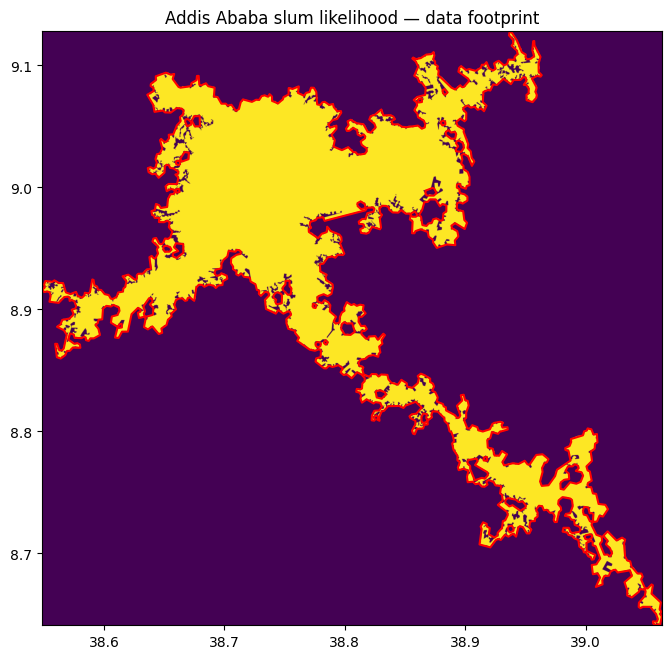

In [ ]:
import numpy as np
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
from shapely.ops import unary_union
import geopandas as gpd

TIF_PATH = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Addis_Ababa/ETH_Addis_Ababa_2022.tif"

with rasterio.open(TIF_PATH) as src:
    band = src.read(1)
    nodata = src.nodata
    transform = src.transform
    crs = src.crs

if nodata is not None:
    valid_mask = band != nodata
else:
    valid_mask = ~np.isnan(band) if band.dtype.kind == "f" else np.ones_like(band, dtype=bool)

polys = [
    shape(geom)
    for geom, val in shapes(valid_mask.astype("uint8"), mask=valid_mask, transform=transform)
]

# Dissolve into a single boundary
boundary = unary_union(polys)

# Smooth: buffer out then in (rounds off pixel-jagged edges), then simplify
pixel_size = transform[0]
SMOOTH_DIST = pixel_size * 20   # increase for a rougher/smoother contour
SIMPLIFY_TOL = pixel_size * 8  # increase to reduce vertex count further

boundary_smooth = boundary.buffer(SMOOTH_DIST).buffer(-SMOOTH_DIST)
boundary_smooth = boundary_smooth.simplify(SIMPLIFY_TOL, preserve_topology=True)

gdf = gpd.GeoDataFrame(geometry=[boundary_smooth], crs=crs)

import matplotlib.pyplot as plt
from rasterio.plot import show

fig, ax = plt.subplots(figsize=(8, 8))
show(band, transform=transform, ax=ax, cmap="viridis")
gdf.boundary.plot(ax=ax, edgecolor="red", linewidth=1.5)
plt.title("Addis Ababa slum likelihood — data footprint")
plt.show()

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
from shapely.ops import unary_union
import geopandas as gpd

CITIES = {
    "Addis_Ababa": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Addis_Ababa/ETH_Addis_Ababa_2022.tif",
    "Douala": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Douala/CMR_Douala_2022.tif",
    "Ibadan": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Ibadan/NGA_Ibadan_2022.tif",
    "Luanda": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Luanda/AGO_Luanda_2022.tif",
    "Lusaka": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Lusaka/ZMB_Lusaka_2022.tif",
}

OUT_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"
os.makedirs(OUT_DIR, exist_ok=True)

for city, tif_path in CITIES.items():
    with rasterio.open(tif_path) as src:
        band = src.read(1)
        nodata = src.nodata
        transform = src.transform
        crs = src.crs

    if nodata is not None:
        valid_mask = band != nodata
    else:
        valid_mask = ~np.isnan(band) if band.dtype.kind == "f" else np.ones_like(band, dtype=bool)

    polys = [
        shape(geom)
        for geom, val in shapes(valid_mask.astype("uint8"), mask=valid_mask, transform=transform)
    ]
    boundary = unary_union(polys)

    pixel_size = transform[0]
    SMOOTH_DIST = pixel_size * 20
    SIMPLIFY_TOL = pixel_size * 8

    boundary_smooth = boundary.buffer(SMOOTH_DIST).buffer(-SMOOTH_DIST)
    boundary_smooth = boundary_smooth.simplify(SIMPLIFY_TOL, preserve_topology=True)

    gdf = gpd.GeoDataFrame(geometry=[boundary_smooth], crs=crs)
    out_path = os.path.join(OUT_DIR, f"{city}_boundary.shp")
    gdf.to_file(out_path)
    print(f"Saved {city} -> {out_path}")


Saved Addis_Ababa -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Addis_Ababa_boundary.shp
Saved Douala -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Douala_boundary.shp
Saved Ibadan -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Ibadan_boundary.shp
Saved Luanda -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Luanda_boundary.shp
Saved Lusaka -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Lusaka_boundary.shp


In [ ]:
import rasterio

CITIES = {
    "Addis_Ababa": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Addis_Ababa/ETH_Addis_Ababa_2022.tif",
    "Douala": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Douala/CMR_Douala_2022.tif",
    "Ibadan": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Ibadan/NGA_Ibadan_2022.tif",
    "Luanda": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Luanda/AGO_Luanda_2022.tif",
    "Lusaka": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Lusaka/ZMB_Lusaka_2022.tif",
}

for city, path in CITIES.items():
    with rasterio.open(path) as src:
        print(city, "res:", src.res, "crs:", src.crs, "nodata:", src.nodata, "shape:", src.shape)

Addis_Ababa res: (8.983152841195215e-05, 8.983152841195215e-05) crs: EPSG:4326 nodata: -99999.0 shape: (5422, 5729)
Douala res: (8.983152841195215e-05, 8.983152841195215e-05) crs: EPSG:4326 nodata: -99999.0 shape: (2269, 3282)
Ibadan res: (8.983152841195215e-05, 8.983152841195215e-05) crs: EPSG:4326 nodata: -99999.0 shape: (3758, 4122)
Luanda res: (8.983152841195215e-05, 8.983152841195215e-05) crs: EPSG:4326 nodata: -99999.0 shape: (3959, 5959)
Lusaka res: (8.983152841195215e-05, 8.983152841195215e-05) crs: EPSG:4326 nodata: -99999.0 shape: (4385, 4066)


In [ ]:
import os
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely.geometry import Point

CITIES = ["Addis_Ababa", "Douala", "Ibadan", "Luanda", "Lusaka"]
BOUNDARY_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"
OUT_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
os.makedirs(OUT_DIR, exist_ok=True)

GRID_SPACING_M = 30

def utm_epsg(lon, lat):
    zone = int((lon + 180) // 6) + 1
    return f"EPSG:{32600 + zone if lat >= 0 else 32700 + zone}"

for city in CITIES:
    boundary_path = os.path.join(BOUNDARY_DIR, f"{city}_boundary.shp")
    gdf = gpd.read_file(boundary_path)
    poly_wgs84 = gdf.geometry.iloc[0]

    centroid = poly_wgs84.centroid
    epsg = utm_epsg(centroid.x, centroid.y)

    gdf_utm = gdf.to_crs(epsg)
    poly_utm = gdf_utm.geometry.iloc[0]
    minx, miny, maxx, maxy = poly_utm.bounds

    xs = np.arange(minx, maxx, GRID_SPACING_M)
    ys = np.arange(miny, maxy, GRID_SPACING_M)
    xx, yy = np.meshgrid(xs, ys)
    pts_utm = gpd.GeoSeries([Point(x, y) for x, y in zip(xx.ravel(), yy.ravel())], crs=epsg)

    inside = pts_utm[pts_utm.within(poly_utm)]
    pts_wgs84 = inside.to_crs("EPSG:4326")

    out_df = pd.DataFrame({
        "grid_point": range(len(pts_wgs84)),
        "longitude": pts_wgs84.x.values,
        "latitude": pts_wgs84.y.values,
    })

    out_path = os.path.join(OUT_DIR, f"{city}_grid_30m.csv")
    out_df.to_csv(out_path, index=False)
    print(f"{city}: {len(out_df)} grid points -> {out_path}")

Addis_Ababa: 651417 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Addis_Ababa_grid_30m.csv
Douala: 267911 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Douala_grid_30m.csv
Ibadan: 711975 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Ibadan_grid_30m.csv
Luanda: 1135164 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Luanda_grid_30m.csv
Lusaka: 739581 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Lusaka_grid_30m.csv


Population

In [ ]:
import os
import numpy as np
import pandas as pd
import rasterio

MIN_VALID_CELLS = 3

CITY_POP_TIFS = {
    "Addis_Ababa": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Addis_Ababa/eth_pop_2024_CN_100m_R2025A_v1.tif",
    "Douala": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Douala/cmr_pop_2024_CN_100m_R2025A_v1.tif",
    "Ibadan": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Ibadan/nga_pop_2024_CN_100m_R2025A_v1.tif",
    "Luanda": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Luanda/ago_pop_2024_CN_100m_R2025A_v1.tif",
    "Lusaka": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Lusaka/zmb_pop_2024_CN_100m_R2025A_v1.tif",
}

GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"

def sample_partial_bilinear(x_coords, y_coords, arr, transform, nodata_mask, min_valid=3):
    inv = ~transform
    cols, rows = inv * (x_coords, y_coords)
    col0 = np.floor(cols - 0.5).astype(int)
    row0 = np.floor(rows - 0.5).astype(int)
    fx = (cols - 0.5) - col0
    fy = (rows - 0.5) - row0
    n_rows, n_cols = arr.shape
    results = np.full(len(x_coords), np.nan, dtype=np.float64)
    n_valid_out = np.zeros(len(x_coords), dtype=np.int8)
    for i in range(len(x_coords)):
        r0, c0 = row0[i], col0[i]
        r1, c1 = r0 + 1, c0 + 1
        if r0 < 0 or c0 < 0 or r1 >= n_rows or c1 >= n_cols:
            continue
        vals = np.array([
            arr[r0, c0], arr[r0, c1],
            arr[r1, c0], arr[r1, c1]
        ])
        valid = ~np.array([
            nodata_mask[r0, c0], nodata_mask[r0, c1],
            nodata_mask[r1, c0], nodata_mask[r1, c1]
        ])
        n_valid = valid.sum()
        n_valid_out[i] = n_valid
        if n_valid < min_valid:
            continue
        wx, wy = fx[i], fy[i]
        weights = np.array([
            (1 - wx) * (1 - wy), wx * (1 - wy),
            (1 - wx) * wy, wx * wy
        ])
        weights = weights * valid
        weights = weights / weights.sum()
        results[i] = np.nansum(vals[valid] * weights[valid])
    return results, n_valid_out

results_log = []
for city, tif_path in CITY_POP_TIFS.items():
    print("=" * 60)
    print("Processing:", city)
    try:
        grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")
        grid_df = pd.read_csv(grid_path)

        with rasterio.open(tif_path) as src:
            arr = src.read(1)
            nodata_val = src.nodata
            nodata_mask = (arr == nodata_val) | np.isnan(arr)
            transform = src.transform

        pop_values, n_valid = sample_partial_bilinear(
            grid_df["longitude"].values, grid_df["latitude"].values,
            arr, transform, nodata_mask, min_valid=MIN_VALID_CELLS
        )
        grid_df["Population"] = pop_values

        grid_df.to_csv(grid_path, index=False)
        out_path = grid_path

        print("Grid points:", len(grid_df))
        print("NaN population:", grid_df["Population"].isna().sum())
        print("Saved:", out_path)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Addis_Ababa
Grid points: 651417
NaN population: 5195
Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Addis_Ababa_grid_30m.csv
Processing: Douala
Grid points: 267911
NaN population: 1487
Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Douala_grid_30m.csv
Processing: Ibadan
Grid points: 711975
NaN population: 18124
Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Ibadan_grid_30m.csv
Processing: Luanda
Grid points: 1135164
NaN population: 9119
Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Luanda_grid_30m.csv
Processing: Lusaka
Grid points: 739581
NaN population: 8243
Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Lusaka_grid_30m.csv
Summary:
Addis_Ababa - success
Douala - success
Ibadan - success
Luanda - success
Lusaka - success


Slum Likelihood

In [ ]:
import os
import numpy as np
import pandas as pd
import rasterio

MIN_VALID_CELLS = 3

CITY_SLUM_TIFS = {
    "Addis_Ababa": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Addis_Ababa/ETH_Addis_Ababa_2022.tif",
    "Douala": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Douala/CMR_Douala_2022.tif",
    "Ibadan": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Ibadan/NGA_Ibadan_2022.tif",
    "Luanda": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Luanda/AGO_Luanda_2022.tif",
    "Lusaka": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Lusaka/ZMB_Lusaka_2022.tif",
}

GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"

def sample_partial_bilinear(x_coords, y_coords, arr, transform, nodata_mask, min_valid=3):
    inv = ~transform
    cols, rows = inv * (x_coords, y_coords)
    col0 = np.floor(cols - 0.5).astype(int)
    row0 = np.floor(rows - 0.5).astype(int)
    fx = (cols - 0.5) - col0
    fy = (rows - 0.5) - row0
    n_rows, n_cols = arr.shape
    results = np.full(len(x_coords), np.nan, dtype=np.float64)
    n_valid_out = np.zeros(len(x_coords), dtype=np.int8)
    for i in range(len(x_coords)):
        r0, c0 = row0[i], col0[i]
        r1, c1 = r0 + 1, c0 + 1
        if r0 < 0 or c0 < 0 or r1 >= n_rows or c1 >= n_cols:
            continue
        vals = np.array([
            arr[r0, c0], arr[r0, c1],
            arr[r1, c0], arr[r1, c1]
        ])
        valid = ~np.array([
            nodata_mask[r0, c0], nodata_mask[r0, c1],
            nodata_mask[r1, c0], nodata_mask[r1, c1]
        ])
        n_valid = valid.sum()
        n_valid_out[i] = n_valid
        if n_valid < min_valid:
            continue
        wx, wy = fx[i], fy[i]
        weights = np.array([
            (1 - wx) * (1 - wy), wx * (1 - wy),
            (1 - wx) * wy, wx * wy
        ])
        weights = weights * valid
        weights = weights / weights.sum()
        results[i] = np.nansum(vals[valid] * weights[valid])
    return results, n_valid_out

def update_slum(city, tif_path):
    grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")
    df = pd.read_csv(grid_path)

    with rasterio.open(tif_path) as src:
        arr = src.read(1)
        nodata_val = src.nodata
        nodata_mask = (arr == nodata_val) | np.isnan(arr)
        transform = src.transform
        left, bottom, right, top = src.bounds

    lon = df["longitude"].values
    lat = df["latitude"].values
    outside_bounds = (lon < left) | (lon > right) | (lat < bottom) | (lat > top)

    values = np.full(len(df), np.nan, dtype=np.float64)
    n_valid_out = np.zeros(len(df), dtype=np.int8)

    if (~outside_bounds).sum() > 0:
        in_values, in_n_valid = sample_partial_bilinear(
            lon[~outside_bounds], lat[~outside_bounds],
            arr, transform, nodata_mask, min_valid=MIN_VALID_CELLS
        )
        values[~outside_bounds] = in_values
        n_valid_out[~outside_bounds] = in_n_valid

    df["Slum_probability"] = values
    df.to_csv(grid_path, index=False)

    n_total = len(df)
    n_outside = outside_bounds.sum()
    n_nan_total = np.isnan(values).sum()
    print(f"  points = {n_total}, outside bounds = {n_outside} ({100*n_outside/n_total:.2f}%), total NaN = {n_nan_total} ({100*n_nan_total/n_total:.2f}%)")

results_log = []
for city, tif_path in CITY_SLUM_TIFS.items():
    print("=" * 60)
    print("Processing:", city)
    try:
        update_slum(city, tif_path)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Addis_Ababa
  points = 651417, outside bounds = 0 (0.00%), total NaN = 61885 (9.50%)
Processing: Douala
  points = 267911, outside bounds = 0 (0.00%), total NaN = 13858 (5.17%)
Processing: Ibadan
  points = 711975, outside bounds = 0 (0.00%), total NaN = 38677 (5.43%)
Processing: Luanda
  points = 1135164, outside bounds = 0 (0.00%), total NaN = 64464 (5.68%)
Processing: Lusaka
  points = 739581, outside bounds = 0 (0.00%), total NaN = 49535 (6.70%)
Summary:
Addis_Ababa - success
Douala - success
Ibadan - success
Luanda - success
Lusaka - success


Night-Time Lights

In [ ]:
# Download necessary libraries
%%capture
! pip install blackmarblepy
! pip install cmocean

In [ ]:
from google.colab import userdata
import os
from blackmarble import BlackMarble

# Pull the token from Colab Secrets
os.environ["BLACKMARBLE_TOKEN"] = userdata.get('BLACKMARBLE_TOKEN')

# Initialize BlackMarble with the bearer token
bearer = os.getenv("BLACKMARBLE_TOKEN")
bm = BlackMarble(token=bearer)

In [ ]:
import rioxarray
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import contextily as cx
import inspect

print(inspect.signature(bm.raster))

(gdf: geopandas.geodataframe.GeoDataFrame, product_id: blackmarble.types.Product, date_range: Union[datetime.date, List[datetime.date]], variable: Optional[str] = None) -> xarray.core.dataset.Dataset


In [ ]:
import rioxarray
import geopandas as gpd
import numpy as np
import os

CITIES = ["Addis_Ababa", "Douala", "Ibadan", "Luanda", "Lusaka"]
YEAR = "2022"

BOUNDARY_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"

def get_utm_epsg(lon, lat):
    zone = int((lon + 180) / 6) + 1
    if lat >= 0:
        return f"EPSG:{32600 + zone}"
    else:
        return f"EPSG:{32700 + zone}"

def generate_ntl(city, year):
    shp_path = f"{BOUNDARY_DIR}/{city}_boundary.shp"
    out_dir = f"/content/drive/MyDrive/Paper_3/Data/Test_cities/NTL/{city}"
    out_path = f"{out_dir}/{city.lower()}_NTL_{year}.tif"

    gdf = gpd.read_file(shp_path)
    centroid = gdf.to_crs("EPSG:4326").union_all().centroid
    utm_epsg = get_utm_epsg(centroid.x, centroid.y)

    gdf_utm = gdf.to_crs(utm_epsg)
    gdf_buffered_utm = gdf_utm.buffer(500)
    gdf_buffered_utm = gpd.GeoDataFrame(geometry=gdf_buffered_utm, crs=utm_epsg)
    gdf_buffered = gdf_buffered_utm.to_crs("EPSG:4326")

    ntl_annual = bm.raster(gdf_buffered, product_id="VNP46A4", date_range=f"{year}-01-01")
    qual_annual = bm.raster(gdf_buffered, product_id="VNP46A4", date_range=f"{year}-01-01", variable="NearNadir_Composite_Snow_Free_Quality")

    ntl_annual = ntl_annual.rio.write_crs("EPSG:4326")

    annual_val = ntl_annual["NearNadir_Composite_Snow_Free"].sel(time=f"{year}-01-01")
    annual_qual = qual_annual["NearNadir_Composite_Snow_Free_Quality"].sel(time=f"{year}-01-01")

    annual_val_masked = annual_val.where(annual_qual == 0)

    os.makedirs(out_dir, exist_ok=True)
    annual_val_masked.rio.to_raster(out_path)

    arr = annual_val_masked.values
    n_total = arr.size
    n_nan = np.isnan(arr).sum()
    print(f"  {year}: UTM zone = {utm_epsg}, total pixels = {n_total}, NaN = {n_nan} ({100*n_nan/n_total:.2f}%)")
    if n_total - n_nan > 0:
        print(f"  {year}: value range = {np.nanmin(arr):.3f} to {np.nanmax(arr):.3f}")
    print(f"  {year}: saved to {out_path}")

results_log = []
for city in CITIES:
    print("=" * 60)
    print("Processing:", city)
    try:
        generate_ntl(city, YEAR)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Addis_Ababa


QUEUEING TASKS | Downloading (79.0 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

PROCESSING TASKS | Downloading (79.0 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

  0%|          | 0.00/79.0M [00:00<?, ?B/s]

COLLECTING RESULTS | Downloading (79.0 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

...

QUEUEING TASKS | Downloading (73.6 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

PROCESSING TASKS | Downloading (73.6 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

COLLECTING RESULTS | Downloading (73.6 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

COLLATING TILES | Processing...:   0%|          | 0/1 [00:00<?, ?date/s]

  2022: UTM zone = EPSG:32735, total pixels = 8730, NaN = 4566 (52.30%)
  2022: value range = 0.000 to 98.571
  2022: saved to /content/drive/MyDrive/Paper_3/Data/Test_cities/NTL/Lusaka/lusaka_NTL_2022.tif
Summary:
Addis_Ababa - success
Douala - success
Ibadan - success
Luanda - success
Lusaka - success


In [ ]:
import rasterio
import pandas as pd
import numpy as np
import os

MIN_VALID_CELLS = 3

CITIES = ["Addis_Ababa", "Douala", "Ibadan", "Luanda", "Lusaka"]
YEAR = "2022"

GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
NTL_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/NTL"

def sample_partial_bilinear(x_coords, y_coords, arr, transform, nodata_mask, min_valid=3):
    inv = ~transform
    cols, rows = inv * (x_coords, y_coords)
    col0 = np.floor(cols - 0.5).astype(int)
    row0 = np.floor(rows - 0.5).astype(int)
    fx = (cols - 0.5) - col0
    fy = (rows - 0.5) - row0
    n_rows, n_cols = arr.shape
    results = np.full(len(x_coords), np.nan, dtype=np.float64)
    n_valid_out = np.zeros(len(x_coords), dtype=np.int8)
    for i in range(len(x_coords)):
        r0, c0 = row0[i], col0[i]
        r1, c1 = r0 + 1, c0 + 1
        if r0 < 0 or c0 < 0 or r1 >= n_rows or c1 >= n_cols:
            continue
        vals = np.array([
            arr[r0, c0], arr[r0, c1],
            arr[r1, c0], arr[r1, c1]
        ])
        valid = ~np.array([
            nodata_mask[r0, c0], nodata_mask[r0, c1],
            nodata_mask[r1, c0], nodata_mask[r1, c1]
        ])
        n_valid = valid.sum()
        n_valid_out[i] = n_valid
        if n_valid < min_valid:
            continue
        wx, wy = fx[i], fy[i]
        weights = np.array([
            (1 - wx) * (1 - wy), wx * (1 - wy),
            (1 - wx) * wy, wx * wy
        ])
        weights = weights * valid
        weights = weights / weights.sum()
        results[i] = np.nansum(vals[valid] * weights[valid])
    return results, n_valid_out

def update_ntl(city, year):
    tif_path = f"{NTL_DIR}/{city}/{city.lower()}_NTL_{year}.tif"
    grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")

    with rasterio.open(tif_path) as src:
        arr = src.read(1)
        nodata_mask = np.isnan(arr)
        transform = src.transform

    df = pd.read_csv(grid_path)
    values, n_valid = sample_partial_bilinear(
        df["longitude"].values, df["latitude"].values,
        arr, transform, nodata_mask, min_valid=MIN_VALID_CELLS
    )
    df["NTL_radiance"] = values
    df.to_csv(grid_path, index=False)
    n_nan = np.isnan(values).sum()
    print(f"  points = {len(df)}, NaN = {n_nan} ({100*n_nan/len(df):.2f}%)")

results_log = []
for city in CITIES:
    print("=" * 60)
    print("Processing:", city)
    try:
        update_ntl(city, YEAR)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Addis_Ababa
  points = 651417, NaN = 0 (0.00%)
Processing: Douala
  points = 267911, NaN = 279 (0.10%)
Processing: Ibadan
  points = 711975, NaN = 0 (0.00%)
Processing: Luanda
  points = 1135164, NaN = 61 (0.01%)
Processing: Lusaka
  points = 739581, NaN = 0 (0.00%)
Summary:
Addis_Ababa - success
Douala - success
Ibadan - success
Luanda - success
Lusaka - success


Proximity to Infrastructure

In [ ]:
%%capture
!pip install osmium pyrosm geopandas shapely --quiet
!apt-get install -y osmium-tool

In [ ]:
import subprocess, os

osh_path = "/content/drive/MyDrive/Paper_3/Data/Test_cities/osh/ethiopia-internal.osh.pbf"

print("=" * 60)
print("STAGE 0: File check")
print("=" * 60)
print(f"Exists: {os.path.exists(osh_path)}")
if os.path.exists(osh_path):
    print(f"Size: {os.path.getsize(osh_path) / (1024*1024):.2f} MB")

print("\n" + "=" * 60)
print("STAGE 0b: What kind of file is this? (osmium fileinfo)")
print("=" * 60)
result = subprocess.run(['osmium', 'fileinfo', osh_path], capture_output=True, text=True)
print(result.stdout)
print(result.stderr)
# Look specifically for "history file: yes/no" in this output —
# if it says "no", time-filter will silently produce nothing, since
# a snapshot .osm.pbf has no history to filter by timestamp.

print("\n" + "=" * 60)
print("STAGE 1: time-filter (single year, 2022 — matches your slum tif)")
print("=" * 60)
out_full = "/content/ethiopia-2022.osm.pbf"
r1 = subprocess.run(
    ['osmium', 'time-filter', osh_path, '2022-01-01T00:00:00Z', '-o', out_full, '--overwrite'],
    capture_output=True, text=True
)
print("stdout:", r1.stdout)
print("stderr:", r1.stderr)
print("returncode:", r1.returncode)
if os.path.exists(out_full):
    print(f"Output size: {os.path.getsize(out_full) / (1024*1024):.2f} MB")

print("\n" + "=" * 60)
print("STAGE 2: tags-filter for roads (w/highway)")
print("=" * 60)
out_roads = "/content/ethiopia-2022-roads.osm.pbf"
r2 = subprocess.run(
    ['osmium', 'tags-filter', out_full, 'w/highway', '-o', out_roads, '--overwrite'],
    capture_output=True, text=True
)
print("stdout:", r2.stdout)
print("stderr:", r2.stderr)
if os.path.exists(out_roads):
    print(f"Output size: {os.path.getsize(out_roads) / (1024*1024):.2f} MB")
    fi = subprocess.run(['osmium', 'fileinfo', '-e', out_roads], capture_output=True, text=True)
    print(fi.stdout)

print("\n" + "=" * 60)
print("STAGE 3: bbox extract for Addis Ababa")
print("=" * 60)
# EDIT: point at your actual Addis boundary file if you have one,
# e.g. /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Addis_Ababa.shp
# Fallback bbox below if no boundary file yet:
ADDIS_BBOX = "38.60,8.80,38.95,9.10"

out_addis_roads = "/content/addis-2022-roads.osm.pbf"
r3 = subprocess.run(
    ['osmium', 'extract', '-b', ADDIS_BBOX, out_roads, '-o', out_addis_roads, '--overwrite'],
    capture_output=True, text=True
)
print("stdout:", r3.stdout)
print("stderr:", r3.stderr)
if os.path.exists(out_addis_roads):
    print(f"Output size: {os.path.getsize(out_addis_roads) / (1024*1024):.2f} MB")

print("\n" + "=" * 60)
print("STAGE 4: export to geojson + count")
print("=" * 60)
out_geojson = "/content/addis-2022-roads.geojson"
r4 = subprocess.run(
    ['osmium', 'export', out_addis_roads, '-o', out_geojson,
     '--geometry-types=linestring', '-f', 'geojson', '--overwrite'],
    capture_output=True, text=True
)
print("stdout:", r4.stdout)
print("stderr:", r4.stderr)

import geopandas as gpd
if os.path.exists(out_geojson):
    gdf = gpd.read_file(out_geojson)
    print(f"\n✅ Final feature count: {len(gdf)}")
    if len(gdf) > 0:
        print(gdf['highway'].value_counts())

STAGE 0: File check
Exists: True
Size: 219.68 MB

STAGE 0b: What kind of file is this? (osmium fileinfo)
File:
  Name: /content/drive/MyDrive/Paper_3/Data/Test_cities/osh/ethiopia-internal.osh.pbf
  Format: PBF
  Compression: none
  Size: 230355880
Header:
  Bounding boxes:
    (32.9672229,3.389192,48.005447,14.916257)
  With history: yes
  Options:
    generator=osmium/1.16.0
    pbf_dense_nodes=true
    pbf_optional_feature_0=Sort.Type_then_ID
    sorting=Type_then_ID



STAGE 1: time-filter (single year, 2022 — matches your slum tif)
stdout: 
stderr: 
returncode: 0
Output size: 73.91 MB

STAGE 2: tags-filter for roads (w/highway)
stdout: 
stderr: 
Output size: 32.92 MB
File:
  Name: /content/ethiopia-2022-roads.osm.pbf
  Format: PBF
  Compression: none
  Size: 34522604
Header:
  Bounding boxes:
    (32.9672229,3.389192,48.005447,14.916257)
  With history: no
  Options:
    generator=osmium/1.14.0
    pbf_dense_nodes=true
    pbf_optional_feature_0=Sort.Type_then_ID
    sorting=Type_

In [ ]:
import subprocess, os, gc
import geopandas as gpd

TIMESTAMP = "2022-01-01T00:00:00Z"

city_country = {
    'Addis_Ababa': 'ethiopia',
    'Douala':      'cameroon',
    'Ibadan':      'nigeria',
    'Luanda':      'angola',
    'Lusaka':      'zambia',
}

osh_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/osh"
boundary_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"
out_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Roads"
os.makedirs(out_dir, exist_ok=True)

def way_count(pbf_path):
    r = subprocess.run(['osmium', 'fileinfo', '-e', pbf_path], capture_output=True, text=True)
    for line in r.stdout.splitlines():
        if 'Number of ways' in line:
            return int(line.split(':')[1].strip())
    return None

results = {}
failures = {}

for city, country in city_country.items():
    print("=" * 60)
    print(f"Processing: {city}  (country: {country})")
    print("=" * 60)

    try:
        osh_path = os.path.join(osh_dir, f"{country}-internal.osh.pbf")
        assert os.path.exists(osh_path), f"Missing raw extract: {osh_path}"

        boundary_path = os.path.join(boundary_dir, f"{city}_boundary.shp")
        assert os.path.exists(boundary_path), f"Missing boundary: {boundary_path}"

        # --- Stage 1: time-filter (reuse per-country output if already done) ---
        out_full = f"/content/{country}-2022.osm.pbf"
        if not os.path.exists(out_full):
            r1 = subprocess.run(['osmium', 'time-filter', osh_path, TIMESTAMP,
                                  '-o', out_full, '--overwrite'], capture_output=True, text=True)
            assert r1.returncode == 0, f"time-filter failed: {r1.stderr}"
        wc1 = way_count(out_full)
        print(f"  Stage 1 (time-filter): {wc1} ways")
        assert wc1 and wc1 > 0, "Stage 1 produced zero ways"

        # --- Stage 2: tags-filter (reuse per-country output if already done) ---
        out_roads = f"/content/{country}-2022-roads.osm.pbf"
        if not os.path.exists(out_roads):
            r2 = subprocess.run(['osmium', 'tags-filter', out_full, 'w/highway',
                                  '-o', out_roads, '--overwrite'], capture_output=True, text=True)
            assert r2.returncode == 0, f"tags-filter failed: {r2.stderr}"
        wc2 = way_count(out_roads)
        print(f"  Stage 2 (tags-filter): {wc2} ways")
        assert wc2 and wc2 > 0, "Stage 2 produced zero ways"

        # --- Stage 3: boundary bbox ---
        city_gdf = gpd.read_file(boundary_path).to_crs('EPSG:4326')
        minx, miny, maxx, maxy = city_gdf.total_bounds
        bbox_str = f"{minx},{miny},{maxx},{maxy}"
        print(f"  Boundary bbox: {bbox_str}")

        # --- Stage 4: bbox extract ---
        out_city_pbf = os.path.join(out_dir, f"{city}-2022-roads.osm.pbf")
        r3 = subprocess.run(['osmium', 'extract', '-b', bbox_str, out_roads,
                              '-o', out_city_pbf, '--overwrite'], capture_output=True, text=True)
        assert r3.returncode == 0, f"bbox extract failed: {r3.stderr}"
        wc3 = way_count(out_city_pbf)
        print(f"  Stage 4 (bbox extract): {wc3} ways")
        assert wc3 and wc3 > 0, "Stage 4 produced zero ways"

        # --- Stage 5: export to geojson ---
        out_geojson = os.path.join(out_dir, f"{city}-2022-roads.geojson")
        r4 = subprocess.run(['osmium', 'export', out_city_pbf, '-o', out_geojson,
                              '--geometry-types=linestring', '-f', 'geojson', '--overwrite'],
                             capture_output=True, text=True)
        assert r4.returncode == 0, f"export failed: {r4.stderr}"

        # --- Stage 6: precise clip + save ---
        gdf = gpd.read_file(out_geojson)
        clipped = gpd.clip(gdf, city_gdf)
        print(f"  Stage 6 (precise clip): {len(gdf)} in bbox → {len(clipped)} after clip")
        assert len(clipped) > 0, "Zero features after precise clip"

        clipped_path = os.path.join(out_dir, f"{city}-2022-roads-clipped.geojson")
        clipped.to_file(clipped_path, driver='GeoJSON')

        print(f"  ✅ {city} SUCCESS — {len(clipped)} road features, {clipped['highway'].nunique()} classes")
        results[city] = clipped

        del gdf, clipped
        gc.collect()

    except AssertionError as e:
        print(f"  ❌ {city} FAILED: {e}")
        failures[city] = str(e)
    except Exception as e:
        print(f"  ❌ {city} UNEXPECTED ERROR: {e}")
        failures[city] = str(e)

    print()

print("=" * 60)
print("FINAL SUMMARY")
print("=" * 60)
for city in city_country:
    if city in results:
        print(f"✅ {city}: {len(results[city])} features")
    else:
        print(f"❌ {city}: FAILED — {failures.get(city, 'unknown')}")

Processing: Addis_Ababa  (country: ethiopia)
  Stage 1 (time-filter): 1118213 ways
  Stage 2 (tags-filter): 350392 ways
  Boundary bbox: 38.5485075956,8.6408968414,39.0631502984,9.1278693682
  Stage 4 (bbox extract): 63449 ways
  Stage 6 (precise clip): 63447 in bbox → 55439 after clip
  ✅ Addis_Ababa SUCCESS — 55439 road features, 22 classes

Processing: Douala  (country: cameroon)
  Stage 1 (time-filter): 3505871 ways
  Stage 2 (tags-filter): 233151 ways
  Boundary bbox: 9.55969347064,3.95977589592,9.85433689898,4.1635994451
  Stage 4 (bbox extract): 16489 ways
  Stage 6 (precise clip): 16489 in bbox → 15345 after clip
  ✅ Douala SUCCESS — 15345 road features, 16 classes

Processing: Ibadan  (country: nigeria)
  Stage 1 (time-filter): 9090393 ways
  Stage 2 (tags-filter): 1430264 ways
  Boundary bbox: 3.73043594563,7.25757901193,4.10071730009,7.59498415828
  Stage 4 (bbox extract): 51803 ways
  Stage 6 (precise clip): 51803 in bbox → 49641 after clip
  ✅ Ibadan SUCCESS — 49641 road f

In [ ]:
import subprocess, os, gc
import geopandas as gpd

TIMESTAMP = "2024-01-01T00:00:00Z"
YEAR = "2024"

city_country = {
    'Addis_Ababa': 'ethiopia',
    'Douala':      'cameroon',
    'Ibadan':      'nigeria',
    'Luanda':      'angola',
    'Lusaka':      'zambia',
}

osh_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/osh"
boundary_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"
out_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Roads"
os.makedirs(out_dir, exist_ok=True)

def way_count(pbf_path):
    r = subprocess.run(['osmium', 'fileinfo', '-e', pbf_path], capture_output=True, text=True)
    for line in r.stdout.splitlines():
        if 'Number of ways' in line:
            return int(line.split(':')[1].strip())
    return None

results = {}
failures = {}

for city, country in city_country.items():
    print("=" * 60)
    print(f"Processing: {city}  (country: {country})")
    print("=" * 60)

    try:
        osh_path = os.path.join(osh_dir, f"{country}-internal.osh.pbf")
        assert os.path.exists(osh_path), f"Missing raw extract: {osh_path}"

        boundary_path = os.path.join(boundary_dir, f"{city}_boundary.shp")
        assert os.path.exists(boundary_path), f"Missing boundary: {boundary_path}"

        out_full = f"/content/{country}-{YEAR}.osm.pbf"
        if not os.path.exists(out_full):
            r1 = subprocess.run(['osmium', 'time-filter', osh_path, TIMESTAMP,
                                  '-o', out_full, '--overwrite'], capture_output=True, text=True)
            assert r1.returncode == 0, f"time-filter failed: {r1.stderr}"
        wc1 = way_count(out_full)
        print(f"  Stage 1 (time-filter): {wc1} ways")
        assert wc1 and wc1 > 0, "Stage 1 produced zero ways"

        out_roads = f"/content/{country}-{YEAR}-roads.osm.pbf"
        if not os.path.exists(out_roads):
            r2 = subprocess.run(['osmium', 'tags-filter', out_full, 'w/highway',
                                  '-o', out_roads, '--overwrite'], capture_output=True, text=True)
            assert r2.returncode == 0, f"tags-filter failed: {r2.stderr}"
        wc2 = way_count(out_roads)
        print(f"  Stage 2 (tags-filter): {wc2} ways")
        assert wc2 and wc2 > 0, "Stage 2 produced zero ways"

        city_gdf = gpd.read_file(boundary_path).to_crs('EPSG:4326')
        minx, miny, maxx, maxy = city_gdf.total_bounds
        bbox_str = f"{minx},{miny},{maxx},{maxy}"
        print(f"  Boundary bbox: {bbox_str}")

        out_city_pbf = os.path.join(out_dir, f"{city}-{YEAR}-roads.osm.pbf")
        r3 = subprocess.run(['osmium', 'extract', '-b', bbox_str, out_roads,
                              '-o', out_city_pbf, '--overwrite'], capture_output=True, text=True)
        assert r3.returncode == 0, f"bbox extract failed: {r3.stderr}"
        wc3 = way_count(out_city_pbf)
        print(f"  Stage 4 (bbox extract): {wc3} ways")
        assert wc3 and wc3 > 0, "Stage 4 produced zero ways"

        out_geojson = os.path.join(out_dir, f"{city}-{YEAR}-roads.geojson")
        r4 = subprocess.run(['osmium', 'export', out_city_pbf, '-o', out_geojson,
                              '--geometry-types=linestring', '-f', 'geojson', '--overwrite'],
                             capture_output=True, text=True)
        assert r4.returncode == 0, f"export failed: {r4.stderr}"

        gdf = gpd.read_file(out_geojson)
        clipped = gpd.clip(gdf, city_gdf)
        print(f"  Stage 6 (precise clip): {len(gdf)} in bbox → {len(clipped)} after clip")
        assert len(clipped) > 0, "Zero features after precise clip"

        clipped_path = os.path.join(out_dir, f"{city}-{YEAR}-roads-clipped.geojson")
        clipped.to_file(clipped_path, driver='GeoJSON')

        print(f"  ✅ {city} SUCCESS — {len(clipped)} road features, {clipped['highway'].nunique()} classes")
        results[city] = clipped

        del gdf, clipped
        gc.collect()

    except AssertionError as e:
        print(f"  ❌ {city} FAILED: {e}")
        failures[city] = str(e)
    except Exception as e:
        print(f"  ❌ {city} UNEXPECTED ERROR: {e}")
        failures[city] = str(e)

    print()

print("=" * 60)
print("FINAL SUMMARY")
print("=" * 60)
for city in city_country:
    if city in results:
        print(f"✅ {city}: {len(results[city])} features")
    else:
        print(f"❌ {city}: FAILED — {failures.get(city, 'unknown')}")

Processing: Addis_Ababa  (country: ethiopia)
  Stage 1 (time-filter): 1640329 ways
  Stage 2 (tags-filter): 408593 ways
  Boundary bbox: 38.5485075956,8.6408968414,39.0631502984,9.1278693682
  Stage 4 (bbox extract): 66720 ways
  Stage 6 (precise clip): 66702 in bbox → 58304 after clip
  ✅ Addis_Ababa SUCCESS — 58304 road features, 22 classes

Processing: Douala  (country: cameroon)
  Stage 1 (time-filter): 3834713 ways
  Stage 2 (tags-filter): 268717 ways
  Boundary bbox: 9.55969347064,3.95977589592,9.85433689898,4.1635994451
  Stage 4 (bbox extract): 17324 ways
  Stage 6 (precise clip): 17324 in bbox → 16016 after clip
  ✅ Douala SUCCESS — 16016 road features, 16 classes

Processing: Ibadan  (country: nigeria)
  Stage 1 (time-filter): 13402463 ways
  Stage 2 (tags-filter): 1597873 ways
  Boundary bbox: 3.73043594563,7.25757901193,4.10071730009,7.59498415828
  Stage 4 (bbox extract): 54851 ways
  Stage 6 (precise clip): 54851 in bbox → 52448 after clip
  ✅ Ibadan SUCCESS — 52448 road 

In [ ]:
import geopandas as gpd
import pandas as pd
import os

CITIES = ["Addis_Ababa", "Douala", "Ibadan", "Luanda", "Lusaka"]
YEAR = "2024"

ROADS_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Roads"
GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"

PRIMARY_TAGS = {'primary', 'trunk', 'trunk_link', 'primary_link', 'motorway', 'motorway_link'}
SECONDARY_TAGS = {'secondary', 'secondary_link'}
TERTIARY_TAGS = {'tertiary', 'residential', 'service', 'unclassified', 'tertiary_link', 'living_street'}
ARTERIAL_TAGS = PRIMARY_TAGS | SECONDARY_TAGS

def update_road_distances(city, year):
    roads_path = os.path.join(ROADS_DIR, f"{city}-{year}-roads-clipped.geojson")
    grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")

    roads = gpd.read_file(roads_path)

    arterial = roads[roads['highway'].isin(ARTERIAL_TAGS)][['geometry']]
    tertiary = roads[roads['highway'].isin(TERTIARY_TAGS)][['geometry']]

    print(f"  arterial features: {len(arterial)}, tertiary features: {len(tertiary)}")
    unclassified = set(roads['highway'].unique()) - ARTERIAL_TAGS - TERTIARY_TAGS
    if unclassified:
        print(f"  ⚠️ unclassified highway tags present (dropped): {sorted(unclassified)}")

    utm_crs = roads.estimate_utm_crs()
    arterial_proj = arterial.to_crs(utm_crs) if len(arterial) > 0 else None
    tertiary_proj = tertiary.to_crs(utm_crs) if len(tertiary) > 0 else None

    df = pd.read_csv(grid_path)
    grid_gdf = gpd.GeoDataFrame(
        df, geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs="EPSG:4326"
    ).to_crs(utm_crs)

    if arterial_proj is not None and len(arterial_proj) > 0:
        arterial_joined = gpd.sjoin_nearest(grid_gdf, arterial_proj, distance_col="Arterial_road_dist_m", how="left")
        arterial_joined = arterial_joined[~arterial_joined.index.duplicated(keep='first')]
        df["Arterial_road_dist_m"] = arterial_joined["Arterial_road_dist_m"].values
    else:
        df["Arterial_road_dist_m"] = float("nan")

    if tertiary_proj is not None and len(tertiary_proj) > 0:
        tertiary_joined = gpd.sjoin_nearest(grid_gdf, tertiary_proj, distance_col="Tertiary_road_dist_m", how="left")
        tertiary_joined = tertiary_joined[~tertiary_joined.index.duplicated(keep='first')]
        df["Tertiary_road_dist_m"] = tertiary_joined["Tertiary_road_dist_m"].values
    else:
        df["Tertiary_road_dist_m"] = float("nan")

    df.to_csv(grid_path, index=False)

    print(f"  points = {len(df)}, "
          f"Arterial NaN = {df['Arterial_road_dist_m'].isna().sum()}, "
          f"Tertiary NaN = {df['Tertiary_road_dist_m'].isna().sum()}")

results_log = []
for city in CITIES:
    print("=" * 60)
    print("Processing:", city)
    try:
        update_road_distances(city, YEAR)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Addis_Ababa
  arterial features: 4621, tertiary features: 52287
  ⚠️ unclassified highway tags present (dropped): ['construction', 'footway', 'path', 'pedestrian', 'platform', 'raceway', 'steps', 'track']
  points = 651417, Arterial NaN = 0, Tertiary NaN = 0
Processing: Douala
  arterial features: 800, tertiary features: 14989
  ⚠️ unclassified highway tags present (dropped): ['footway', 'path', 'pedestrian', 'steps', 'track']
  points = 267911, Arterial NaN = 0, Tertiary NaN = 0
Processing: Ibadan
  arterial features: 675, tertiary features: 51196
  ⚠️ unclassified highway tags present (dropped): ['construction', 'cycleway', 'footway', 'path', 'pedestrian', 'track']
  points = 711975, Arterial NaN = 0, Tertiary NaN = 0
Processing: Luanda
  arterial features: 3058, tertiary features: 87814
  ⚠️ unclassified highway tags present (dropped): ['bridleway', 'construction', 'corridor', 'cycleway', 'footway', 'path', 'pedestrian', 'raceway', 'steps', 'track']
  points = 1135164, A

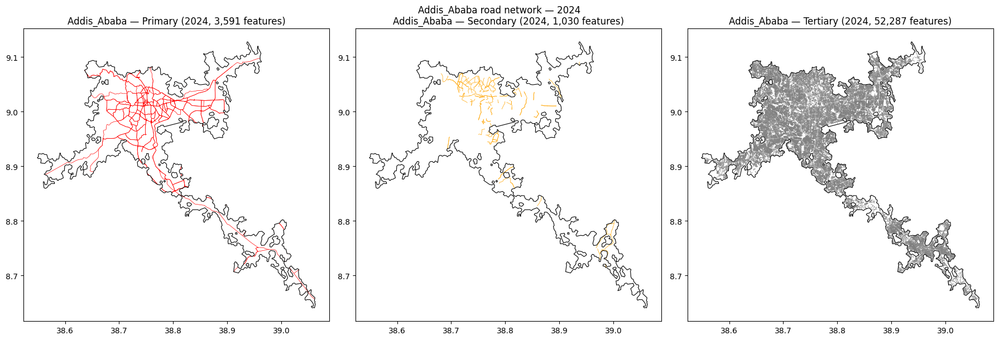

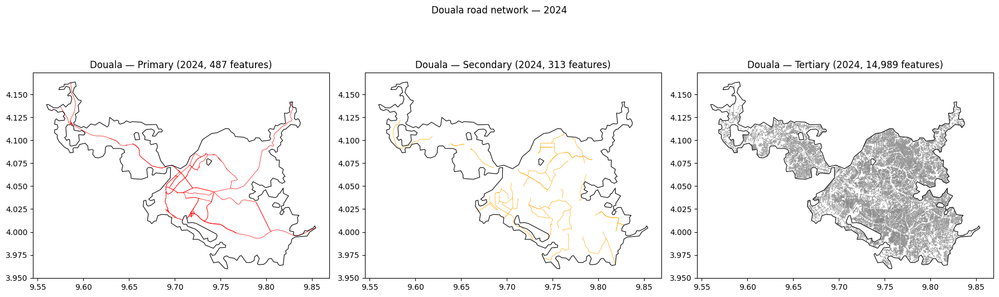

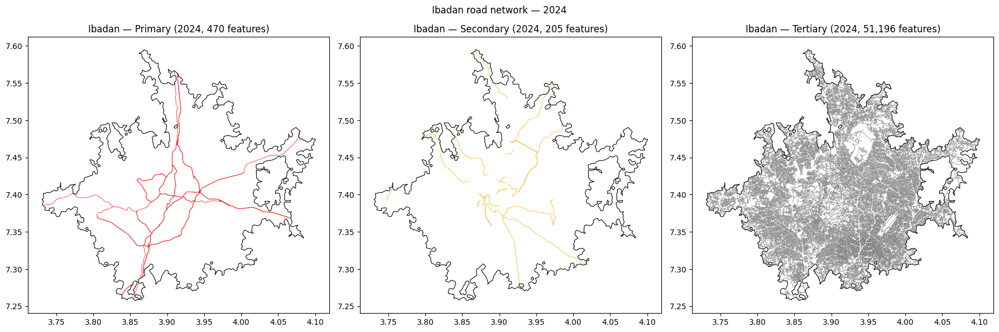

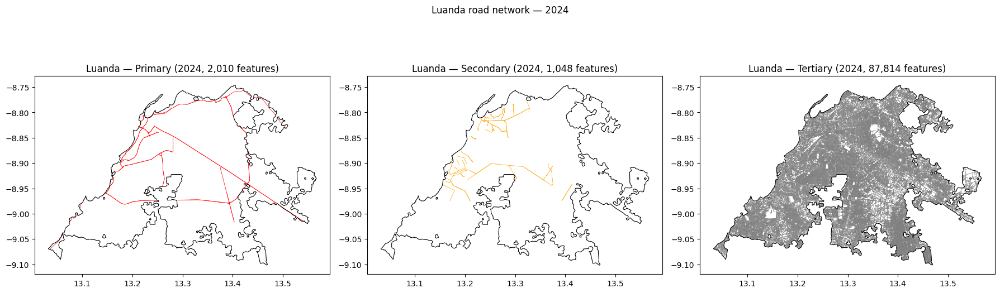

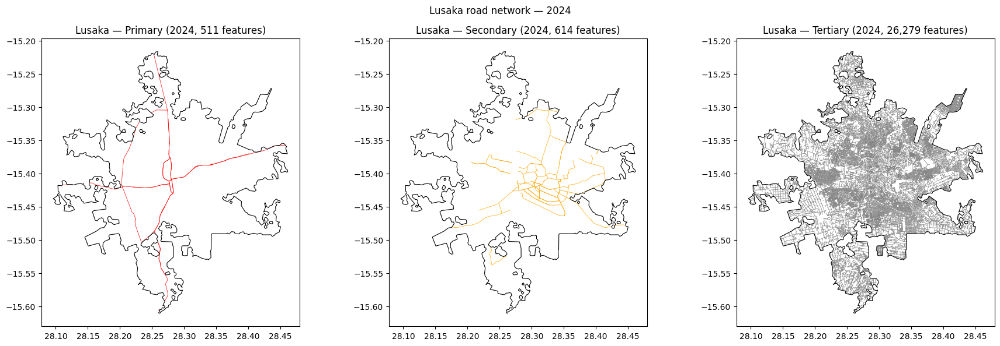

NameError: name 'EOF' is not defined

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

CITIES = ["Addis_Ababa", "Douala", "Ibadan", "Luanda", "Lusaka"]
YEAR = "2024"

ROADS_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Roads"
BOUNDARY_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"

PRIMARY_TAGS = {'primary', 'trunk', 'trunk_link', 'primary_link', 'motorway', 'motorway_link'}
SECONDARY_TAGS = {'secondary', 'secondary_link'}
TERTIARY_TAGS = {'tertiary', 'residential', 'service', 'unclassified', 'tertiary_link', 'living_street'}

class_tags = {'primary': PRIMARY_TAGS, 'secondary': SECONDARY_TAGS, 'tertiary': TERTIARY_TAGS}
colors = {'primary': 'red', 'secondary': 'orange', 'tertiary': 'gray'}

for city in CITIES:
    roads_path = f"{ROADS_DIR}/{city}-{YEAR}-roads-clipped.geojson"
    boundary_path = f"{BOUNDARY_DIR}/{city}_boundary.shp"

    roads = gpd.read_file(roads_path)
    boundary = gpd.read_file(boundary_path).to_crs('EPSG:4326')

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, cls in zip(axes, class_tags):
        subset = roads[roads['highway'].isin(class_tags[cls])]
        subset.plot(ax=ax, linewidth=0.5, color=colors[cls])
        boundary.boundary.plot(ax=ax, linewidth=0.8, color='black')
        ax.set_title(f'{city} — {cls.capitalize()} ({YEAR}, {len(subset):,} features)')
    plt.suptitle(f'{city} road network — {YEAR}')
    plt.tight_layout()
    plt.show()

In [ ]:
import subprocess
import geopandas as gpd
import os

YEAR = "2024"
TIMESTAMP = "2024-01-01T00:00:00Z"

city_country = {
    'Addis_Ababa': 'ethiopia',
    'Douala':      'cameroon',
    'Ibadan':      'nigeria',
    'Luanda':      'angola',
    'Lusaka':      'zambia',
}

osh_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/osh"
boundary_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"

tag_filter = [
    'amenity=hospital,townhall,courthouse,embassy,consulate,police,fire_station,post_office,customs,marketplace,market,school,college,university,water_point,bank,bus_station',
    'office=government,administrative,diplomatic,ngo,political_party,police',
    'building=government,public,civic,office,hospital,police,school,college,university,commercial,retail,market',
    'government',
    'landuse=institutional,military,commercial,retail,education,reservoir,basin',
    'man_made=water_treatment_plant,water_works,wastewater_treatment_plant,pumping_station,water_tower,reservoir,storage_tank,mast,tower',
    'power=substation,station',
    'shop=mall,supermarket,department_store',
]

def categorize(row):
    amenity = row.get('amenity')
    office = row.get('office')
    building = row.get('building')
    power = row.get('power')
    man_made = row.get('man_made')
    shop = row.get('shop')

    if amenity in ['school', 'university', 'college'] or building in ['school', 'university', 'college']:
        return 'Education'
    if amenity == 'hospital' or building == 'hospital':
        return 'Health'
    if amenity in ['police', 'courthouse']:
        return 'Security_Justice'
    if amenity in ['townhall', 'bank'] or office == 'government' or building == 'government' or office == 'administrative':
        return 'Administration'
    if amenity == 'embassy':
        return 'Diplomatic'
    if amenity == 'fire_station':
        return 'Emergency_Services'
    if amenity == 'post_office':
        return 'Postal_Civic'
    if power in ['substation', 'station'] or man_made in ['water_works', 'water_tower', 'storage_tank', 'tower']:
        return 'Utilities'
    if amenity == 'bus_station':
        return 'Transport'
    if amenity == 'marketplace' or shop in ['mall', 'supermarket', 'department_store']:
        return 'Marketplace'
    return None

ALL_CATEGORIES = ['Education', 'Health', 'Security_Justice', 'Administration', 'Diplomatic',
                   'Emergency_Services', 'Postal_Civic', 'Utilities', 'Transport', 'Marketplace']

out_root = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Infrastructure"

results_log = []
for city, country in city_country.items():
    print("=" * 60)
    print("Processing:", city)
    try:
        osh_path = os.path.join(osh_dir, f"{country}-internal.osh.pbf")
        assert os.path.exists(osh_path), f"Missing raw extract: {osh_path}"

        boundary_path = os.path.join(boundary_dir, f"{city}_boundary.shp")
        city_gdf = gpd.read_file(boundary_path).to_crs('EPSG:4326')
        minx, miny, maxx, maxy = city_gdf.total_bounds
        bbox_str = f"{minx},{miny},{maxx},{maxy}"

        out_dir = os.path.join(out_root, city)
        os.makedirs(out_dir, exist_ok=True)

        full_path = f'/content/{country}-{YEAR}.osm.pbf'
        infra_path = f'/content/{country}-{YEAR}-infra.osm.pbf'
        clip_path = f'/content/{city}-{YEAR}-infra.osm.pbf'
        geojson_path = f'/content/{city}-{YEAR}-infra.geojson'

        if not os.path.exists(full_path):
            subprocess.run(['osmium', 'time-filter', osh_path, TIMESTAMP, '-o', full_path, '--overwrite'], check=True)
        subprocess.run(['osmium', 'tags-filter', full_path] + tag_filter + ['-o', infra_path, '--overwrite'], check=True)
        subprocess.run(['osmium', 'extract', '-b', bbox_str, infra_path, '-o', clip_path, '--overwrite'], check=True)
        subprocess.run(['osmium', 'export', clip_path, '-o', geojson_path, '--geometry-types=point,polygon', '-f', 'geojson', '--overwrite'], check=True)

        gdf = gpd.read_file(geojson_path)
        clipped = gpd.clip(gdf, city_gdf)
        clipped = clipped[clipped.get('building') != 'yes']

        clipped['category'] = clipped.apply(categorize, axis=1)
        categorized = clipped[clipped['category'].notna()].copy()

        non_point = categorized.geometry.type != 'Point'
        if non_point.any():
            utm_crs = categorized.estimate_utm_crs()
            proj = categorized.to_crs(utm_crs)
            proj.loc[non_point, 'geometry'] = proj.loc[non_point, 'geometry'].centroid
            categorized = proj.to_crs('EPSG:4326')

        print(f"{city} ({YEAR}):")
        print(categorized['category'].value_counts())
        present = set(categorized['category'].unique())
        missing = set(ALL_CATEGORIES) - present
        if missing:
            print(f"  Structurally empty: {missing}")

        out_path = f'{out_dir}/{city}_infrastructure_{YEAR}.geojson'
        categorized.to_file(out_path, driver='GeoJSON')
        print(f"  Saved: {out_path} ({len(categorized)} features)")

        os.remove(infra_path)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Addis_Ababa
Addis_Ababa (2024):
category
Administration        1033
Education              532
Marketplace            216
Health                 144
Utilities               88
Security_Justice        74
Transport               47
Postal_Civic            28
Emergency_Services       8
Diplomatic               2
Name: count, dtype: int64
  Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Infrastructure/Addis_Ababa/Addis_Ababa_infrastructure_2024.geojson (2172 features)
Processing: Douala
Douala (2024):
category
Education             750
Administration        135
Marketplace            52
Utilities              43
Health                 36
Security_Justice       17
Transport               9
Postal_Civic            4
Emergency_Services      1
Name: count, dtype: int64
  Structurally empty: {'Diplomatic'}
  Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Infrastructure/Douala/Douala_infrastructure_2024.geojson (1047 features)
Processing: Ibadan
Ibadan (2024):
categor

In [ ]:
import geopandas as gpd
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree
from pyproj import Transformer
import os

CITIES = ["Addis_Ababa", "Douala", "Ibadan", "Luanda", "Lusaka"]
YEAR = "2024"

INFRA_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Infrastructure"
GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"

def update_infrastructure_distance(city, year):
    geojson_path = f"{INFRA_DIR}/{city}/{city}_infrastructure_{year}.geojson"
    grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")

    infra = gpd.read_file(geojson_path)
    utm_crs = infra.estimate_utm_crs()
    infra_proj = infra.to_crs(utm_crs)
    transformer = Transformer.from_crs("EPSG:4326", utm_crs, always_xy=True)

    categories = sorted(infra_proj['category'].dropna().unique().tolist())

    df = pd.read_csv(grid_path)
    x_proj, y_proj = transformer.transform(df["longitude"].values, df["latitude"].values)
    grid_coords = np.column_stack([x_proj, y_proj])

    dist_matrix = pd.DataFrame(index=df.index)
    for cat in categories:
        cat_points = infra_proj[infra_proj['category'] == cat]
        if len(cat_points) == 0:
            continue
        cat_coords = np.column_stack([cat_points.geometry.x, cat_points.geometry.y])
        tree = cKDTree(cat_coords)
        dists, _ = tree.query(grid_coords, k=1)
        dist_matrix[cat] = dists

    minmax_norm = (dist_matrix - dist_matrix.min()) / (dist_matrix.max() - dist_matrix.min())
    df["Infra_distance"] = minmax_norm.mean(axis=1).values

    df.to_csv(grid_path, index=False)
    n_nan = df["Infra_distance"].isna().sum()
    print(f"  points = {len(df)}, categories used = {len(categories)} {categories}, NaN = {n_nan} ({100*n_nan/len(df):.2f}%)")

results_log = []
for city in CITIES:
    print("=" * 60)
    print("Processing:", city)
    try:
        update_infrastructure_distance(city, YEAR)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Addis_Ababa
  points = 651417, categories used = 10 ['Administration', 'Diplomatic', 'Education', 'Emergency_Services', 'Health', 'Marketplace', 'Postal_Civic', 'Security_Justice', 'Transport', 'Utilities'], NaN = 0 (0.00%)
Processing: Douala
  points = 267911, categories used = 9 ['Administration', 'Education', 'Emergency_Services', 'Health', 'Marketplace', 'Postal_Civic', 'Security_Justice', 'Transport', 'Utilities'], NaN = 0 (0.00%)
Processing: Ibadan
  points = 711975, categories used = 8 ['Administration', 'Education', 'Emergency_Services', 'Health', 'Marketplace', 'Postal_Civic', 'Security_Justice', 'Utilities'], NaN = 0 (0.00%)
Processing: Luanda
  points = 1135164, categories used = 9 ['Administration', 'Education', 'Emergency_Services', 'Health', 'Marketplace', 'Postal_Civic', 'Security_Justice', 'Transport', 'Utilities'], NaN = 0 (0.00%)
Processing: Lusaka
  points = 739581, categories used = 9 ['Administration', 'Education', 'Emergency_Services', 'Health', 'Marke

Additional Cities

In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities"

CITIES = [
    "Yaoundé", "Kumasi", "Brazzaville", "Lome", "Kano", "Cape Town", "Bamako",
    "Ouagadougou", "Durban", "Harare", "Benin City", "Kigali", "Lilongwe",
    "Khartoum", "Mogadishu", "Cotonou", "N'Djamena", "Abuja", "Conakry",
    "Niamey", "Libreville", "Mombasa", "Tamale", "Bissau", "Windhoek",
    "Gaborone", "Djibouti City", "Banjul", "Lubumbashi", "Mwanza", "Monrovia",
    "Garoua", "Dar es Salaam", "Juba", "Antananarivo", "Bangui", "Goma",
]

for city in CITIES:
    folder = os.path.join(BASE_DIR, city)
    print("=" * 60)
    print(city, "->", folder)
    if not os.path.isdir(folder):
        print("  FOLDER NOT FOUND")
        continue
    files = os.listdir(folder)
    if not files:
        print("  EMPTY FOLDER")
        continue
    for f in files:
        print("  -", f)

Yaoundé -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Yaoundé
  FOLDER NOT FOUND
Kumasi -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Kumasi
  - GHA_Kumasi_2022.tif
Brazzaville -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Brazzaville
  - COG_Brazzaville_2022.tif
Lome -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Lome
  - TGO_Lome_Aflao_TGO_2022.tif
Kano -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Kano
  - NGA_Kano_2022.tif
Cape Town -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Cape Town
  FOLDER NOT FOUND
Bamako -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Bamako
  - MLI_Bamako_2022.tif
Ouagadougou -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Ouagadougou
  - BFA_Ouagadougou_2022.tif
Durban -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Durban
  - ZAF_Durban_2022.tif
Harare -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Harare
  - ZWE_Harare_2022.tif
Benin City -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Benin City
  FOLDER NO

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
from shapely.ops import unary_union
import geopandas as gpd

BASE_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities"
OUT_DIR = os.path.join(BASE_DIR, "Boundaries")
os.makedirs(OUT_DIR, exist_ok=True)

CITY_TIFS = {
    "Yaounde":        "Yaounde/CMR_Yaounde_2022.tif",
    "Kumasi":         "Kumasi/GHA_Kumasi_2022.tif",
    "Brazzaville":    "Brazzaville/COG_Brazzaville_2022.tif",
    "Lome":           "Lome/TGO_Lome_Aflao_TGO_2022.tif",
    "Kano":           "Kano/NGA_Kano_2022.tif",
    "Cape_Town":      "Cape_town/ZAF_Cape_2022.tif",
    "Bamako":         "Bamako/MLI_Bamako_2022.tif",
    "Ouagadougou":    "Ouagadougou/BFA_Ouagadougou_2022.tif",
    "Durban":         "Durban/ZAF_Durban_2022.tif",
    "Harare":         "Harare/ZWE_Harare_2022.tif",
    "Benin_City":     "Benin_city/NGA_Benin_2022.tif",
    "Kigali":         "Kigali/RWA_Kigali_2022.tif",
    "Lilongwe":       "Lilongwe/MWI_Lilongwe_2022.tif",
    "Khartoum":       "Khartoum/SDN_Khartum_2022.tif",
    "Mogadishu":      "Mogadishu/SOM_Mogadisho_2022.tif",
    "Cotonou":        "Cotonou/BEN_Cotonou_2022.tif",
    "NDjamena":       "NDjamena/TCD_Ndjamena_Kousseri_TCD_2022.tif",
    "Abuja":          "Abuja/NGA_Abuja_2022.tif",
    "Conakry":        "Conakry/GIN_Conakry_2022.tif",
    "Niamey":         "Niamey/NER_Niamey_2022.tif",
    "Libreville":     "Libreville/GAB_Libreville_2022.tif",
    "Mombasa":        "Mombasa/KEN_Mombasa_2022.tif",
    "Tamale":         "Tamale/GHA_Tamale_2022.tif",
    "Bissau":         "Bissau/GNB_Bissau_2022.tif",
    "Windhoek":       "Windhoek/NAM_Windhoek_2022.tif",
    "Gaborone":       "Gaborone/BWA_Gaborone_2022.tif",
    "Djibouti_City":  "Djibouti_city/DJI_Djibouti_2022.tif",
    "Lubumbashi":     "Lubumbashi/COD_Lubumbashi_2022.tif",
    "Mwanza":         "Mwanza/TZA_Mwanza_2022.tif",
    "Monrovia":       "Monrovia/LBR_Monrovia_2022.tif",
    "Garoua":         "Garoua/CMR_Garoua_2022.tif",
    "Dar_es_Salaam":  "Dar_es_Salaam/TZA_Dar_es_Salaam_2022.tif",
    "Juba":           "Juba/SSD_Juba_2022.tif",
    "Antananarivo":   "Antananarivo/MDG_Antananarivo_2022.tif",
    "Bangui":         "Bangui/CAF_Bangui_2022.tif",
    "Goma":           "Goma/COD_Goma_2022.tif",
    # "Banjul": SKIPPED — folder empty, no tif uploaded yet
}

results_log = []
for city, rel_path in CITY_TIFS.items():
    print("=" * 60)
    print("Processing:", city)
    try:
        tif_path = os.path.join(BASE_DIR, rel_path)

        with rasterio.open(tif_path) as src:
            band = src.read(1)
            nodata = src.nodata
            transform = src.transform
            crs = src.crs

        if nodata is not None:
            valid_mask = band != nodata
        else:
            valid_mask = ~np.isnan(band) if band.dtype.kind == "f" else np.ones_like(band, dtype=bool)

        polys = [
            shape(geom)
            for geom, val in shapes(valid_mask.astype("uint8"), mask=valid_mask, transform=transform)
        ]
        boundary = unary_union(polys)

        pixel_size = transform[0]
        SMOOTH_DIST = pixel_size * 20
        SIMPLIFY_TOL = pixel_size * 8

        boundary_smooth = boundary.buffer(SMOOTH_DIST).buffer(-SMOOTH_DIST)
        boundary_smooth = boundary_smooth.simplify(SIMPLIFY_TOL, preserve_topology=True)

        gdf = gpd.GeoDataFrame(geometry=[boundary_smooth], crs=crs)
        out_path = os.path.join(OUT_DIR, f"{city}_boundary.shp")
        gdf.to_file(out_path)
        print(f"  ✅ Saved: {out_path}")
        results_log.append((city, "success"))
    except Exception as e:
        print(f"  ❌ FAILED: {e}")
        results_log.append((city, f"failed: {e}"))

results_log.append(("Banjul", "skipped: folder empty, tif not yet uploaded"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Yaounde


  ✅ Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Yaounde_boundary.shp
Processing: Kumasi
  ✅ Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Kumasi_boundary.shp
Processing: Brazzaville
  ✅ Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Brazzaville_boundary.shp
Processing: Lome
  ✅ Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Lome_boundary.shp
Processing: Kano
  ✅ Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Kano_boundary.shp
Processing: Cape_Town
  ✅ Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Cape_Town_boundary.shp
Processing: Bamako
  ✅ Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Bamako_boundary.shp
Processing: Ouagadougou
  ✅ Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Ouagadougou_boundary.shp
Processing: Durban
  ✅ Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries/Durban_boundary.shp
Processing: Harare


In [ ]:
import os
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely.geometry import Point

CITIES = [
    "Yaounde", "Kumasi", "Brazzaville", "Lome", "Kano", "Cape_Town", "Bamako",
    "Ouagadougou", "Durban", "Harare", "Benin_City", "Kigali", "Lilongwe",
    "Khartoum", "Mogadishu", "Cotonou", "NDjamena", "Abuja", "Conakry",
    "Niamey", "Libreville", "Mombasa", "Tamale", "Bissau", "Windhoek",
    "Gaborone", "Djibouti_City", "Lubumbashi", "Mwanza", "Monrovia",
    "Garoua", "Dar_es_Salaam", "Juba", "Antananarivo", "Bangui", "Goma",
]

BOUNDARY_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"
OUT_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
os.makedirs(OUT_DIR, exist_ok=True)

GRID_SPACING_M = 30

def utm_epsg(lon, lat):
    zone = int((lon + 180) // 6) + 1
    return f"EPSG:{32600 + zone if lat >= 0 else 32700 + zone}"

results_log = []
for city in CITIES:
    print("=" * 60)
    print("Processing:", city)
    try:
        boundary_path = os.path.join(BOUNDARY_DIR, f"{city}_boundary.shp")
        gdf = gpd.read_file(boundary_path)
        poly_wgs84 = gdf.geometry.iloc[0]

        centroid = poly_wgs84.centroid
        epsg = utm_epsg(centroid.x, centroid.y)

        gdf_utm = gdf.to_crs(epsg)
        poly_utm = gdf_utm.geometry.iloc[0]
        minx, miny, maxx, maxy = poly_utm.bounds

        xs = np.arange(minx, maxx, GRID_SPACING_M)
        ys = np.arange(miny, maxy, GRID_SPACING_M)
        xx, yy = np.meshgrid(xs, ys)
        pts_utm = gpd.GeoSeries([Point(x, y) for x, y in zip(xx.ravel(), yy.ravel())], crs=epsg)

        inside = pts_utm[pts_utm.within(poly_utm)]
        pts_wgs84 = inside.to_crs("EPSG:4326")

        out_df = pd.DataFrame({
            "grid_point": range(len(pts_wgs84)),
            "longitude": pts_wgs84.x.values,
            "latitude": pts_wgs84.y.values,
        })

        out_path = os.path.join(OUT_DIR, f"{city}_grid_30m.csv")
        out_df.to_csv(out_path, index=False)
        print(f"  ✅ {len(out_df)} grid points -> {out_path}")
        results_log.append((city, "success"))
    except Exception as e:
        print(f"  ❌ FAILED: {e}")
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Yaounde
  ✅ 419920 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Yaounde_grid_30m.csv
Processing: Kumasi
  ✅ 638742 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Kumasi_grid_30m.csv
Processing: Brazzaville
  ✅ 277161 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Brazzaville_grid_30m.csv
Processing: Lome
  ✅ 404519 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Lome_grid_30m.csv
Processing: Kano
  ✅ 356325 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Kano_grid_30m.csv
Processing: Cape_Town
  ✅ 735472 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Cape_Town_grid_30m.csv
Processing: Bamako
  ✅ 601316 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Bamako_grid_30m.csv
Processing: Ouagadougou
  ✅ 541014 grid points -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Grids/Ouagadougou_grid_30m.csv
Processing: Durban
  ✅ 10241

In [ ]:
import os
import numpy as np
import pandas as pd
import rasterio

MIN_VALID_CELLS = 3
BASE_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities"
GRID_DIR = os.path.join(BASE_DIR, "Grids")

CITY_TIFS = {
    "Yaounde":        "Yaounde/CMR_Yaounde_2022.tif",
    "Kumasi":         "Kumasi/GHA_Kumasi_2022.tif",
    "Brazzaville":    "Brazzaville/COG_Brazzaville_2022.tif",
    "Lome":           "Lome/TGO_Lome_Aflao_TGO_2022.tif",
    "Kano":           "Kano/NGA_Kano_2022.tif",
    "Cape_Town":      "Cape_town/ZAF_Cape_2022.tif",
    "Bamako":         "Bamako/MLI_Bamako_2022.tif",
    "Ouagadougou":    "Ouagadougou/BFA_Ouagadougou_2022.tif",
    "Durban":         "Durban/ZAF_Durban_2022.tif",
    "Harare":         "Harare/ZWE_Harare_2022.tif",
    "Benin_City":     "Benin_city/NGA_Benin_2022.tif",
    "Kigali":         "Kigali/RWA_Kigali_2022.tif",
    "Lilongwe":       "Lilongwe/MWI_Lilongwe_2022.tif",
    "Khartoum":       "Khartoum/SDN_Khartum_2022.tif",
    "Mogadishu":      "Mogadishu/SOM_Mogadisho_2022.tif",
    "Cotonou":        "Cotonou/BEN_Cotonou_2022.tif",
    "NDjamena":       "NDjamena/TCD_Ndjamena_Kousseri_TCD_2022.tif",
    "Abuja":          "Abuja/NGA_Abuja_2022.tif",
    "Conakry":        "Conakry/GIN_Conakry_2022.tif",
    "Niamey":         "Niamey/NER_Niamey_2022.tif",
    "Libreville":     "Libreville/GAB_Libreville_2022.tif",
    "Mombasa":        "Mombasa/KEN_Mombasa_2022.tif",
    "Tamale":         "Tamale/GHA_Tamale_2022.tif",
    "Bissau":         "Bissau/GNB_Bissau_2022.tif",
    "Windhoek":       "Windhoek/NAM_Windhoek_2022.tif",
    "Gaborone":       "Gaborone/BWA_Gaborone_2022.tif",
    "Djibouti_City":  "Djibouti_city/DJI_Djibouti_2022.tif",
    "Lubumbashi":     "Lubumbashi/COD_Lubumbashi_2022.tif",
    "Mwanza":         "Mwanza/TZA_Mwanza_2022.tif",
    "Monrovia":       "Monrovia/LBR_Monrovia_2022.tif",
    "Garoua":         "Garoua/CMR_Garoua_2022.tif",
    "Dar_es_Salaam":  "Dar_es_Salaam/TZA_Dar_es_Salaam_2022.tif",
    "Juba":           "Juba/SSD_Juba_2022.tif",
    "Antananarivo":   "Antananarivo/MDG_Antananarivo_2022.tif",
    "Bangui":         "Bangui/CAF_Bangui_2022.tif",
    "Goma":           "Goma/COD_Goma_2022.tif",
}

def sample_partial_bilinear(x_coords, y_coords, arr, transform, nodata_mask, min_valid=3):
    inv = ~transform
    cols, rows = inv * (x_coords, y_coords)
    col0 = np.floor(cols - 0.5).astype(int)
    row0 = np.floor(rows - 0.5).astype(int)
    fx = (cols - 0.5) - col0
    fy = (rows - 0.5) - row0
    n_rows, n_cols = arr.shape
    results = np.full(len(x_coords), np.nan, dtype=np.float64)
    n_valid_out = np.zeros(len(x_coords), dtype=np.int8)
    for i in range(len(x_coords)):
        r0, c0 = row0[i], col0[i]
        r1, c1 = r0 + 1, c0 + 1
        if r0 < 0 or c0 < 0 or r1 >= n_rows or c1 >= n_cols:
            continue
        vals = np.array([
            arr[r0, c0], arr[r0, c1],
            arr[r1, c0], arr[r1, c1]
        ])
        valid = ~np.array([
            nodata_mask[r0, c0], nodata_mask[r0, c1],
            nodata_mask[r1, c0], nodata_mask[r1, c1]
        ])
        n_valid = valid.sum()
        n_valid_out[i] = n_valid
        if n_valid < min_valid:
            continue
        wx, wy = fx[i], fy[i]
        weights = np.array([
            (1 - wx) * (1 - wy), wx * (1 - wy),
            (1 - wx) * wy, wx * wy
        ])
        weights = weights * valid
        weights = weights / weights.sum()
        results[i] = np.nansum(vals[valid] * weights[valid])
    return results, n_valid_out

def update_slum(city, rel_tif_path):
    tif_path = os.path.join(BASE_DIR, rel_tif_path)
    grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")
    df = pd.read_csv(grid_path)

    with rasterio.open(tif_path) as src:
        arr = src.read(1)
        nodata_val = src.nodata
        nodata_mask = (arr == nodata_val) | np.isnan(arr)
        transform = src.transform
        left, bottom, right, top = src.bounds

    lon = df["longitude"].values
    lat = df["latitude"].values
    outside_bounds = (lon < left) | (lon > right) | (lat < bottom) | (lat > top)

    values = np.full(len(df), np.nan, dtype=np.float64)

    if (~outside_bounds).sum() > 0:
        in_values, _ = sample_partial_bilinear(
            lon[~outside_bounds], lat[~outside_bounds],
            arr, transform, nodata_mask, min_valid=MIN_VALID_CELLS
        )
        values[~outside_bounds] = in_values

    df["Slum_probability"] = values
    df.to_csv(grid_path, index=False)

    n_total = len(df)
    n_outside = outside_bounds.sum()
    n_nan_total = np.isnan(values).sum()
    print(f"  points = {n_total}, outside bounds = {n_outside} ({100*n_outside/n_total:.2f}%), total NaN = {n_nan_total} ({100*n_nan_total/n_total:.2f}%)")

results_log = []
for city, rel_tif_path in CITY_TIFS.items():
    print("=" * 60)
    print("Processing:", city)
    try:
        update_slum(city, rel_tif_path)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Yaounde
  points = 419920, outside bounds = 0 (0.00%), total NaN = 52953 (12.61%)
Processing: Kumasi
  points = 638742, outside bounds = 0 (0.00%), total NaN = 24459 (3.83%)
Processing: Brazzaville
  points = 277161, outside bounds = 0 (0.00%), total NaN = 34153 (12.32%)
Processing: Lome
  points = 404519, outside bounds = 0 (0.00%), total NaN = 13900 (3.44%)
Processing: Kano
  points = 356325, outside bounds = 0 (0.00%), total NaN = 41943 (11.77%)
Processing: Cape_Town
  points = 735472, outside bounds = 0 (0.00%), total NaN = 36026 (4.90%)
Processing: Bamako
  points = 601316, outside bounds = 0 (0.00%), total NaN = 47709 (7.93%)
Processing: Ouagadougou
  points = 541014, outside bounds = 0 (0.00%), total NaN = 86927 (16.07%)
Processing: Durban
  points = 1024135, outside bounds = 0 (0.00%), total NaN = 140989 (13.77%)
Processing: Harare
  points = 866415, outside bounds = 0 (0.00%), total NaN = 75466 (8.71%)
Processing: Benin_City
  points = 513108, outside bounds = 0 (0

In [ ]:
import os

COUNTRIES_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Countries"

city_country = {
    "Yaounde": "Cameroon", "Kumasi": "Ghana", "Brazzaville": "Rep. of Congo",
    "Lome": "Togo", "Kano": "Nigeria", "Cape_Town": "South Africa",
    "Bamako": "Mali", "Ouagadougou": "Burkina Faso", "Durban": "South Africa",
    "Harare": "Zimbabwe", "Benin_City": "Nigeria", "Kigali": "Rwanda",
    "Lilongwe": "Malawi", "Khartoum": "Sudan", "Mogadishu": "Somalia",
    "Cotonou": "Benin", "NDjamena": "Chad", "Abuja": "Nigeria",
    "Conakry": "Guinea", "Niamey": "Niger", "Libreville": "Gabon",
    "Mombasa": "Kenya", "Tamale": "Ghana", "Bissau": "Guinea-Bissau",
    "Windhoek": "Namibia", "Gaborone": "Botswana", "Djibouti_City": "Djibouti",
    "Lubumbashi": "Democratic Rep. of Congo", "Mwanza": "Tanzania",
    "Monrovia": "Liberia", "Garoua": "Cameroon", "Dar_es_Salaam": "Tanzania",
    "Juba": "South Sudan", "Antananarivo": "Madagascar",
    "Bangui": "Central African Republic", "Goma": "Democratic Rep. of Congo",
}

print("=" * 60)
print("Top-level contents of Countries folder:")
if os.path.isdir(COUNTRIES_DIR):
    for entry in sorted(os.listdir(COUNTRIES_DIR)):
        full = os.path.join(COUNTRIES_DIR, entry)
        if os.path.isdir(full):
            files = os.listdir(full)
            print(f"  {entry}/  -> {files}")
        else:
            print(f"  {entry}  (not a folder)")
else:
    print("  COUNTRIES FOLDER NOT FOUND")

print("\n" + "=" * 60)
print("Unique countries needed, by our city list:")
for country in sorted(set(city_country.values())):
    cities_here = [c for c, co in city_country.items() if co == country]
    print(f"  {country}: needed for {cities_here}")

Top-level contents of Countries folder:
  Benin/  -> ['benin_pop_2024_CN_100m_R2025A_v1.tif']
  Botswana/  -> ['botswana_pop_2024_CN_100m_R2025A_v1.tif']
  Burkina_Faso/  -> ['burkinafaso_pop_2024_CN_100m_R2025A_v1.tif']
  Cameroon/  -> ['cameroon_pop_2024_CN_100m_R2025A_v1.tif']
  Central_African_Republic/  -> ['central_african_republic_pop_2024_CN_100m_R2025A_v1.tif']
  Chad/  -> ['chad_pop_2024_CN_100m_R2025A_v1.tif']
  Democratic_Rep_Congo/  -> ['democratic_rep_congo_pop_2024_CN_100m_R2025A_v1.tif']
  Djibouti/  -> ['djibouti_pop_2024_CN_100m_R2025A_v1.tif']
  Gabon/  -> ['gabon_pop_2024_CN_100m_R2025A_v1.tif']
  Ghana/  -> ['ghana_pop_2024_CN_100m_R2025A_v1.tif']
  Guinea/  -> ['guinea_pop_2024_CN_100m_R2025A_v1.tif']
  Guinea_Bissau/  -> ['guinea_bissau_pop_2024_CN_100m_R2025A_v1.tif']
  Kenya/  -> ['kenya_pop_2024_CN_100m_R2025A_v1.tif']
  Liberia/  -> ['liberia_pop_2024_CN_100m_R2025A_v1.tif']
  Madagascar/  -> ['madagascar_pop_2024_CN_100m_R2025A_v1.tif']
  Malawi/  -> ['malaw

In [ ]:
import os
import numpy as np
import pandas as pd
import rasterio

MIN_VALID_CELLS = 3
BASE_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities"
GRID_DIR = os.path.join(BASE_DIR, "Grids")
COUNTRIES_DIR = os.path.join(BASE_DIR, "Countries")

city_country_folder = {
    "Yaounde": "Cameroon", "Kumasi": "Ghana", "Brazzaville": "Rep_of_Congo",
    "Lome": "Togo", "Kano": "Nigeria", "Cape_Town": "South_Africa",
    "Bamako": "Mali", "Ouagadougou": "Burkina_Faso", "Durban": "South_Africa",
    "Harare": "Zimbabwe", "Benin_City": "Nigeria", "Kigali": "Rwanda",
    "Lilongwe": "Malawi", "Khartoum": "Sudan", "Mogadishu": "Somalia",
    "Cotonou": "Benin", "NDjamena": "Chad", "Abuja": "Nigeria",
    "Conakry": "Guinea", "Niamey": "Niger", "Libreville": "Gabon",
    "Mombasa": "Kenya", "Tamale": "Ghana", "Bissau": "Guinea_Bissau",
    "Windhoek": "Namibia", "Gaborone": "Botswana", "Djibouti_City": "Djibouti",
    "Lubumbashi": "Democratic_Rep_Congo", "Mwanza": "Tanzania",
    "Monrovia": "Liberia", "Garoua": "Cameroon", "Dar_es_Salaam": "Tanzania",
    "Juba": "South_Sudan", "Antananarivo": "Madagascar",
    "Bangui": "Central_African_Republic", "Goma": "Democratic_Rep_Congo",
}

country_tif = {
    "Benin": "benin_pop_2024_CN_100m_R2025A_v1.tif",
    "Botswana": "botswana_pop_2024_CN_100m_R2025A_v1.tif",
    "Burkina_Faso": "burkinafaso_pop_2024_CN_100m_R2025A_v1.tif",
    "Cameroon": "cameroon_pop_2024_CN_100m_R2025A_v1.tif",
    "Central_African_Republic": "central_african_republic_pop_2024_CN_100m_R2025A_v1.tif",
    "Chad": "chad_pop_2024_CN_100m_R2025A_v1.tif",
    "Democratic_Rep_Congo": "democratic_rep_congo_pop_2024_CN_100m_R2025A_v1.tif",
    "Djibouti": "djibouti_pop_2024_CN_100m_R2025A_v1.tif",
    "Gabon": "gabon_pop_2024_CN_100m_R2025A_v1.tif",
    "Ghana": "ghana_pop_2024_CN_100m_R2025A_v1.tif",
    "Guinea": "guinea_pop_2024_CN_100m_R2025A_v1.tif",
    "Guinea_Bissau": "guinea_bissau_pop_2024_CN_100m_R2025A_v1.tif",
    "Kenya": "kenya_pop_2024_CN_100m_R2025A_v1.tif",
    "Liberia": "liberia_pop_2024_CN_100m_R2025A_v1.tif",
    "Madagascar": "madagascar_pop_2024_CN_100m_R2025A_v1.tif",
    "Malawi": "malawi_pop_2024_CN_100m_R2025A_v1.tif",
    "Mali": "mali_pop_2024_CN_100m_R2025A_v1.tif",
    "Namibia": "namibia_pop_2024_CN_100m_R2025A_v1.tif",
    "Niger": "niger_pop_2024_CN_100m_R2025A_v1.tif",
    "Nigeria": "nigeria_pop_2024_CN_100m_R2025A_v1.tif",
    "Rep_of_Congo": "rep_of_cog_pop_2024_CN_100m_R2025A_v1.tif",
    "Rwanda": "rwanda_pop_2024_CN_100m_R2025A_v1.tif",
    "Somalia": "somalia_pop_2024_CN_100m_R2025A_v1.tif",
    "South_Africa": "south_africa_pop_2024_CN_100m_R2025A_v1.tif",
    "South_Sudan": "south_sudan_pop_2024_CN_100m_R2025A_v1.tif",
    "Sudan": "sudan_pop_2024_CN_100m_R2025A_v1.tif",
    "Tanzania": "tanzania_pop_2024_CN_100m_R2025A_v1.tif",
    "Togo": "togo_pop_2024_CN_100m_R2025A_v1.tif",
    "Zimbabwe": "zimbabwe_pop_2024_CN_100m_R2025A_v1.tif",
}

def sample_partial_bilinear(x_coords, y_coords, arr, transform, nodata_mask, min_valid=3):
    inv = ~transform
    cols, rows = inv * (x_coords, y_coords)
    col0 = np.floor(cols - 0.5).astype(int)
    row0 = np.floor(rows - 0.5).astype(int)
    fx = (cols - 0.5) - col0
    fy = (rows - 0.5) - row0
    n_rows, n_cols = arr.shape
    results = np.full(len(x_coords), np.nan, dtype=np.float64)
    n_valid_out = np.zeros(len(x_coords), dtype=np.int8)
    for i in range(len(x_coords)):
        r0, c0 = row0[i], col0[i]
        r1, c1 = r0 + 1, c0 + 1
        if r0 < 0 or c0 < 0 or r1 >= n_rows or c1 >= n_cols:
            continue
        vals = np.array([
            arr[r0, c0], arr[r0, c1],
            arr[r1, c0], arr[r1, c1]
        ])
        valid = ~np.array([
            nodata_mask[r0, c0], nodata_mask[r0, c1],
            nodata_mask[r1, c0], nodata_mask[r1, c1]
        ])
        n_valid = valid.sum()
        n_valid_out[i] = n_valid
        if n_valid < min_valid:
            continue
        wx, wy = fx[i], fy[i]
        weights = np.array([
            (1 - wx) * (1 - wy), wx * (1 - wy),
            (1 - wx) * wy, wx * wy
        ])
        weights = weights * valid
        weights = weights / weights.sum()
        results[i] = np.nansum(vals[valid] * weights[valid])
    return results, n_valid_out

_raster_cache = {}

def get_country_raster(country_folder):
    if country_folder not in _raster_cache:
        tif_path = os.path.join(COUNTRIES_DIR, country_folder, country_tif[country_folder])
        with rasterio.open(tif_path) as src:
            arr = src.read(1)
            nodata_val = src.nodata
            nodata_mask = (arr == nodata_val) | np.isnan(arr)
            transform = src.transform
        _raster_cache[country_folder] = (arr, nodata_mask, transform)
    return _raster_cache[country_folder]

results_log = []
for city, country_folder in city_country_folder.items():
    print("=" * 60)
    print("Processing:", city, f"(country: {country_folder})")
    try:
        grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")
        grid_df = pd.read_csv(grid_path)

        arr, nodata_mask, transform = get_country_raster(country_folder)

        pop_values, n_valid = sample_partial_bilinear(
            grid_df["longitude"].values, grid_df["latitude"].values,
            arr, transform, nodata_mask, min_valid=MIN_VALID_CELLS
        )
        grid_df["Population"] = pop_values
        grid_df.to_csv(grid_path, index=False)

        print(f"  points = {len(grid_df)}, NaN population = {grid_df['Population'].isna().sum()}")
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Yaounde (country: Cameroon)
  points = 419920, NaN population = 1635
Processing: Kumasi (country: Ghana)
  points = 638742, NaN population = 2604
Processing: Brazzaville (country: Rep_of_Congo)
  points = 277161, NaN population = 537
Processing: Lome (country: Togo)
  points = 404519, NaN population = 8852
Processing: Kano (country: Nigeria)
  points = 356325, NaN population = 81
Processing: Cape_Town (country: South_Africa)
  points = 735472, NaN population = 10813
Processing: Bamako (country: Mali)
  points = 601316, NaN population = 4951
Processing: Ouagadougou (country: Burkina_Faso)
  points = 541014, NaN population = 9758
Processing: Durban (country: South_Africa)
  points = 1024135, NaN population = 3558
Processing: Harare (country: Zimbabwe)
  points = 866415, NaN population = 9210
Processing: Benin_City (country: Nigeria)
  points = 513108, NaN population = 4680
Processing: Kigali (country: Rwanda)
  points = 1542930, NaN population = 4023
Processing: Lilongwe (cou

In [ ]:
import rioxarray
import geopandas as gpd
import numpy as np
import os

CITIES = [
    "Yaounde", "Kumasi", "Brazzaville", "Lome", "Kano", "Cape_Town", "Bamako",
    "Ouagadougou", "Durban", "Harare", "Benin_City", "Kigali", "Lilongwe",
    "Khartoum", "Mogadishu", "Cotonou", "NDjamena", "Abuja", "Conakry",
    "Niamey", "Libreville", "Mombasa", "Tamale", "Bissau", "Windhoek",
    "Gaborone", "Djibouti_City", "Lubumbashi", "Mwanza", "Monrovia",
    "Garoua", "Dar_es_Salaam", "Juba", "Antananarivo", "Bangui", "Goma",
]
YEAR = "2024"

BOUNDARY_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"
OUT_ROOT = "/content/drive/MyDrive/Paper_3/Data/Test_cities/NTL"

def get_utm_epsg(lon, lat):
    zone = int((lon + 180) / 6) + 1
    if lat >= 0:
        return f"EPSG:{32600 + zone}"
    else:
        return f"EPSG:{32700 + zone}"

def generate_ntl(city, year):
    shp_path = f"{BOUNDARY_DIR}/{city}_boundary.shp"
    out_dir = f"{OUT_ROOT}/{city}"
    out_path = f"{out_dir}/{city.lower()}_NTL_{year}.tif"

    gdf = gpd.read_file(shp_path)
    centroid = gdf.to_crs("EPSG:4326").union_all().centroid
    utm_epsg = get_utm_epsg(centroid.x, centroid.y)

    gdf_utm = gdf.to_crs(utm_epsg)
    gdf_buffered_utm = gdf_utm.buffer(500)
    gdf_buffered_utm = gpd.GeoDataFrame(geometry=gdf_buffered_utm, crs=utm_epsg)
    gdf_buffered = gdf_buffered_utm.to_crs("EPSG:4326")

    ntl_annual = bm.raster(gdf_buffered, product_id="VNP46A4", date_range=f"{year}-01-01")
    qual_annual = bm.raster(gdf_buffered, product_id="VNP46A4", date_range=f"{year}-01-01", variable="NearNadir_Composite_Snow_Free_Quality")

    ntl_annual = ntl_annual.rio.write_crs("EPSG:4326")

    annual_val = ntl_annual["NearNadir_Composite_Snow_Free"].sel(time=f"{year}-01-01")
    annual_qual = qual_annual["NearNadir_Composite_Snow_Free_Quality"].sel(time=f"{year}-01-01")

    annual_val_masked = annual_val.where(annual_qual == 0)

    os.makedirs(out_dir, exist_ok=True)
    annual_val_masked.rio.to_raster(out_path)

    arr = annual_val_masked.values
    n_total = arr.size
    n_nan = np.isnan(arr).sum()
    print(f"  {year}: UTM zone = {utm_epsg}, total pixels = {n_total}, NaN = {n_nan} ({100*n_nan/n_total:.2f}%)")
    if n_total - n_nan > 0:
        print(f"  {year}: value range = {np.nanmin(arr):.3f} to {np.nanmax(arr):.3f}")
    print(f"  {year}: saved to {out_path}")

results_log = []
for city in CITIES:
    print("=" * 60)
    print("Processing:", city)
    try:
        generate_ntl(city, YEAR)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Yaounde


QUEUEING TASKS | Downloading (80.1 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

PROCESSING TASKS | Downloading (80.1 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

  0%|          | 0.00/80.1M [00:00<?, ?B/s]

COLLECTING RESULTS | Downloading (80.1 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

...

QUEUEING TASKS | Downloading (75.5 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

PROCESSING TASKS | Downloading (75.5 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

COLLECTING RESULTS | Downloading (75.5 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

COLLATING TILES | Processing...:   0%|          | 0/1 [00:00<?, ?date/s]

  2024: UTM zone = EPSG:32735, total pixels = 1890, NaN = 1333 (70.53%)
  2024: value range = 0.000 to 21.058
  2024: saved to /content/drive/MyDrive/Paper_3/Data/Test_cities/NTL/Goma/goma_NTL_2024.tif
Summary:
Yaounde - success
Kumasi - success
Brazzaville - success
Lome - success
Kano - success
Cape_Town - success
Bamako - success
Ouagadougou - success
Durban - success
Harare - success
Benin_City - success
Kigali - success
Lilongwe - success
Khartoum - success
Mogadishu - success
Cotonou - success
NDjamena - success
Abuja - success
Conakry - success
Niamey - success
Libreville - success
Mombasa - success
Tamale - success
Bissau - success
Windhoek - success
Gaborone - success
Djibouti_City - success
Lubumbashi - success
Mwanza - success
Monrovia - success
Garoua - success
Dar_es_Salaam - success
Juba - success
Antananarivo - success
Bangui - success
Goma - success


In [ ]:
import rasterio
import pandas as pd
import numpy as np
import os

MIN_VALID_CELLS = 3

CITIES = [
    "Yaounde", "Kumasi", "Brazzaville", "Lome", "Kano", "Cape_Town", "Bamako",
    "Ouagadougou", "Durban", "Harare", "Benin_City", "Kigali", "Lilongwe",
    "Khartoum", "Mogadishu", "Cotonou", "NDjamena", "Abuja", "Conakry",
    "Niamey", "Libreville", "Mombasa", "Tamale", "Bissau", "Windhoek",
    "Gaborone", "Djibouti_City", "Lubumbashi", "Mwanza", "Monrovia",
    "Garoua", "Dar_es_Salaam", "Juba", "Antananarivo", "Bangui", "Goma",
]
YEAR = "2024"

GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
NTL_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/NTL"

def sample_partial_bilinear(x_coords, y_coords, arr, transform, nodata_mask, min_valid=3):
    inv = ~transform
    cols, rows = inv * (x_coords, y_coords)
    col0 = np.floor(cols - 0.5).astype(int)
    row0 = np.floor(rows - 0.5).astype(int)
    fx = (cols - 0.5) - col0
    fy = (rows - 0.5) - row0
    n_rows, n_cols = arr.shape
    results = np.full(len(x_coords), np.nan, dtype=np.float64)
    n_valid_out = np.zeros(len(x_coords), dtype=np.int8)
    for i in range(len(x_coords)):
        r0, c0 = row0[i], col0[i]
        r1, c1 = r0 + 1, c0 + 1
        if r0 < 0 or c0 < 0 or r1 >= n_rows or c1 >= n_cols:
            continue
        vals = np.array([
            arr[r0, c0], arr[r0, c1],
            arr[r1, c0], arr[r1, c1]
        ])
        valid = ~np.array([
            nodata_mask[r0, c0], nodata_mask[r0, c1],
            nodata_mask[r1, c0], nodata_mask[r1, c1]
        ])
        n_valid = valid.sum()
        n_valid_out[i] = n_valid
        if n_valid < min_valid:
            continue
        wx, wy = fx[i], fy[i]
        weights = np.array([
            (1 - wx) * (1 - wy), wx * (1 - wy),
            (1 - wx) * wy, wx * wy
        ])
        weights = weights * valid
        weights = weights / weights.sum()
        results[i] = np.nansum(vals[valid] * weights[valid])
    return results, n_valid_out

def update_ntl(city, year):
    tif_path = f"{NTL_DIR}/{city}/{city.lower()}_NTL_{year}.tif"
    grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")

    with rasterio.open(tif_path) as src:
        arr = src.read(1)
        nodata_mask = np.isnan(arr)
        transform = src.transform

    df = pd.read_csv(grid_path)
    values, n_valid = sample_partial_bilinear(
        df["longitude"].values, df["latitude"].values,
        arr, transform, nodata_mask, min_valid=MIN_VALID_CELLS
    )
    df["NTL_radiance"] = values
    df.to_csv(grid_path, index=False)
    n_nan = np.isnan(values).sum()
    print(f"  points = {len(df)}, NaN = {n_nan} ({100*n_nan/len(df):.2f}%)")

results_log = []
for city in CITIES:
    print("=" * 60)
    print("Processing:", city)
    try:
        update_ntl(city, YEAR)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Yaounde
  points = 419920, NaN = 0 (0.00%)
Processing: Kumasi
  points = 638742, NaN = 0 (0.00%)
Processing: Brazzaville
  points = 277161, NaN = 0 (0.00%)
Processing: Lome
  points = 404519, NaN = 0 (0.00%)
Processing: Kano
  points = 356325, NaN = 0 (0.00%)
Processing: Cape_Town
  points = 735472, NaN = 0 (0.00%)
Processing: Bamako
  points = 601316, NaN = 0 (0.00%)
Processing: Ouagadougou
  points = 541014, NaN = 0 (0.00%)
Processing: Durban
  points = 1024135, NaN = 0 (0.00%)
Processing: Harare
  points = 866415, NaN = 0 (0.00%)
Processing: Benin_City
  points = 513108, NaN = 0 (0.00%)
Processing: Kigali
  points = 1542930, NaN = 0 (0.00%)
Processing: Lilongwe
  points = 284842, NaN = 0 (0.00%)
Processing: Khartoum
  points = 922650, NaN = 9 (0.00%)
Processing: Mogadishu
  points = 173756, NaN = 0 (0.00%)
Processing: Cotonou
  points = 434969, NaN = 0 (0.00%)
Processing: NDjamena
  points = 231745, NaN = 0 (0.00%)
Processing: Abuja
  points = 570154, NaN = 0 (0.00%)
Pro

In [ ]:
import os

COUNTRIES_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Countries"

country_folders = [
    "Benin", "Botswana", "Burkina_Faso", "Cameroon", "Central_African_Republic",
    "Chad", "Democratic_Rep_Congo", "Djibouti", "Gabon", "Ghana", "Guinea",
    "Guinea_Bissau", "Kenya", "Liberia", "Madagascar", "Malawi", "Mali",
    "Namibia", "Niger", "Nigeria", "Rep_of_Congo", "Rwanda", "Somalia",
    "South_Africa", "South_Sudan", "Sudan", "Tanzania", "Togo", "Zimbabwe",
]

results = {}
for country in country_folders:
    folder = os.path.join(COUNTRIES_DIR, country)
    print("=" * 60)
    print(country, "->", folder)
    if not os.path.isdir(folder):
        print("  FOLDER NOT FOUND")
        results[country] = "folder not found"
        continue
    files = os.listdir(folder)
    osh_files = [f for f in files if f.endswith(".osh.pbf")]
    for f in files:
        print("  -", f)
    if osh_files:
        results[country] = f"osh.pbf present: {osh_files}"
    else:
        results[country] = "NO .osh.pbf FOUND"

print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)
for country, status in results.items():
    print(f"{country}: {status}")

Benin -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Countries/Benin
  - benin_pop_2024_CN_100m_R2025A_v1.tif
  - benin-260906-internal.osm.pbf
  - benin-internal.osh.pbf
Botswana -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Countries/Botswana
  - botswana_pop_2024_CN_100m_R2025A_v1.tif
  - botswana-260906-internal.osm.pbf
  - botswana-internal.osh.pbf
Burkina_Faso -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Countries/Burkina_Faso
  - burkinafaso_pop_2024_CN_100m_R2025A_v1.tif
  - burkina-faso-260906-internal.osm.pbf
  - burkina-faso-internal.osh.pbf
Cameroon -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Countries/Cameroon
  - cameroon_pop_2024_CN_100m_R2025A_v1.tif
  - cameroon_infrastructure_2024.geojson
  - cameroon-internal.osh.pbf
Central_African_Republic -> /content/drive/MyDrive/Paper_3/Data/Test_cities/Countries/Central_African_Republic
  - central_african_republic_pop_2024_CN_100m_R2025A_v1.tif
  - central-african-republic-internal.osh.pbf
Chad -> /conten

In [ ]:
import subprocess, os, gc
import geopandas as gpd

TIMESTAMP = "2024-01-01T00:00:00Z"
YEAR = "2024"

city_country_folder = {
    "Yaounde": "Cameroon", "Kumasi": "Ghana", "Brazzaville": "Rep_of_Congo",
    "Lome": "Togo", "Kano": "Nigeria", "Cape_Town": "South_Africa",
    "Bamako": "Mali", "Ouagadougou": "Burkina_Faso", "Durban": "South_Africa",
    "Harare": "Zimbabwe", "Benin_City": "Nigeria", "Kigali": "Rwanda",
    "Lilongwe": "Malawi", "Khartoum": "Sudan", "Mogadishu": "Somalia",
    "Cotonou": "Benin", "NDjamena": "Chad", "Abuja": "Nigeria",
    "Conakry": "Guinea", "Niamey": "Niger", "Libreville": "Gabon",
    "Mombasa": "Kenya", "Tamale": "Ghana", "Bissau": "Guinea_Bissau",
    "Windhoek": "Namibia", "Gaborone": "Botswana", "Djibouti_City": "Djibouti",
    "Lubumbashi": "Democratic_Rep_Congo", "Mwanza": "Tanzania",
    "Monrovia": "Liberia", "Garoua": "Cameroon", "Dar_es_Salaam": "Tanzania",
    "Juba": "South_Sudan", "Antananarivo": "Madagascar",
    "Bangui": "Central_African_Republic", "Goma": "Democratic_Rep_Congo",
}

country_osh = {
    "Benin": "benin-internal.osh.pbf",
    "Botswana": "botswana-internal.osh.pbf",
    "Burkina_Faso": "burkina-faso-internal.osh.pbf",
    "Cameroon": "cameroon-internal.osh.pbf",
    "Central_African_Republic": "central-african-republic-internal.osh.pbf",
    "Chad": "chad-internal.osh.pbf",
    "Democratic_Rep_Congo": "congo-democratic-republic-internal.osh.pbf",
    "Djibouti": "djibouti-internal.osh.pbf",
    "Gabon": "gabon-internal.osh.pbf",
    "Ghana": "ghana-internal.osh.pbf",
    "Guinea": "guinea-internal.osh.pbf",
    "Guinea_Bissau": "guinea-bissau-internal.osh.pbf",
    "Kenya": "kenya-internal.osh.pbf",
    "Liberia": "liberia-internal.osh.pbf",
    "Madagascar": "madagascar-internal.osh.pbf",
    "Malawi": "malawi-internal.osh.pbf",
    "Mali": "mali-internal.osh.pbf",
    "Namibia": "namibia-internal.osh.pbf",
    "Niger": "niger-internal.osh.pbf",
    "Nigeria": "nigeria-internal.osh.pbf",
    "Rep_of_Congo": "congo-brazzaville-internal.osh.pbf",
    "Rwanda": "rwanda-internal.osh.pbf",
    "Somalia": "somalia-internal.osh.pbf",
    "South_Africa": "south-africa-internal.osh.pbf",
    "South_Sudan": "south-sudan-internal.osh.pbf",
    "Sudan": "sudan-internal.osh.pbf",
    "Tanzania": "tanzania-internal.osh.pbf",
    "Togo": "togo-internal.osh.pbf",
    "Zimbabwe": "zimbabwe-internal.osh.pbf",
}

countries_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Countries"
boundary_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"
out_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Roads"
os.makedirs(out_dir, exist_ok=True)

def way_count(pbf_path):
    r = subprocess.run(['osmium', 'fileinfo', '-e', pbf_path], capture_output=True, text=True)
    for line in r.stdout.splitlines():
        if 'Number of ways' in line:
            return int(line.split(':')[1].strip())
    return None

results = {}
failures = {}

for city, country_folder in city_country_folder.items():
    print("=" * 60)
    print(f"Processing: {city}  (country: {country_folder})")
    print("=" * 60)

    try:
        osh_path = os.path.join(countries_dir, country_folder, country_osh[country_folder])
        assert os.path.exists(osh_path), f"Missing raw extract: {osh_path}"

        boundary_path = os.path.join(boundary_dir, f"{city}_boundary.shp")
        assert os.path.exists(boundary_path), f"Missing boundary: {boundary_path}"

        out_full = f"/content/{country_folder}-{YEAR}.osm.pbf"
        if not os.path.exists(out_full):
            r1 = subprocess.run(['osmium', 'time-filter', osh_path, TIMESTAMP,
                                  '-o', out_full, '--overwrite'], capture_output=True, text=True)
            assert r1.returncode == 0, f"time-filter failed: {r1.stderr}"
        wc1 = way_count(out_full)
        print(f"  Stage 1 (time-filter): {wc1} ways")
        assert wc1 and wc1 > 0, "Stage 1 produced zero ways"

        out_roads = f"/content/{country_folder}-{YEAR}-roads.osm.pbf"
        if not os.path.exists(out_roads):
            r2 = subprocess.run(['osmium', 'tags-filter', out_full, 'w/highway',
                                  '-o', out_roads, '--overwrite'], capture_output=True, text=True)
            assert r2.returncode == 0, f"tags-filter failed: {r2.stderr}"
        wc2 = way_count(out_roads)
        print(f"  Stage 2 (tags-filter): {wc2} ways")
        assert wc2 and wc2 > 0, "Stage 2 produced zero ways"

        city_gdf = gpd.read_file(boundary_path).to_crs('EPSG:4326')
        minx, miny, maxx, maxy = city_gdf.total_bounds
        bbox_str = f"{minx},{miny},{maxx},{maxy}"
        print(f"  Boundary bbox: {bbox_str}")

        out_city_pbf = os.path.join(out_dir, f"{city}-{YEAR}-roads.osm.pbf")
        r3 = subprocess.run(['osmium', 'extract', '-b', bbox_str, out_roads,
                              '-o', out_city_pbf, '--overwrite'], capture_output=True, text=True)
        assert r3.returncode == 0, f"bbox extract failed: {r3.stderr}"
        wc3 = way_count(out_city_pbf)
        print(f"  Stage 4 (bbox extract): {wc3} ways")
        assert wc3 and wc3 > 0, "Stage 4 produced zero ways"

        out_geojson = os.path.join(out_dir, f"{city}-{YEAR}-roads.geojson")
        r4 = subprocess.run(['osmium', 'export', out_city_pbf, '-o', out_geojson,
                              '--geometry-types=linestring', '-f', 'geojson', '--overwrite'],
                             capture_output=True, text=True)
        assert r4.returncode == 0, f"export failed: {r4.stderr}"

        gdf = gpd.read_file(out_geojson)
        clipped = gpd.clip(gdf, city_gdf)
        print(f"  Stage 6 (precise clip): {len(gdf)} in bbox → {len(clipped)} after clip")
        assert len(clipped) > 0, "Zero features after precise clip"

        clipped_path = os.path.join(out_dir, f"{city}-{YEAR}-roads-clipped.geojson")
        clipped.to_file(clipped_path, driver='GeoJSON')

        print(f"  ✅ {city} SUCCESS — {len(clipped)} road features, {clipped['highway'].nunique()} classes")
        results[city] = clipped

        del gdf, clipped
        gc.collect()

    except AssertionError as e:
        print(f"  ❌ {city} FAILED: {e}")
        failures[city] = str(e)
    except Exception as e:
        print(f"  ❌ {city} UNEXPECTED ERROR: {e}")
        failures[city] = str(e)

    print()

print("=" * 60)
print("FINAL SUMMARY")
print("=" * 60)
for city in city_country_folder:
    if city in results:
        print(f"✅ {city}: {len(results[city])} features")
    else:
        print(f"❌ {city}: FAILED — {failures.get(city, 'unknown')}")

Processing: Yaounde  (country: Cameroon)
  Stage 1 (time-filter): 3834713 ways
  Stage 2 (tags-filter): 268717 ways
  Boundary bbox: 11.4042942603,3.7242376453,11.6785457277,4.1350350843
  Stage 4 (bbox extract): 26288 ways
  Stage 6 (precise clip): 26271 in bbox → 23739 after clip
  ✅ Yaounde SUCCESS — 23739 road features, 20 classes

Processing: Kumasi  (country: Ghana)
  Stage 1 (time-filter): 1847732 ways
  Stage 2 (tags-filter): 353025 ways
  Boundary bbox: -1.82553681777,6.50308612832,-1.45994414014,6.86330636846
  Stage 4 (bbox extract): 41458 ways
  Stage 6 (precise clip): 41428 in bbox → 35755 after clip
  ✅ Kumasi SUCCESS — 35755 road features, 18 classes

Processing: Brazzaville  (country: Rep_of_Congo)
  Stage 1 (time-filter): 698690 ways
  Stage 2 (tags-filter): 54640 ways
  Boundary bbox: 15.1274518121,-4.3906935489,15.3696333817,-4.0943434673
  Stage 4 (bbox extract): 17264 ways
  Stage 6 (precise clip): 17264 in bbox → 16639 after clip
  ✅ Brazzaville SUCCESS — 16639 ro

In [ ]:
import geopandas as gpd
import pandas as pd
import os

CITIES = [
    "Yaounde", "Kumasi", "Brazzaville", "Lome", "Kano", "Cape_Town", "Bamako",
    "Ouagadougou", "Durban", "Harare", "Benin_City", "Kigali", "Lilongwe",
    "Khartoum", "Mogadishu", "Cotonou", "NDjamena", "Abuja", "Conakry",
    "Niamey", "Libreville", "Mombasa", "Tamale", "Bissau", "Windhoek",
    "Gaborone", "Djibouti_City", "Lubumbashi", "Mwanza", "Monrovia",
    "Garoua", "Dar_es_Salaam", "Juba", "Antananarivo", "Bangui", "Goma",
]
YEAR = "2024"

ROADS_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Roads"
GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"

PRIMARY_TAGS = {'primary', 'trunk', 'trunk_link', 'primary_link', 'motorway', 'motorway_link'}
SECONDARY_TAGS = {'secondary', 'secondary_link'}
TERTIARY_TAGS = {'tertiary', 'residential', 'service', 'unclassified', 'tertiary_link', 'living_street'}
ARTERIAL_TAGS = PRIMARY_TAGS | SECONDARY_TAGS

def update_road_distances(city, year):
    roads_path = os.path.join(ROADS_DIR, f"{city}-{year}-roads-clipped.geojson")
    grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")

    roads = gpd.read_file(roads_path)

    arterial = roads[roads['highway'].isin(ARTERIAL_TAGS)][['geometry']]
    tertiary = roads[roads['highway'].isin(TERTIARY_TAGS)][['geometry']]

    print(f"  arterial features: {len(arterial)}, tertiary features: {len(tertiary)}")
    unclassified = set(roads['highway'].unique()) - ARTERIAL_TAGS - TERTIARY_TAGS
    if unclassified:
        print(f"  ⚠️ unclassified highway tags present (dropped): {sorted(unclassified)}")

    utm_crs = roads.estimate_utm_crs()
    arterial_proj = arterial.to_crs(utm_crs) if len(arterial) > 0 else None
    tertiary_proj = tertiary.to_crs(utm_crs) if len(tertiary) > 0 else None

    df = pd.read_csv(grid_path)
    grid_gdf = gpd.GeoDataFrame(
        df, geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs="EPSG:4326"
    ).to_crs(utm_crs)

    if arterial_proj is not None and len(arterial_proj) > 0:
        arterial_joined = gpd.sjoin_nearest(grid_gdf, arterial_proj, distance_col="Arterial_road_dist_m", how="left")
        arterial_joined = arterial_joined[~arterial_joined.index.duplicated(keep='first')]
        df["Arterial_road_dist_m"] = arterial_joined["Arterial_road_dist_m"].values
    else:
        df["Arterial_road_dist_m"] = float("nan")

    if tertiary_proj is not None and len(tertiary_proj) > 0:
        tertiary_joined = gpd.sjoin_nearest(grid_gdf, tertiary_proj, distance_col="Tertiary_road_dist_m", how="left")
        tertiary_joined = tertiary_joined[~tertiary_joined.index.duplicated(keep='first')]
        df["Tertiary_road_dist_m"] = tertiary_joined["Tertiary_road_dist_m"].values
    else:
        df["Tertiary_road_dist_m"] = float("nan")

    df.to_csv(grid_path, index=False)

    print(f"  points = {len(df)}, "
          f"Arterial NaN = {df['Arterial_road_dist_m'].isna().sum()}, "
          f"Tertiary NaN = {df['Tertiary_road_dist_m'].isna().sum()}")

results_log = []
for city in CITIES:
    print("=" * 60)
    print("Processing:", city)
    try:
        update_road_distances(city, YEAR)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Yaounde
  arterial features: 972, tertiary features: 21310
  ⚠️ unclassified highway tags present (dropped): ['emergency_access_point', 'footway', 'path', 'pedestrian', 'proposed', 'steps', 'track']
  points = 419920, Arterial NaN = 0, Tertiary NaN = 0
Processing: Kumasi
  arterial features: 383, tertiary features: 34218
  ⚠️ unclassified highway tags present (dropped): ['construction', 'footway', 'path', 'pedestrian', 'steps', 'track']
  points = 638742, Arterial NaN = 0, Tertiary NaN = 0
Processing: Brazzaville
  arterial features: 437, tertiary features: 15254
  ⚠️ unclassified highway tags present (dropped): ['construction', 'footway', 'path', 'pedestrian', 'steps', 'track', 'yes']
  points = 277161, Arterial NaN = 0, Tertiary NaN = 0
Processing: Lome
  arterial features: 890, tertiary features: 25316
  ⚠️ unclassified highway tags present (dropped): ['bus_stop', 'construction', 'footway', 'path', 'pedestrian', 'proposed', 'raceway', 'track']
  points = 404519, Arterial

In [ ]:
import geopandas as gpd

FILES = {
    "Cameroon": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Countries/Cameroon/cameroon_infrastructure_2024.geojson",
    "Nigeria": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Countries/Nigeria/nigeria_infrastructure_2024.geojson",
}

for country, path in FILES.items():
    print("=" * 60)
    print(country)
    gdf = gpd.read_file(path)
    print("  CRS:", gdf.crs)
    print("  Columns:", gdf.columns.tolist())
    print("  Row count:", len(gdf))
    print("  Geometry types:", gdf.geometry.type.value_counts().to_dict())
    if 'category' in gdf.columns:
        print("  Category value counts:")
        print(gdf['category'].value_counts())
        print("  Rows with null category:", gdf['category'].isna().sum())
    else:
        print("  NO 'category' COLUMN")
    print("  Total bounds (minx, miny, maxx, maxy):", gdf.total_bounds)

Cameroon
  CRS: EPSG:4326
  Columns: ['access', 'addr:city', 'addr:housename', 'addr:housenumber', 'addr:postcode', 'addr:street', 'aeroway', 'alt_name', 'amenity', 'atm', 'barrier', 'brand', 'brand:wikidata', 'brand:wikipedia', 'building', 'building:levels', 'buildingpart', 'bus', 'capacity', 'communication:mobile', 'consulate', 'contact:email', 'contact:fax', 'contact:phone', 'contact:website', 'content', 'country', 'denomination', 'description', 'designation', 'diplomatic', 'email', 'fee', 'fixme', 'healthcare', 'healthcare:speciality', 'height', 'highway', 'historic', 'image', 'indoor', 'internet_access', 'landuse', 'man_made', 'mapillary', 'military', 'name', 'name:de', 'name:en', 'name:etymology:wikidata', 'name:fr', 'natural', 'note', 'note:bilingue', 'note:type', 'office', 'official_name', 'opening_hours', 'operator', 'operator:type', 'payment:cash', 'payment:cheque', 'phone', 'power', 'public_transport', 'ref', 'religion', 'school:CM', 'school:FR', 'shop', 'short_name', 'smoki

In [ ]:
import subprocess
import geopandas as gpd
import os

YEAR = "2024"
TIMESTAMP = "2024-01-01T00:00:00Z"

city_country_folder = {
    "Yaounde": "Cameroon", "Kumasi": "Ghana", "Brazzaville": "Rep_of_Congo",
    "Lome": "Togo", "Kano": "Nigeria", "Cape_Town": "South_Africa",
    "Bamako": "Mali", "Ouagadougou": "Burkina_Faso", "Durban": "South_Africa",
    "Harare": "Zimbabwe", "Benin_City": "Nigeria", "Kigali": "Rwanda",
    "Lilongwe": "Malawi", "Khartoum": "Sudan", "Mogadishu": "Somalia",
    "Cotonou": "Benin", "NDjamena": "Chad", "Abuja": "Nigeria",
    "Conakry": "Guinea", "Niamey": "Niger", "Libreville": "Gabon",
    "Mombasa": "Kenya", "Tamale": "Ghana", "Bissau": "Guinea_Bissau",
    "Windhoek": "Namibia", "Gaborone": "Botswana", "Djibouti_City": "Djibouti",
    "Lubumbashi": "Democratic_Rep_Congo", "Mwanza": "Tanzania",
    "Monrovia": "Liberia", "Garoua": "Cameroon", "Dar_es_Salaam": "Tanzania",
    "Juba": "South_Sudan", "Antananarivo": "Madagascar",
    "Bangui": "Central_African_Republic", "Goma": "Democratic_Rep_Congo",
}

country_osh = {
    "Benin": "benin-internal.osh.pbf",
    "Botswana": "botswana-internal.osh.pbf",
    "Burkina_Faso": "burkina-faso-internal.osh.pbf",
    "Cameroon": "cameroon-internal.osh.pbf",
    "Central_African_Republic": "central-african-republic-internal.osh.pbf",
    "Chad": "chad-internal.osh.pbf",
    "Democratic_Rep_Congo": "congo-democratic-republic-internal.osh.pbf",
    "Djibouti": "djibouti-internal.osh.pbf",
    "Gabon": "gabon-internal.osh.pbf",
    "Ghana": "ghana-internal.osh.pbf",
    "Guinea": "guinea-internal.osh.pbf",
    "Guinea_Bissau": "guinea-bissau-internal.osh.pbf",
    "Kenya": "kenya-internal.osh.pbf",
    "Liberia": "liberia-internal.osh.pbf",
    "Madagascar": "madagascar-internal.osh.pbf",
    "Malawi": "malawi-internal.osh.pbf",
    "Mali": "mali-internal.osh.pbf",
    "Namibia": "namibia-internal.osh.pbf",
    "Niger": "niger-internal.osh.pbf",
    "Nigeria": "nigeria-internal.osh.pbf",
    "Rep_of_Congo": "congo-brazzaville-internal.osh.pbf",
    "Rwanda": "rwanda-internal.osh.pbf",
    "Somalia": "somalia-internal.osh.pbf",
    "South_Africa": "south-africa-internal.osh.pbf",
    "South_Sudan": "south-sudan-internal.osh.pbf",
    "Sudan": "sudan-internal.osh.pbf",
    "Tanzania": "tanzania-internal.osh.pbf",
    "Togo": "togo-internal.osh.pbf",
    "Zimbabwe": "zimbabwe-internal.osh.pbf",
}

countries_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Countries"
boundary_dir = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Boundaries"
out_root = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Infrastructure"

tag_filter = [
    'amenity=hospital,townhall,courthouse,embassy,consulate,police,fire_station,post_office,customs,marketplace,market,school,college,university,water_point,bank,bus_station',
    'office=government,administrative,diplomatic,ngo,political_party,police',
    'building=government,public,civic,office,hospital,police,school,college,university,commercial,retail,market',
    'government',
    'landuse=institutional,military,commercial,retail,education,reservoir,basin',
    'man_made=water_treatment_plant,water_works,wastewater_treatment_plant,pumping_station,water_tower,reservoir,storage_tank,mast,tower',
    'power=substation,station',
    'shop=mall,supermarket,department_store',
]

def categorize(row):
    amenity = row.get('amenity')
    office = row.get('office')
    building = row.get('building')
    power = row.get('power')
    man_made = row.get('man_made')
    shop = row.get('shop')

    if amenity in ['school', 'university', 'college'] or building in ['school', 'university', 'college']:
        return 'Education'
    if amenity == 'hospital' or building == 'hospital':
        return 'Health'
    if amenity in ['police', 'courthouse']:
        return 'Security_Justice'
    if amenity in ['townhall', 'bank'] or office == 'government' or building == 'government' or office == 'administrative':
        return 'Administration'
    if amenity == 'embassy':
        return 'Diplomatic'
    if amenity == 'fire_station':
        return 'Emergency_Services'
    if amenity == 'post_office':
        return 'Postal_Civic'
    if power in ['substation', 'station'] or man_made in ['water_works', 'water_tower', 'storage_tank', 'tower']:
        return 'Utilities'
    if amenity == 'bus_station':
        return 'Transport'
    if amenity == 'marketplace' or shop in ['mall', 'supermarket', 'department_store']:
        return 'Marketplace'
    return None

ALL_CATEGORIES = ['Education', 'Health', 'Security_Justice', 'Administration', 'Diplomatic',
                   'Emergency_Services', 'Postal_Civic', 'Utilities', 'Transport', 'Marketplace']

results_log = []
for city, country_folder in city_country_folder.items():
    print("=" * 60)
    print("Processing:", city)
    try:
        osh_path = os.path.join(countries_dir, country_folder, country_osh[country_folder])
        assert os.path.exists(osh_path), f"Missing raw extract: {osh_path}"

        boundary_path = os.path.join(boundary_dir, f"{city}_boundary.shp")
        city_gdf = gpd.read_file(boundary_path).to_crs('EPSG:4326')
        minx, miny, maxx, maxy = city_gdf.total_bounds
        bbox_str = f"{minx},{miny},{maxx},{maxy}"

        out_dir = os.path.join(out_root, city)
        os.makedirs(out_dir, exist_ok=True)

        full_path = f'/content/{country_folder}-{YEAR}.osm.pbf'
        infra_path = f'/content/{country_folder}-{YEAR}-infra.osm.pbf'
        clip_path = f'/content/{city}-{YEAR}-infra.osm.pbf'
        geojson_path = f'/content/{city}-{YEAR}-infra.geojson'

        if not os.path.exists(full_path):
            subprocess.run(['osmium', 'time-filter', osh_path, TIMESTAMP, '-o', full_path, '--overwrite'], check=True)
        subprocess.run(['osmium', 'tags-filter', full_path] + tag_filter + ['-o', infra_path, '--overwrite'], check=True)
        subprocess.run(['osmium', 'extract', '-b', bbox_str, infra_path, '-o', clip_path, '--overwrite'], check=True)
        subprocess.run(['osmium', 'export', clip_path, '-o', geojson_path, '--geometry-types=point,polygon', '-f', 'geojson', '--overwrite'], check=True)

        gdf = gpd.read_file(geojson_path)
        clipped = gpd.clip(gdf, city_gdf)
        clipped = clipped[clipped.get('building') != 'yes']

        clipped['category'] = clipped.apply(categorize, axis=1)
        categorized = clipped[clipped['category'].notna()].copy()

        non_point = categorized.geometry.type != 'Point'
        if non_point.any():
            utm_crs = categorized.estimate_utm_crs()
            proj = categorized.to_crs(utm_crs)
            proj.loc[non_point, 'geometry'] = proj.loc[non_point, 'geometry'].centroid
            categorized = proj.to_crs('EPSG:4326')

        print(f"{city} ({YEAR}):")
        print(categorized['category'].value_counts())
        present = set(categorized['category'].unique())
        missing = set(ALL_CATEGORIES) - present
        if missing:
            print(f"  Structurally empty: {missing}")

        out_path = f'{out_dir}/{city}_infrastructure_{YEAR}.geojson'
        categorized.to_file(out_path, driver='GeoJSON')
        print(f"  Saved: {out_path} ({len(categorized)} features)")

        os.remove(infra_path)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Yaounde
Yaounde (2024):
category
Education             2377
Administration         380
Utilities              140
Health                 139
Marketplace            118
Security_Justice        47
Transport               45
Postal_Civic             7
Emergency_Services       2
Name: count, dtype: int64
  Structurally empty: {'Diplomatic'}
  Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Infrastructure/Yaounde/Yaounde_infrastructure_2024.geojson (3255 features)
Processing: Kumasi
Kumasi (2024):
category
Education             393
Administration        197
Health                 87
Marketplace            58
Transport              34
Security_Justice       28
Utilities              20
Postal_Civic           18
Emergency_Services      4
Name: count, dtype: int64
  Structurally empty: {'Diplomatic'}
  Saved: /content/drive/MyDrive/Paper_3/Data/Test_cities/Infrastructure/Kumasi/Kumasi_infrastructure_2024.geojson (839 features)
Processing: Brazzaville
Brazzaville (2024):
cate

In [ ]:
import geopandas as gpd
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree
from pyproj import Transformer
import os

CITIES = [
    "Yaounde", "Kumasi", "Brazzaville", "Lome", "Kano", "Cape_Town", "Bamako",
    "Ouagadougou", "Durban", "Harare", "Benin_City", "Kigali", "Lilongwe",
    "Khartoum", "Mogadishu", "Cotonou", "NDjamena", "Abuja", "Conakry",
    "Niamey", "Libreville", "Mombasa", "Tamale", "Bissau", "Windhoek",
    "Gaborone", "Djibouti_City", "Lubumbashi", "Mwanza", "Monrovia",
    "Garoua", "Dar_es_Salaam", "Juba", "Antananarivo", "Bangui", "Goma",
]
YEAR = "2024"

INFRA_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Infrastructure"
GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"

def update_infrastructure_distance(city, year):
    geojson_path = f"{INFRA_DIR}/{city}/{city}_infrastructure_{year}.geojson"
    grid_path = os.path.join(GRID_DIR, f"{city}_grid_30m.csv")

    infra = gpd.read_file(geojson_path)
    utm_crs = infra.estimate_utm_crs()
    infra_proj = infra.to_crs(utm_crs)
    transformer = Transformer.from_crs("EPSG:4326", utm_crs, always_xy=True)

    categories = sorted(infra_proj['category'].dropna().unique().tolist())

    df = pd.read_csv(grid_path)
    x_proj, y_proj = transformer.transform(df["longitude"].values, df["latitude"].values)
    grid_coords = np.column_stack([x_proj, y_proj])

    dist_matrix = pd.DataFrame(index=df.index)
    for cat in categories:
        cat_points = infra_proj[infra_proj['category'] == cat]
        if len(cat_points) == 0:
            continue
        cat_coords = np.column_stack([cat_points.geometry.x, cat_points.geometry.y])
        tree = cKDTree(cat_coords)
        dists, _ = tree.query(grid_coords, k=1)
        dist_matrix[cat] = dists

    minmax_norm = (dist_matrix - dist_matrix.min()) / (dist_matrix.max() - dist_matrix.min())
    df["Infra_distance"] = minmax_norm.mean(axis=1).values

    df.to_csv(grid_path, index=False)
    n_nan = df["Infra_distance"].isna().sum()
    print(f"  points = {len(df)}, categories used = {len(categories)} {categories}, NaN = {n_nan} ({100*n_nan/len(df):.2f}%)")

results_log = []
for city in CITIES:
    print("=" * 60)
    print("Processing:", city)
    try:
        update_infrastructure_distance(city, YEAR)
        results_log.append((city, "success"))
    except Exception as e:
        print("FAILED:", city, "-", str(e))
        results_log.append((city, f"failed: {e}"))

print("=" * 60)
print("Summary:")
for city, status in results_log:
    print(city, "-", status)

Processing: Yaounde
  points = 419920, categories used = 9 ['Administration', 'Education', 'Emergency_Services', 'Health', 'Marketplace', 'Postal_Civic', 'Security_Justice', 'Transport', 'Utilities'], NaN = 0 (0.00%)
Processing: Kumasi
  points = 638742, categories used = 9 ['Administration', 'Education', 'Emergency_Services', 'Health', 'Marketplace', 'Postal_Civic', 'Security_Justice', 'Transport', 'Utilities'], NaN = 0 (0.00%)
Processing: Brazzaville
  points = 277161, categories used = 9 ['Administration', 'Education', 'Emergency_Services', 'Health', 'Marketplace', 'Postal_Civic', 'Security_Justice', 'Transport', 'Utilities'], NaN = 0 (0.00%)
Processing: Lome
  points = 404519, categories used = 10 ['Administration', 'Diplomatic', 'Education', 'Emergency_Services', 'Health', 'Marketplace', 'Postal_Civic', 'Security_Justice', 'Transport', 'Utilities'], NaN = 0 (0.00%)
Processing: Kano
  points = 356325, categories used = 8 ['Administration', 'Education', 'Health', 'Marketplace', 'Pos

In [ ]:
import pandas as pd
import glob
import os

folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
csv_paths = sorted(glob.glob(os.path.join(folder, "*.csv")))

print(f"Found {len(csv_paths)} CSV files\n")

# Load first file to check structure
sample = pd.read_csv(csv_paths[0])
print(f"Sample file: {os.path.basename(csv_paths[0])}")
print(f"Columns: {list(sample.columns)}")
print(f"Shape: {sample.shape}\n")

# Check column consistency across all files, and basic completeness per city
summary = []
for path in csv_paths:
    city = os.path.basename(path).replace(".csv", "")
    df = pd.read_csv(path)
    summary.append({
        "city": city,
        "n_cells": len(df),
        "columns": tuple(df.columns),
        "n_missing_total": df.isna().sum().sum(),
    })

summary_df = pd.DataFrame(summary)

# Flag any column-name mismatches against the first file
ref_cols = summary_df.loc[0, "columns"]
mismatches = summary_df[summary_df["columns"] != ref_cols]

print(summary_df[["city", "n_cells", "n_missing_total"]].to_string(index=False))
if len(mismatches):
    print("\nCOLUMN MISMATCHES:")
    for _, row in mismatches.iterrows():
        print(f"  {row['city']}: {row['columns']}")
else:
    print("\nAll files have identical columns.")

Found 41 CSV files

Sample file: Abuja_grid_30m.csv
Columns: ['grid_point', 'longitude', 'latitude', 'Slum_probability', 'Population', 'NTL_radiance', 'Arterial_road_dist_m', 'Tertiary_road_dist_m', 'Infra_distance']
Shape: (570154, 9)

                  city  n_cells  n_missing_total
        Abuja_grid_30m   570154            41785
  Addis_Ababa_grid_30m   651417            67080
 Antananarivo_grid_30m   298151            53104
       Bamako_grid_30m   601316            52660
       Bangui_grid_30m   124768            13324
   Benin_City_grid_30m   513108            32022
       Bissau_grid_30m    84035            16145
  Brazzaville_grid_30m   277161            34690
    Cape_Town_grid_30m   735472            46839
      Conakry_grid_30m   363615            37588
      Cotonou_grid_30m   434969            47004
Dar_es_Salaam_grid_30m  1292293           119878
Djibouti_City_grid_30m    68366             8004
       Douala_grid_30m   267911            15624
       Durban_grid_30m  1024

In [ ]:
import pandas as pd
import numpy as np
import glob
import os
from scipy.stats import chi2

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]

# ---- 1. Build the FULL pooled reference (all 10 training cities, no leave-one-out) ----
training_cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
                    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

train_base = "/content/drive/MyDrive/Paper_3/Data/Master/2024"
file_overrides = {"Johannesburg": "johannesburg_master_2024_v1.csv"}

def load_training_city(city):
    fname = file_overrides.get(city, f"{city.lower()}_master_2024.csv")
    path = os.path.join(train_base, city, fname)
    df = pd.read_csv(path, usecols=PREDICTORS)
    return df.dropna(subset=PREDICTORS)

ref_df = pd.concat([load_training_city(c) for c in training_cities], ignore_index=True)
ref_X = ref_df[PREDICTORS].to_numpy()

mean = ref_X.mean(axis=0)
cov = np.cov(ref_X, rowvar=False)
inv_cov = np.linalg.inv(cov)

print(f"Pooled reference built from {len(ref_X)} cells across {len(training_cities)} cities.")

# ---- 2. Threshold: chi-square, df=5, p=0.01 ----
DF = len(PREDICTORS)
ALPHA = 0.01
threshold_d2 = chi2.ppf(1 - ALPHA, df=DF)
print(f"Chi-square threshold (df={DF}, p={ALPHA}): d2 > {threshold_d2:.3f}")

def mahalanobis_sq(X, mean, inv_cov):
    diff = X - mean
    return np.einsum("ij,jk,ik->i", diff, inv_cov, diff)

# ---- 3. Score all 41 candidate cities ----
candidate_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
candidate_paths = sorted(glob.glob(os.path.join(candidate_folder, "*.csv")))

results = []
for path in candidate_paths:
    city = os.path.basename(path).replace("_grid_30m.csv", "")
    df = pd.read_csv(path, usecols=PREDICTORS)
    n_total = len(df)
    df = df.dropna(subset=PREDICTORS)
    n_complete = len(df)

    X = df[PREDICTORS].to_numpy()
    d2 = mahalanobis_sq(X, mean, inv_cov)

    results.append({
        "city": city,
        "n_total_cells": n_total,
        "n_complete_cells": n_complete,
        "pct_complete": round(100 * n_complete / n_total, 1),
        "median_d2": np.median(d2),
        "mean_d2": np.mean(d2),
        "pct_beyond_threshold": round(100 * np.mean(d2 > threshold_d2), 2),
    })

results_df = pd.DataFrame(results).sort_values("pct_beyond_threshold", ascending=False)
pd.set_option("display.width", 160)
print(results_df.to_string(index=False))

# save for later use (pillar A / pillar C combination, and manuscript table)
results_df.to_csv("/content/drive/MyDrive/Paper_3/Data/Test_cities/mahalanobis_screen_results.csv", index=False)

Pooled reference built from 5432182 cells across 10 cities.
Chi-square threshold (df=5, p=0.01): d2 > 15.086
         city  n_total_cells  n_complete_cells  pct_complete  median_d2   mean_d2  pct_beyond_threshold
       Luanda        1135164           1062723          93.6   8.520165 15.807187                 31.16
    Mogadishu         173756            164603          94.7  10.178598 10.826262                 15.02
       Tamale         174141            159972          91.9   5.203361  8.241940                 14.98
     Lilongwe         284842            236073          82.9   5.526041  8.426872                 13.87
   Benin_City         513108            482149          94.0   5.535596  8.393505                 13.61
       Ibadan         711975            657101          92.3   4.930613  7.709877                 12.40
       Harare         866415            782853          90.4   4.741680  7.962375                 12.14
       Lusaka         739581            682609          92.

In [ ]:
import pandas as pd
import numpy as np
import os

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]

# training pooled stats (mean, std, 1st/99th percentiles) — reuse ref_df from before
train_mean = ref_df[PREDICTORS].mean()
train_std = ref_df[PREDICTORS].std()
train_p1 = ref_df[PREDICTORS].quantile(0.01)
train_p99 = ref_df[PREDICTORS].quantile(0.99)

candidate_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
cities_to_check = ["Luanda", "Mogadishu", "Tamale", "Lilongwe", "Benin_City"]

for city in cities_to_check:
    path = os.path.join(candidate_folder, f"{city}_grid_30m.csv")
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)

    print(f"\n=== {city} (n={len(df)}) ===")
    rows = []
    for col in PREDICTORS:
        city_mean = df[col].mean()
        city_median = df[col].median()
        z = (city_mean - train_mean[col]) / train_std[col]
        pct_outside_range = 100 * ((df[col] < train_p1[col]) | (df[col] > train_p99[col])).mean()
        rows.append({
            "predictor": col,
            "train_mean": round(train_mean[col], 2),
            "city_mean": round(city_mean, 2),
            "city_median": round(city_median, 2),
            "z_score_of_mean": round(z, 2),
            "pct_cells_outside_train_1_99pct": round(pct_outside_range, 1),
        })
    print(pd.DataFrame(rows).to_string(index=False))


=== Luanda (n=1062723) ===
           predictor  train_mean  city_mean  city_median  z_score_of_mean  pct_cells_outside_train_1_99pct
    Slum_probability        0.21       0.23         0.20             0.12                              0.7
          Population       76.18      83.78        52.02             0.11                              5.4
        NTL_radiance       21.12      30.99        27.70             0.70                              7.2
Arterial_road_dist_m      749.72    2128.20      1322.16             1.56                             15.1
      Infra_distance        0.20       0.27         0.25             0.68                              6.3

=== Mogadishu (n=164603) ===
           predictor  train_mean  city_mean  city_median  z_score_of_mean  pct_cells_outside_train_1_99pct
    Slum_probability        0.21       0.27         0.27             0.42                              0.0
          Population       76.18     177.76       191.92             1.42             

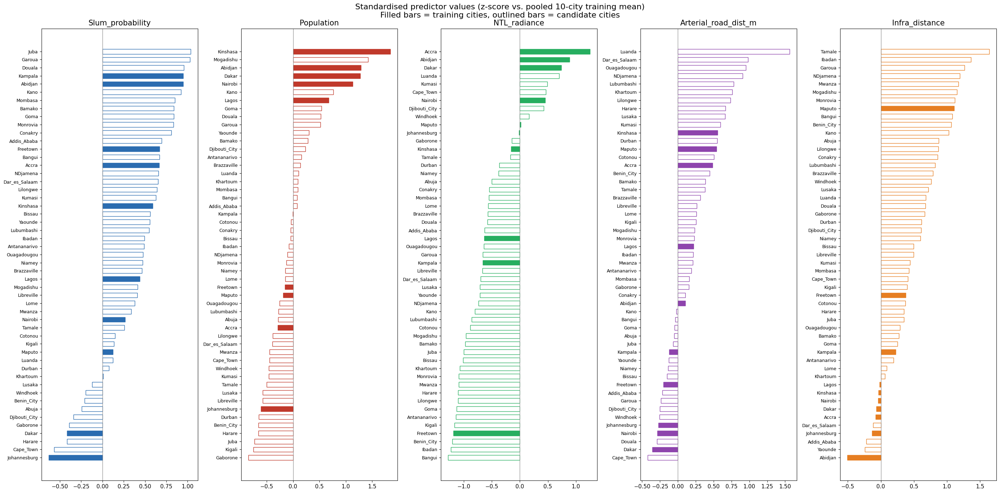

In [ ]:
import pandas as pd
import numpy as np
import glob
import os
import matplotlib.pyplot as plt

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]

# ---- Training cities: per-city mean for each predictor ----
train_base = "/content/drive/MyDrive/Paper_3/Data/Master/2024"
file_overrides = {"Johannesburg": "johannesburg_master_2024_v1.csv"}
training_cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
                    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

train_rows = []
all_train_cells = []
for city in training_cities:
    fname = file_overrides.get(city, f"{city.lower()}_master_2024.csv")
    path = os.path.join(train_base, city, fname)
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    all_train_cells.append(df)
    row = {"city": city, "group": "training"}
    row.update(df[PREDICTORS].mean().to_dict())
    train_rows.append(row)

# pooled training mean/std (the standardisation reference — same as before)
pooled_train = pd.concat(all_train_cells, ignore_index=True)
train_mean = pooled_train[PREDICTORS].mean()
train_std = pooled_train[PREDICTORS].std()

# ---- Candidate cities: per-city mean for each predictor ----
candidate_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
candidate_paths = sorted(glob.glob(os.path.join(candidate_folder, "*.csv")))

cand_rows = []
for path in candidate_paths:
    city = os.path.basename(path).replace("_grid_30m.csv", "")
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    row = {"city": city, "group": "candidate"}
    row.update(df[PREDICTORS].mean().to_dict())
    cand_rows.append(row)

all_cities_df = pd.DataFrame(train_rows + cand_rows)

# ---- Standardise against the pooled TRAINING mean/std ----
z_df = all_cities_df.copy()
for col in PREDICTORS:
    z_df[col] = (all_cities_df[col] - train_mean[col]) / train_std[col]

# ---- Plot: one panel per predictor, training=filled, candidate=outline ----
panel_colors = ["#2b6cb0", "#c0392b", "#27ae60", "#8e44ad", "#e67e22"]  # one per predictor

fig, axes = plt.subplots(1, len(PREDICTORS), figsize=(28, 14), sharey=False)

for ax, col, color in zip(axes, PREDICTORS, panel_colors):
    sub = z_df[["city", "group", col]].sort_values(col)
    colors = [color if g == "training" else "white" for g in sub["group"]]
    edgecolors = [color for g in sub["group"]]  # same colour outlines candidates too
    ax.barh(sub["city"], sub[col], color=colors, edgecolor=edgecolors,
            linewidth=1.0, height=0.6)  # thinner bars
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(col, fontsize=15)
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=11)

fig.suptitle("Standardised predictor values (z-score vs. pooled 10-city training mean)\n"
             "Filled bars = training cities, outlined bars = candidate cities", fontsize=16)
plt.tight_layout()
plt.show()

PC1: 34.7% variance, PC2: 28.7% variance


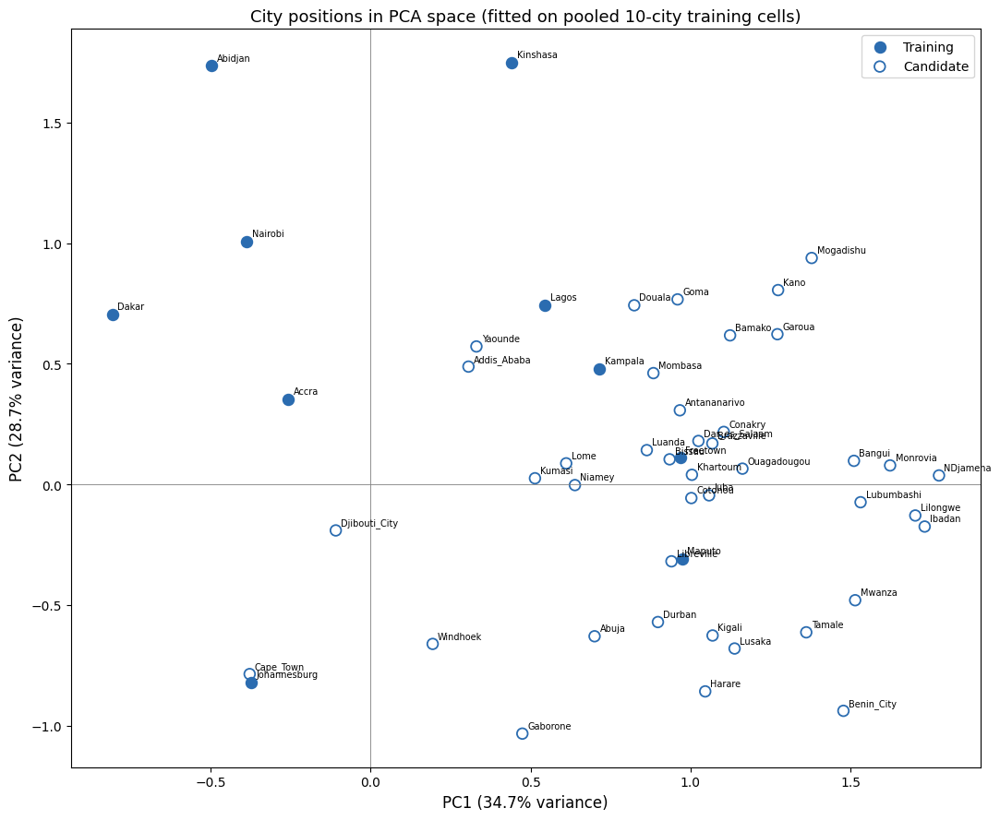

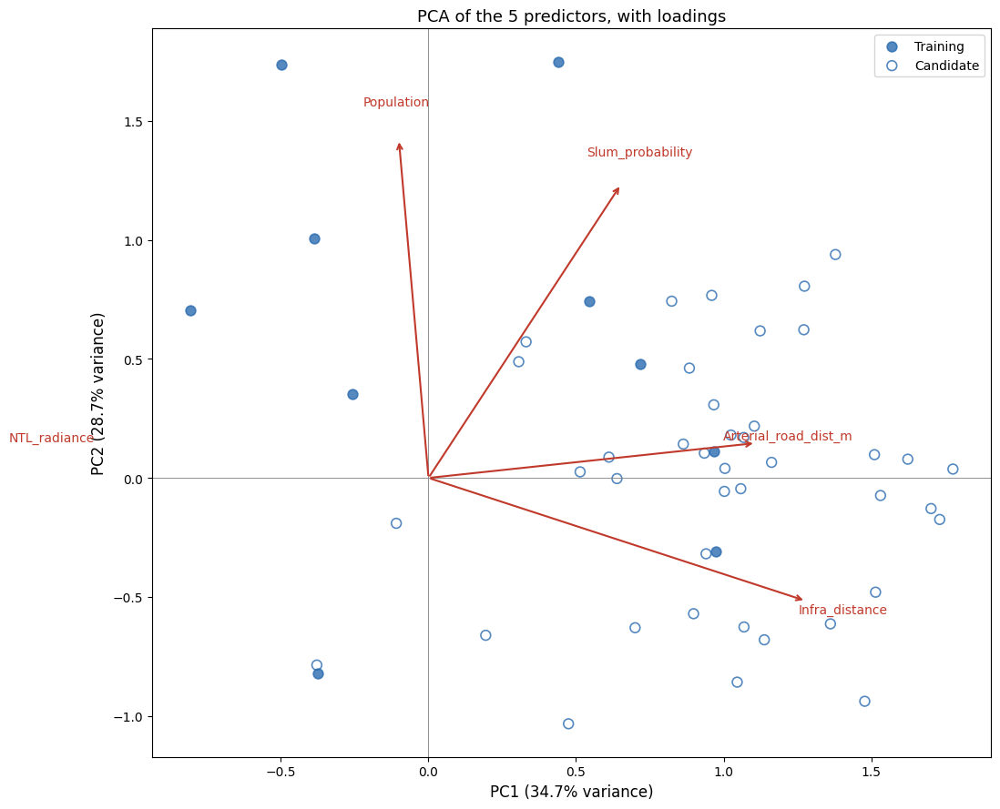

In [ ]:
import pandas as pd
import numpy as np
import glob
import os
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]

# ---- Fit PCA on standardised, pooled TRAINING cells (same reference as Mahalanobis) ----
# (pooled_train, train_mean, train_std already exist from the earlier z-score script;
#  re-derive here for a self-contained script)

train_base = "/content/drive/MyDrive/Paper_3/Data/Master/2024"
file_overrides = {"Johannesburg": "johannesburg_master_2024_v1.csv"}
training_cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
                    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

all_train_cells = []
for city in training_cities:
    fname = file_overrides.get(city, f"{city.lower()}_master_2024.csv")
    path = os.path.join(train_base, city, fname)
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    all_train_cells.append(df)

pooled_train = pd.concat(all_train_cells, ignore_index=True)
train_mean = pooled_train[PREDICTORS].mean()
train_std = pooled_train[PREDICTORS].std()

train_z = (pooled_train[PREDICTORS] - train_mean) / train_std

pca = PCA(n_components=2)
pca.fit(train_z)
var_explained = pca.explained_variance_ratio_ * 100
print(f"PC1: {var_explained[0]:.1f}% variance, PC2: {var_explained[1]:.1f}% variance")

# ---- City-level mean vectors (standardised), for both training and candidate cities ----
train_rows = []
for city, df in zip(training_cities, all_train_cells):
    z = (df[PREDICTORS].mean() - train_mean) / train_std
    train_rows.append({"city": city, "group": "training", **z.to_dict()})

candidate_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
candidate_paths = sorted(glob.glob(os.path.join(candidate_folder, "*.csv")))
cand_rows = []
for path in candidate_paths:
    city = os.path.basename(path).replace("_grid_30m.csv", "")
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    z = (df[PREDICTORS].mean() - train_mean) / train_std
    cand_rows.append({"city": city, "group": "candidate", **z.to_dict()})

all_cities_z = pd.DataFrame(train_rows + cand_rows)

# project city-level means onto the training-fitted PCA
scores = pca.transform(all_cities_z[PREDICTORS])
all_cities_z["PC1"] = scores[:, 0]
all_cities_z["PC2"] = scores[:, 1]

# ---- Plot 1: PCA scatter, training=filled, candidate=outline ----
fig, ax = plt.subplots(figsize=(11, 9))
for group, marker_face in [("training", True), ("candidate", False)]:
    sub = all_cities_z[all_cities_z["group"] == group]
    ax.scatter(sub["PC1"], sub["PC2"],
               facecolors="#2b6cb0" if marker_face else "none",
               edgecolors="#2b6cb0", s=70, linewidth=1.3,
               label=group.capitalize())
    for _, row in sub.iterrows():
        ax.annotate(row["city"], (row["PC1"], row["PC2"]), fontsize=7,
                    xytext=(4, 4), textcoords="offset points")

ax.axhline(0, color="grey", linewidth=0.6)
ax.axvline(0, color="grey", linewidth=0.6)
ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)", fontsize=12)
ax.set_title("City positions in PCA space (fitted on pooled 10-city training cells)", fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

# ---- Plot 2: same PCA scatter + predictor loading vectors (image 1B style) ----
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)  # scaled loadings

fig, ax = plt.subplots(figsize=(11, 9))
for group, marker_face in [("training", True), ("candidate", False)]:
    sub = all_cities_z[all_cities_z["group"] == group]
    ax.scatter(sub["PC1"], sub["PC2"],
               facecolors="#2b6cb0" if marker_face else "none",
               edgecolors="#2b6cb0", s=60, linewidth=1.2, alpha=0.8,
               label=group.capitalize())

# scale factor so arrows are visible alongside the city point cloud
scale = np.abs(all_cities_z[["PC1", "PC2"]].to_numpy()).max() / np.abs(loadings).max() * 0.8
for i, pred in enumerate(PREDICTORS):
    ax.annotate("", xy=(loadings[i, 0]*scale, loadings[i, 1]*scale), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="#c0392b", linewidth=1.5))
    ax.text(loadings[i, 0]*scale*1.1, loadings[i, 1]*scale*1.1, pred,
            color="#c0392b", fontsize=10, ha="center")

ax.axhline(0, color="grey", linewidth=0.6)
ax.axvline(0, color="grey", linewidth=0.6)
ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)", fontsize=12)
ax.set_title("PCA of the 5 predictors, with loadings", fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from scipy.stats import chi2
import glob, os

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]

# ---- Fit PCA with ALL 5 components (not just 2) on standardised training cells ----
pca_full = PCA(n_components=5)
pca_full.fit(train_z)
cum_var = np.cumsum(pca_full.explained_variance_ratio_) * 100
for i, v in enumerate(cum_var, 1):
    print(f"PC1-{i}: {v:.1f}% cumulative variance")

train_scores_full = pca_full.transform(train_z)

def mahalanobis_sq_pcspace(scores, n_components):
    """Mahalanobis distance using only the first n_components PCs.
       Since PCA components are orthogonal with variance = eigenvalue,
       Mahalanobis in PC space reduces to sum((score_i / sqrt(eigenvalue_i))^2)."""
    eigvals = pca_full.explained_variance_[:n_components]
    s = scores[:, :n_components]
    return np.sum((s ** 2) / eigvals, axis=1)

# reference: training cells' own distribution in PC space (for context, not thresholding directly)
d2_train_full5 = mahalanobis_sq_pcspace(train_scores_full, 5)
print(f"\nSanity check — full 5-PC distance should match raw 5D Mahalanobis "
      f"(mean={d2_train_full5.mean():.3f}, matches earlier raw-space mean_d2 pooled reference)")

# ---- Score all 41 candidates, using 2-PC distance AND full 5-PC distance ----
candidate_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
candidate_paths = sorted(glob.glob(os.path.join(candidate_folder, "*.csv")))

DF_2PC, DF_5PC = 2, 5
thresh_2pc = chi2.ppf(0.99, df=DF_2PC)
thresh_5pc = chi2.ppf(0.99, df=DF_5PC)

results = []
for path in candidate_paths:
    city = os.path.basename(path).replace("_grid_30m.csv", "")
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    z = (df[PREDICTORS] - train_mean) / train_std
    scores = pca_full.transform(z)

    d2_2pc = mahalanobis_sq_pcspace(scores, 2)
    d2_5pc = mahalanobis_sq_pcspace(scores, 5)

    results.append({
        "city": city,
        "n_cells": len(df),
        "pct_beyond_2pc_threshold": round(100 * np.mean(d2_2pc > thresh_2pc), 2),
        "pct_beyond_5pc_threshold": round(100 * np.mean(d2_5pc > thresh_5pc), 2),
    })

pc_results_df = pd.DataFrame(results).sort_values("pct_beyond_5pc_threshold", ascending=False)
pd.set_option("display.width", 160)
print(pc_results_df.to_string(index=False))

PC1-1: 34.7% cumulative variance
PC1-2: 63.4% cumulative variance
PC1-3: 79.3% cumulative variance
PC1-4: 90.9% cumulative variance
PC1-5: 100.0% cumulative variance

Sanity check — full 5-PC distance should match raw 5D Mahalanobis (mean=5.000, matches earlier raw-space mean_d2 pooled reference)
         city  n_cells  pct_beyond_2pc_threshold  pct_beyond_5pc_threshold
       Luanda  1062723                     18.24                     31.16
    Mogadishu   164603                      7.56                     15.02
       Tamale   159972                      6.30                     14.98
     Lilongwe   236073                      9.98                     13.87
   Benin_City   482149                      6.31                     13.61
       Ibadan   657101                      7.86                     12.40
       Harare   782853                      8.64                     12.14
       Lusaka   682609                      9.78                     12.00
     Khartoum   892615     

In [ ]:
import numpy as np
import pandas as pd

# City-level centroid Mahalanobis distance in PC space (2-component and full 5-component)

def mahalanobis_sq_pcspace(scores, n_components):
    eigvals = pca_full.explained_variance_[:n_components]
    s = scores[:, :n_components]
    return np.sum((s ** 2) / eigvals, axis=1)

# training city centroids (mean z-score per city), projected into PC space
train_centroid_rows = []
for city, df in training_data.items():
    z = (df[PREDICTORS].mean() - train_mean) / train_std
    train_centroid_rows.append({"city": city, "group": "training", **z.to_dict()})

# candidate city centroids
cand_centroid_rows = []
for path in candidate_paths:
    city = os.path.basename(path).replace("_grid_30m.csv", "")
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    z = (df[PREDICTORS].mean() - train_mean) / train_std
    cand_centroid_rows.append({"city": city, "group": "candidate", **z.to_dict()})

centroids_df = pd.DataFrame(train_centroid_rows + cand_centroid_rows)
centroid_scores = pca_full.transform(centroids_df[PREDICTORS])

centroids_df["d2_2pc"] = mahalanobis_sq_pcspace(centroid_scores, 2)
centroids_df["d2_5pc"] = mahalanobis_sq_pcspace(centroid_scores, 5)
centroids_df["distance_2pc"] = np.sqrt(centroids_df["d2_2pc"])  # Mahalanobis distance (not squared)
centroids_df["distance_5pc"] = np.sqrt(centroids_df["d2_5pc"])

city_level_summary = centroids_df[centroids_df["group"] == "candidate"][
    ["city", "distance_2pc", "distance_5pc"]
].sort_values("distance_5pc", ascending=False)

pd.set_option("display.width", 160)
print(city_level_summary.to_string(index=False))

         city  distance_2pc  distance_5pc
    Mogadishu      1.307805      2.201880
       Luanda      0.666482      2.020880
         Juba      0.804674      1.937379
       Garoua      1.096860      1.863904
       Tamale      1.154139      1.758170
         Kano      1.178125      1.648339
       Ibadan      1.323889      1.617096
       Bangui      1.150731      1.614324
Dar_es_Salaam      0.792840      1.603082
     Monrovia      1.235444      1.529333
       Harare      1.069502      1.462687
   Benin_City      1.368976      1.457315
       Kigali      0.965650      1.447487
       Mwanza      1.218439      1.426931
         Goma      0.969950      1.424016
     Lilongwe      1.297968      1.420883
       Douala      0.880703      1.412907
     NDjamena      1.350184      1.399926
     Khartoum      0.763727      1.365159
       Kumasi      0.390836      1.333459
Djibouti_City      0.179398      1.269025
 Antananarivo      0.777831      1.242264
       Bissau      0.715322      1

In [ ]:
# Training city centroids' own distance from the training reference centroid
train_only = centroids_df[centroids_df["group"] == "training"][
    ["city", "distance_2pc", "distance_5pc"]
].sort_values("distance_5pc", ascending=False)

print("TRAINING CITIES — centroid distance from training reference centroid")
print(train_only.to_string(index=False))

print(f"\nTraining centroid distance (5PC) range: "
      f"{train_only['distance_5pc'].min():.3f} to {train_only['distance_5pc'].max():.3f}")
print(f"Training centroid distance (5PC) mean: {train_only['distance_5pc'].mean():.3f}, "
      f"median: {train_only['distance_5pc'].median():.3f}")

TRAINING CITIES — centroid distance from training reference centroid
        city  distance_2pc  distance_5pc
    Kinshasa      1.497167      1.979186
       Dakar      0.850065      1.897173
       Accra      0.354025      1.754461
     Abidjan      1.496298      1.668905
    Freetown      0.741433      1.491096
     Nairobi      0.890645      1.342950
     Kampala      0.675509      1.261349
      Maputo      0.782963      1.256812
       Lagos      0.745088      0.963761
Johannesburg      0.741024      0.791031

Training centroid distance (5PC) range: 0.791 to 1.979
Training centroid distance (5PC) mean: 1.441, median: 1.417


PC1: 34.7% variance, PC2: 28.7% variance


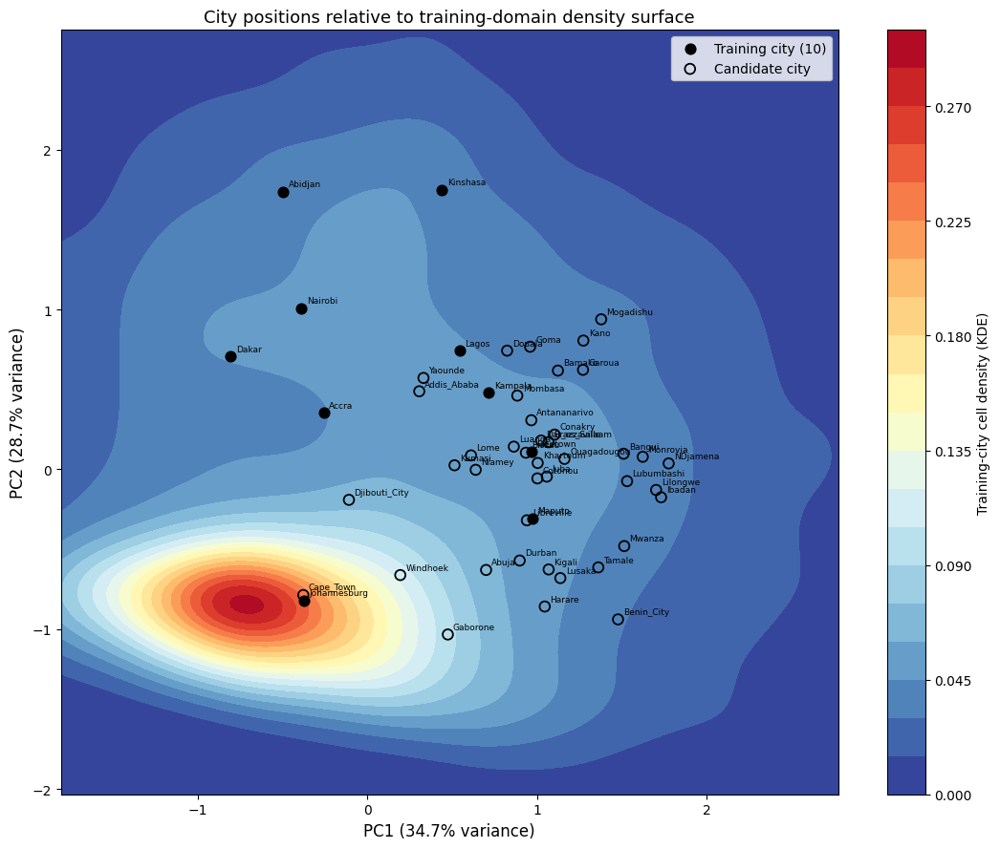

In [ ]:
import pandas as pd
import numpy as np
import glob
import os
from sklearn.decomposition import PCA
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]

# ---- 1. Load training cities, pool cells ----
train_base = "/content/drive/MyDrive/Paper_3/Data/Master/2024"
file_overrides = {"Johannesburg": "johannesburg_master_2024_v1.csv"}
training_cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
                    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

all_train_cells = []
for city in training_cities:
    fname = file_overrides.get(city, f"{city.lower()}_master_2024.csv")
    path = os.path.join(train_base, city, fname)
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    all_train_cells.append(df)

pooled_train = pd.concat(all_train_cells, ignore_index=True)
train_mean = pooled_train[PREDICTORS].mean()
train_std = pooled_train[PREDICTORS].std()
train_z = (pooled_train[PREDICTORS] - train_mean) / train_std

# ---- 2. Fit PCA on standardised training cells ----
pca = PCA(n_components=2)
pca.fit(train_z)
var_explained = pca.explained_variance_ratio_ * 100
print(f"PC1: {var_explained[0]:.1f}% variance, PC2: {var_explained[1]:.1f}% variance")

train_scores = pca.transform(train_z)  # all pooled training cells, projected

# ---- 3. City-level mean vectors (training + candidates), for overlay ----
train_rows = []
for city, df in zip(training_cities, all_train_cells):
    z = (df[PREDICTORS].mean() - train_mean) / train_std
    train_rows.append({"city": city, "group": "training", **z.to_dict()})

candidate_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
candidate_paths = sorted(glob.glob(os.path.join(candidate_folder, "*.csv")))
cand_rows = []
for path in candidate_paths:
    city = os.path.basename(path).replace("_grid_30m.csv", "")
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    z = (df[PREDICTORS].mean() - train_mean) / train_std
    cand_rows.append({"city": city, "group": "candidate", **z.to_dict()})

all_cities_z = pd.DataFrame(train_rows + cand_rows)
scores = pca.transform(all_cities_z[PREDICTORS])
all_cities_z["PC1"] = scores[:, 0]
all_cities_z["PC2"] = scores[:, 1]

# ---- 4. KDE density surface, fit on a subsample of training cells ----
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(train_scores), size=100_000, replace=False)
kde = gaussian_kde(train_scores[sample_idx].T)

pad = 1.0
x_min, x_max = all_cities_z["PC1"].min() - pad, all_cities_z["PC1"].max() + pad
y_min, y_max = all_cities_z["PC2"].min() - pad, all_cities_z["PC2"].max() + pad

xx, yy = np.mgrid[x_min:x_max:200j, y_min:y_max:200j]
grid_coords = np.vstack([xx.ravel(), yy.ravel()])
density = kde(grid_coords).reshape(xx.shape)

# ---- 5. Plot ----
fig, ax = plt.subplots(figsize=(11, 9))

cf = ax.contourf(xx, yy, density, levels=20, cmap="RdYlBu_r")
cb = fig.colorbar(cf, ax=ax)
cb.set_label("Training-city cell density (KDE)", fontsize=10)

train_pts = all_cities_z[all_cities_z["group"] == "training"]
cand_pts = all_cities_z[all_cities_z["group"] == "candidate"]

ax.scatter(train_pts["PC1"], train_pts["PC2"], facecolors="black",
           edgecolors="black", s=60, label="Training city (10)", zorder=5)
ax.scatter(cand_pts["PC1"], cand_pts["PC2"], facecolors="none",
           edgecolors="black", s=60, linewidth=1.3, label="Candidate city", zorder=5)

for _, row in all_cities_z.iterrows():
    ax.annotate(row["city"], (row["PC1"], row["PC2"]), fontsize=6.5,
                xytext=(4, 4), textcoords="offset points")

ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)", fontsize=12)
ax.set_title("City positions relative to training-domain density surface", fontsize=13)
ax.legend(fontsize=10, loc="upper right")
plt.tight_layout()
plt.show()

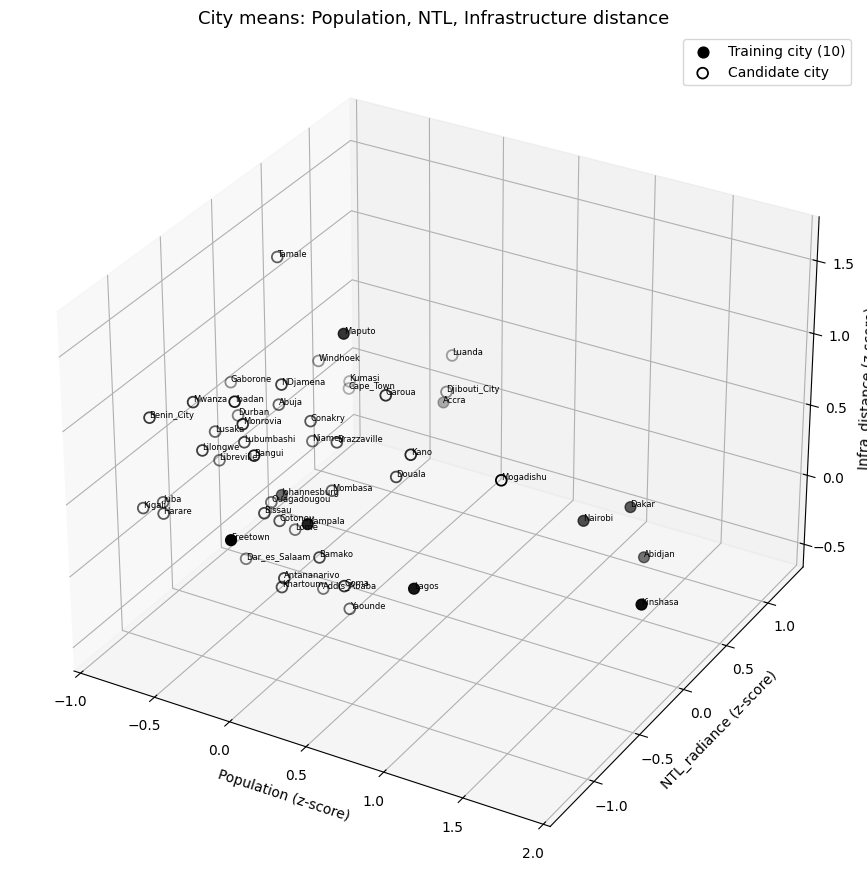

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection='3d')

train_pts = all_cities_z[all_cities_z["group"] == "training"]
cand_pts = all_cities_z[all_cities_z["group"] == "candidate"]

ax.scatter(train_pts["Population"], train_pts["NTL_radiance"], train_pts["Infra_distance"],
           facecolors="black", edgecolors="black", s=60, label="Training city (10)")
ax.scatter(cand_pts["Population"], cand_pts["NTL_radiance"], cand_pts["Infra_distance"],
           facecolors="none", edgecolors="black", s=60, linewidth=1.3, label="Candidate city")

for _, row in all_cities_z.iterrows():
    ax.text(row["Population"], row["NTL_radiance"], row["Infra_distance"],
            row["city"], fontsize=6)

ax.set_xlabel("Population (z-score)", fontsize=10)
ax.set_ylabel("NTL_radiance (z-score)", fontsize=10)
ax.set_zlabel("Infra_distance (z-score)", fontsize=10)
ax.set_title("City means: Population, NTL, Infrastructure distance", fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

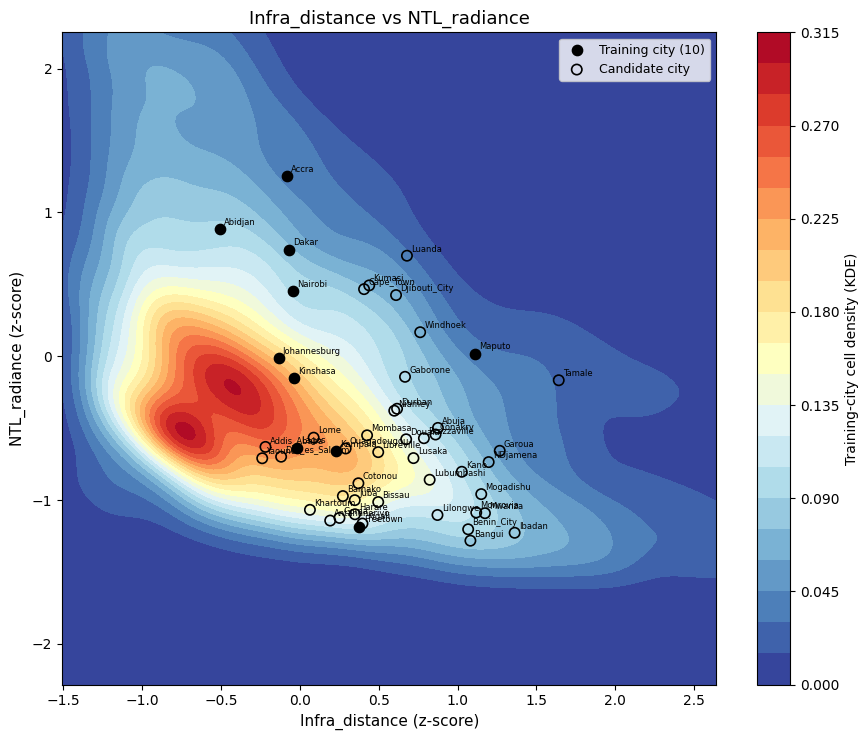

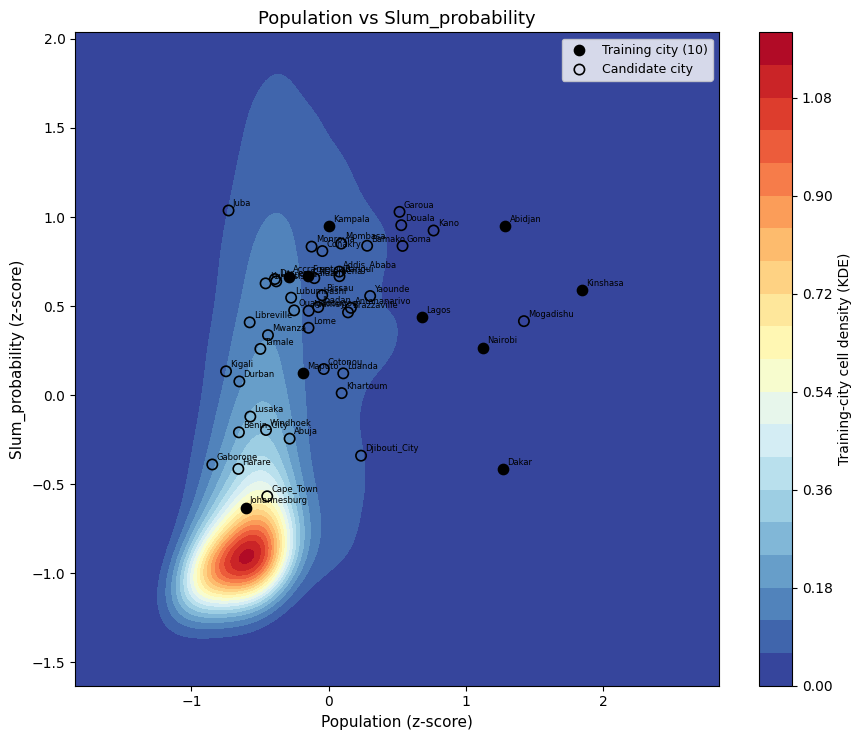

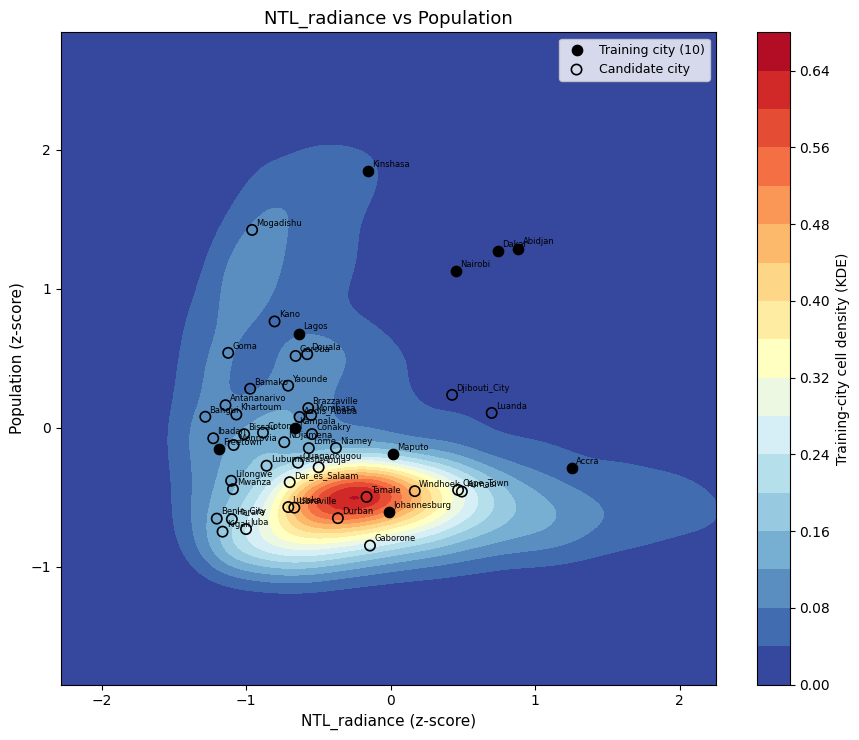

In [ ]:
def pairwise_density_plot(x_col, y_col):
    rng = np.random.default_rng(42)
    sample_idx = rng.choice(len(train_z), size=100_000, replace=False)
    xy_sample = train_z.iloc[sample_idx][[x_col, y_col]].to_numpy()

    kde = gaussian_kde(xy_sample.T)

    pad = 1.0
    x_min, x_max = all_cities_z[x_col].min() - pad, all_cities_z[x_col].max() + pad
    y_min, y_max = all_cities_z[y_col].min() - pad, all_cities_z[y_col].max() + pad
    xx, yy = np.mgrid[x_min:x_max:200j, y_min:y_max:200j]
    density = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(9, 7.5))
    cf = ax.contourf(xx, yy, density, levels=20, cmap="RdYlBu_r")
    fig.colorbar(cf, ax=ax, label="Training-city cell density (KDE)")

    train_pts = all_cities_z[all_cities_z["group"] == "training"]
    cand_pts = all_cities_z[all_cities_z["group"] == "candidate"]
    ax.scatter(train_pts[x_col], train_pts[y_col], facecolors="black",
               edgecolors="black", s=55, label="Training city (10)", zorder=5)
    ax.scatter(cand_pts[x_col], cand_pts[y_col], facecolors="none",
               edgecolors="black", s=55, linewidth=1.2, label="Candidate city", zorder=5)
    for _, row in all_cities_z.iterrows():
        ax.annotate(row["city"], (row[x_col], row[y_col]), fontsize=6,
                    xytext=(3, 3), textcoords="offset points")

    ax.set_xlabel(f"{x_col} (z-score)", fontsize=11)
    ax.set_ylabel(f"{y_col} (z-score)", fontsize=11)
    ax.set_title(f"{x_col} vs {y_col}", fontsize=13)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

pairwise_density_plot("Infra_distance", "NTL_radiance")
pairwise_density_plot("Population", "Slum_probability")
pairwise_density_plot("NTL_radiance", "Population")

Max density: 0.38097, isosurface level: 0.05715


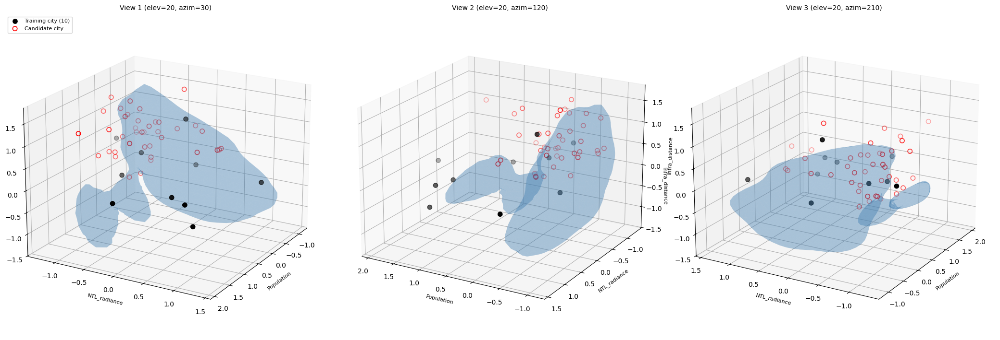

In [ ]:
import numpy as np
from scipy.stats import gaussian_kde
from skimage import measure
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

DIMS = ["Population", "NTL_radiance", "Infra_distance"]

# ---- 1. Fit 3D KDE on a subsample of training cells ----
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(train_z), size=100_000, replace=False)
xyz_sample = train_z.iloc[sample_idx][DIMS].to_numpy()

kde = gaussian_kde(xyz_sample.T)

# ---- 2. Evaluate density on a 3D grid ----
pad = 1.0
mins = all_cities_z[DIMS].min() - pad
maxs = all_cities_z[DIMS].max() + pad

GRID_N = 40  # keep modest — 40^3 = 64,000 KDE evaluations, already fairly slow
x = np.linspace(mins["Population"], maxs["Population"], GRID_N)
y = np.linspace(mins["NTL_radiance"], maxs["NTL_radiance"], GRID_N)
z = np.linspace(mins["Infra_distance"], maxs["Infra_distance"], GRID_N)
xx, yy, zz = np.meshgrid(x, y, z, indexing="ij")
grid_coords = np.vstack([xx.ravel(), yy.ravel(), zz.ravel()])

density = kde(grid_coords).reshape(xx.shape)

# ---- 3. Extract isosurface at a chosen density level ----
level = density.max() * 0.15  # ~15% of peak density — a broad envelope, not just the core
print(f"Max density: {density.max():.5f}, isosurface level: {level:.5f}")

verts, faces, _, _ = measure.marching_cubes(density, level=level)
# rescale verts from grid-index space back to actual coordinate space
verts_scaled = verts.copy()
verts_scaled[:, 0] = x[0] + verts[:, 0] / (GRID_N - 1) * (x[-1] - x[0])
verts_scaled[:, 1] = y[0] + verts[:, 1] / (GRID_N - 1) * (y[-1] - y[0])
verts_scaled[:, 2] = z[0] + verts[:, 2] / (GRID_N - 1) * (z[-1] - z[0])

# ---- 4. Plot: 3 viewing angles, small multiples ----
angles = [(20, 30), (20, 120), (20, 210)]
train_pts = all_cities_z[all_cities_z["group"] == "training"]
cand_pts = all_cities_z[all_cities_z["group"] == "candidate"]

fig = plt.figure(figsize=(21, 7))
for i, (elev, azim) in enumerate(angles):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    mesh = Poly3DCollection(verts_scaled[faces], alpha=0.25, facecolor="steelblue", edgecolor="none")
    ax.add_collection3d(mesh)

    ax.scatter(train_pts["Population"], train_pts["NTL_radiance"], train_pts["Infra_distance"],
               color="black", s=45, label="Training city (10)")
    ax.scatter(cand_pts["Population"], cand_pts["NTL_radiance"], cand_pts["Infra_distance"],
               facecolors="none", edgecolors="red", s=45, linewidth=1.2, label="Candidate city")

    ax.set_xlabel("Population", fontsize=8)
    ax.set_ylabel("NTL_radiance", fontsize=8)
    ax.set_zlabel("Infra_distance", fontsize=8)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"View {i+1} (elev={elev}, azim={azim})", fontsize=10)
    if i == 0:
        ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

/tmp/ipykernel_63291/4272789617.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("RdYlBu_r")


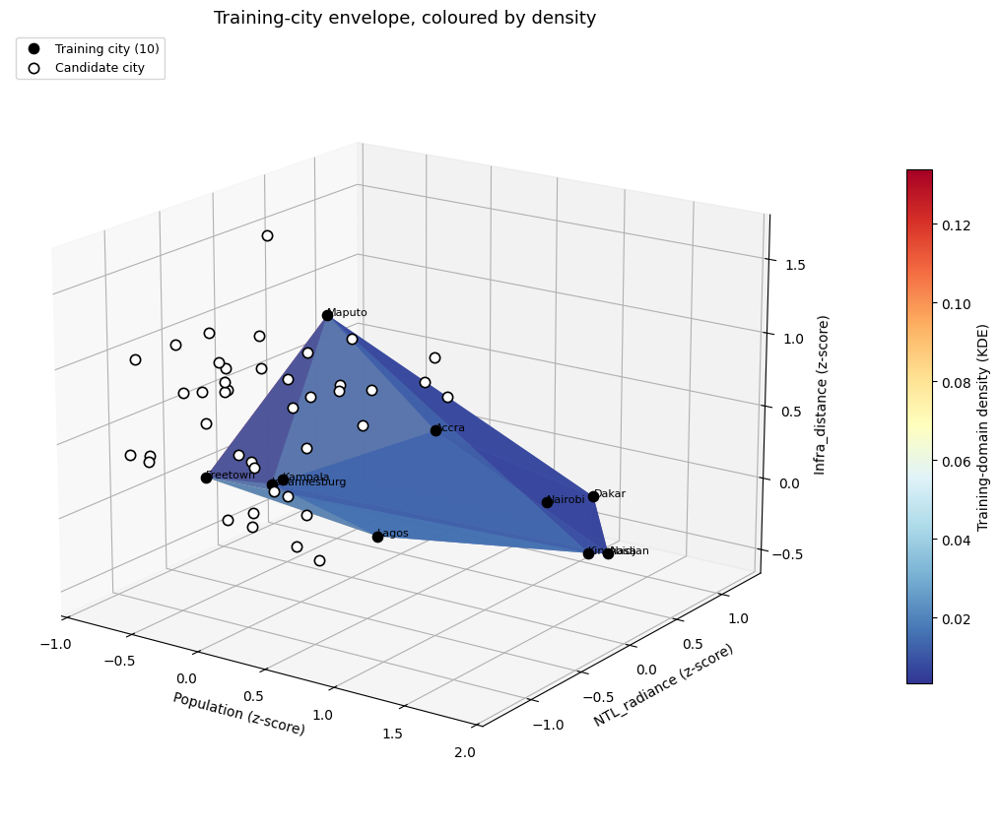

In [ ]:
import numpy as np
from scipy.spatial import ConvexHull
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

DIMS = ["Population", "NTL_radiance", "Infra_distance"]

# ---- 1. Fit 3D KDE on a subsample of training cells (reuse if already in session) ----
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(train_z), size=100_000, replace=False)
xyz_sample = train_z.iloc[sample_idx][DIMS].to_numpy()
kde = gaussian_kde(xyz_sample.T)

# ---- 2. Build an outer-envelope surface from the training CITY MEANS ----
# (city means, not raw cells — gives a smooth single-blob shape like the mockup;
#  using raw cells here would produce a lumpy/noisy hull instead)
train_pts_df = all_cities_z[all_cities_z["group"] == "training"]
hull_points = train_pts_df[DIMS].to_numpy()
hull = ConvexHull(hull_points)

# ---- 3. Colour each face by KDE density at its centroid ----
face_densities = []
for simplex in hull.simplices:
    centroid = hull_points[simplex].mean(axis=0)
    d = kde(centroid.reshape(3, 1))[0]
    face_densities.append(d)
face_densities = np.array(face_densities)

norm = mcolors.Normalize(vmin=face_densities.min(), vmax=face_densities.max())
cmap = cm.get_cmap("RdYlBu_r")
face_colors = cmap(norm(face_densities))

# ---- 4. Plot: single view ----
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection='3d')

mesh = Poly3DCollection(hull_points[hull.simplices], facecolor=face_colors,
                         edgecolor="none", alpha=0.85)
ax.add_collection3d(mesh)

cand_pts = all_cities_z[all_cities_z["group"] == "candidate"]
ax.scatter(train_pts_df["Population"], train_pts_df["NTL_radiance"], train_pts_df["Infra_distance"],
           color="black", s=55, label="Training city (10)", depthshade=False)
ax.scatter(cand_pts["Population"], cand_pts["NTL_radiance"], cand_pts["Infra_distance"],
           facecolors="white", edgecolors="black", s=55, linewidth=1.2,
           label="Candidate city", depthshade=False)

for _, row in train_pts_df.iterrows():
    ax.text(row["Population"], row["NTL_radiance"], row["Infra_distance"],
            row["city"], fontsize=8)

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.1)
cbar.set_label("Training-domain density (KDE)", fontsize=10)

ax.set_xlabel("Population (z-score)", fontsize=10)
ax.set_ylabel("NTL_radiance (z-score)", fontsize=10)
ax.set_zlabel("Infra_distance (z-score)", fontsize=10)
ax.view_init(elev=18, azim=-55)
ax.set_title("Training-city envelope, coloured by density", fontsize=13)
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

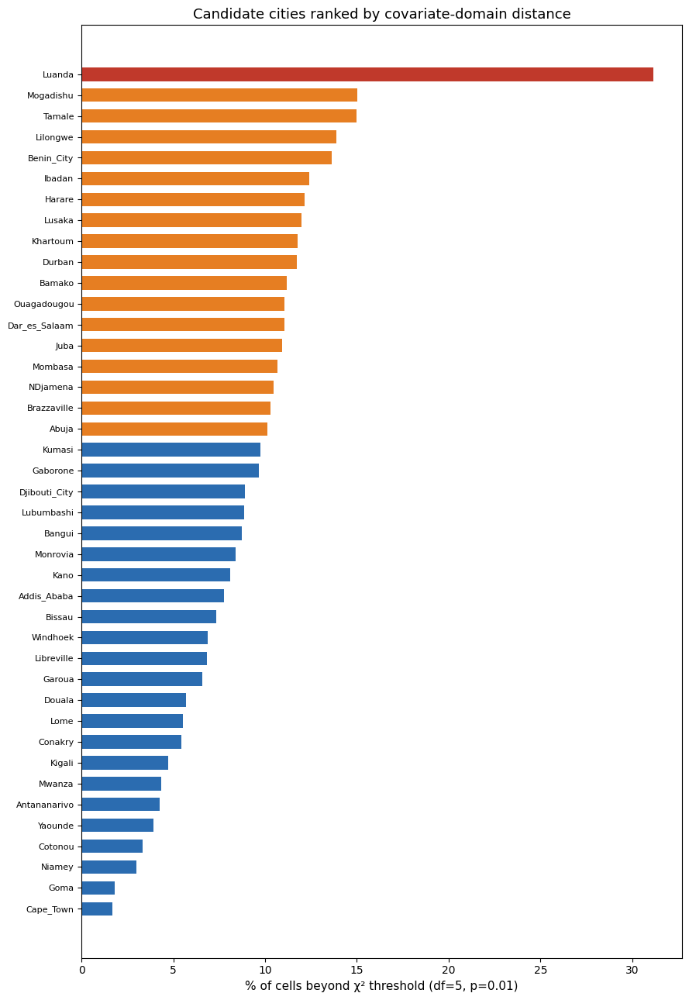

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

results_df = pd.read_csv("/content/drive/MyDrive/Paper_3/Data/Test_cities/mahalanobis_screen_results.csv")
# reuse results_df from the Mahalanobis screening step
plot_df = results_df.sort_values("pct_beyond_threshold", ascending=True)

fig, ax = plt.subplots(figsize=(9, 13))
colors = ["#c0392b" if v > 20 else "#e67e22" if v > 10 else "#2b6cb0"
          for v in plot_df["pct_beyond_threshold"]]

ax.barh(plot_df["city"], plot_df["pct_beyond_threshold"], color=colors, height=0.65)
ax.set_xlabel("% of cells beyond χ² threshold (df=5, p=0.01)", fontsize=11)
ax.set_title("Candidate cities ranked by covariate-domain distance", fontsize=13)
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull
import glob, os

# ---- Build the hull from a subsample of training cells in PC1-2 space ----
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(train_scores_full), size=50_000, replace=False)
hull_input = train_scores_full[sample_idx][:, :2]  # PC1, PC2 only

hull = ConvexHull(hull_input)

def in_hull(points, hull):
    """Vectorised point-in-hull test using the hull's facet equations."""
    A = hull.equations[:, :-1]
    b = hull.equations[:, -1]
    return np.all(np.add(points @ A.T, b) <= 1e-9, axis=1)

# ---- Test each candidate city's cells against the hull ----
candidate_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
candidate_paths = sorted(glob.glob(os.path.join(candidate_folder, "*.csv")))

hull_results = []
for path in candidate_paths:
    city = os.path.basename(path).replace("_grid_30m.csv", "")
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    z = (df[PREDICTORS] - train_mean) / train_std
    scores = pca_full.transform(z)[:, :2]

    inside = in_hull(scores, hull)
    hull_results.append({
        "city": city,
        "n_cells": len(df),
        "pct_outside_hull": round(100 * (1 - inside.mean()), 2),
    })

hull_df = pd.DataFrame(hull_results).sort_values("pct_outside_hull", ascending=False)
pd.set_option("display.width", 160)
print(hull_df.to_string(index=False))

         city  n_cells  pct_outside_hull
       Luanda  1062723              3.73
       Lusaka   682609              3.38
   Benin_City   482149              3.21
       Durban   881000              3.12
       Harare   782853              2.55
Djibouti_City    61160              1.64
   Lubumbashi   334295              1.58
       Ibadan   657101              1.40
         Juba   132238              1.33
     Khartoum   892615              1.32
      Mombasa   175250              1.31
      Conakry   327095              1.05
       Bissau    68467              0.98
  Brazzaville   242670              0.90
       Tamale   159972              0.88
     Lilongwe   236073              0.85
    Mogadishu   164603              0.79
     Gaborone   166188              0.79
      Yaounde   366078              0.76
     Monrovia   250144              0.65
     NDjamena   224067              0.50
  Addis_Ababa   585871              0.44
Dar_es_Salaam  1172840              0.41
       Bangui   

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
import glob, os

# ---- Build a KD-tree from a subsample of training cells (5D standardised space) ----
rng = np.random.default_rng(42)
train_sample_idx = rng.choice(len(train_z), size=100_000, replace=False)
train_sample = train_z.iloc[train_sample_idx][PREDICTORS].to_numpy()

tree = cKDTree(train_sample)

# ---- Calibrate a threshold: training cells' own nearest-neighbour distance to EACH OTHER ----
# (query k=2 since the nearest neighbour of a training point within its own set is itself at distance 0)
self_dist, _ = tree.query(train_sample, k=2)
self_nn_dist = self_dist[:, 1]  # distance to nearest *other* training cell
p95_self = np.percentile(self_nn_dist, 95)
p99_self = np.percentile(self_nn_dist, 99)
print(f"Training self-NN distance: median={np.median(self_nn_dist):.3f}, "
      f"p95={p95_self:.3f}, p99={p99_self:.3f}")

# ---- Score each candidate city: distance from each cell to nearest training cell ----
candidate_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
candidate_paths = sorted(glob.glob(os.path.join(candidate_folder, "*.csv")))

knn_results = []
for path in candidate_paths:
    city = os.path.basename(path).replace("_grid_30m.csv", "")
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    z = (df[PREDICTORS] - train_mean) / train_std

    dist, _ = tree.query(z.to_numpy(), k=1)

    knn_results.append({
        "city": city,
        "n_cells": len(df),
        "median_nn_dist": round(np.median(dist), 3),
        "pct_beyond_p95_self": round(100 * np.mean(dist > p95_self), 2),
        "pct_beyond_p99_self": round(100 * np.mean(dist > p99_self), 2),
    })

knn_df = pd.DataFrame(knn_results).sort_values("pct_beyond_p99_self", ascending=False)
pd.set_option("display.width", 160)
print(knn_df.to_string(index=False))

Training self-NN distance: median=0.126, p95=0.297, p99=0.413
         city  n_cells  median_nn_dist  pct_beyond_p95_self  pct_beyond_p99_self
       Luanda  1062723           0.338                58.12                37.75
    Mogadishu   164603           0.323                57.25                31.12
Dar_es_Salaam  1172840           0.290                48.30                27.10
         Kano   314301           0.290                47.93                24.31
       Garoua    47602           0.302                51.24                24.15
Djibouti_City    61160           0.268                43.22                24.15
     Khartoum   892615           0.293                48.94                23.22
       Bamako   549868           0.264                40.57                20.03
     NDjamena   224067           0.253                38.61                18.72
         Juba   132238           0.282                45.28                18.51
       Harare   782853           0.252         

In [ ]:
import numpy as np

# ---- Held-out training cells: everything NOT used to build the tree ----
all_indices = np.arange(len(train_z))
holdout_mask = ~np.isin(all_indices, train_sample_idx)
holdout_indices = all_indices[holdout_mask]

# subsample the holdout pool too, for speed (it's still ~5.3M cells otherwise)
rng2 = np.random.default_rng(7)
holdout_sample_idx = rng2.choice(holdout_indices, size=100_000, replace=False)
holdout_sample = train_z.iloc[holdout_sample_idx][PREDICTORS].to_numpy()

# ---- Score held-out training cells against the SAME tree, SAME thresholds ----
holdout_dist, _ = tree.query(holdout_sample, k=1)

pct_beyond_p95_holdout = 100 * np.mean(holdout_dist > p95_self)
pct_beyond_p99_holdout = 100 * np.mean(holdout_dist > p99_self)

print(f"Held-out TRAINING cells (never seen by the tree):")
print(f"  median NN distance: {np.median(holdout_dist):.3f}")
print(f"  % beyond p95 threshold: {pct_beyond_p95_holdout:.2f}%")
print(f"  % beyond p99 threshold: {pct_beyond_p99_holdout:.2f}%")
print(f"\nFor reference, threshold was calibrated so p95/p99 = 5%/1% BY DEFINITION")
print(f"on the tree-building sample itself — this tells us the real baseline "
      f"false-positive rate for a genuinely in-domain cell.")

Held-out TRAINING cells (never seen by the tree):
  median NN distance: 0.127
  % beyond p95 threshold: 5.12%
  % beyond p99 threshold: 1.00%

For reference, threshold was calibrated so p95/p99 = 5%/1% BY DEFINITION
on the tree-building sample itself — this tells us the real baseline false-positive rate for a genuinely in-domain cell.


In [ ]:
import pandas as pd

results_df = pd.read_csv("/content/drive/MyDrive/Paper_3/Data/Test_cities/mahalanobis_screen_results.csv")

# reuse: results_df / pc_results_df (Mahalanobis), hull_df (convex hull), knn_df (kNN)
# standardise city name join keys across the three tables

mahal = results_df[["city", "n_complete_cells", "pct_beyond_threshold"]].rename(
    columns={"n_complete_cells": "n_cells", "pct_beyond_threshold": "mahalanobis_pct_beyond"})

hull = hull_df[["city", "pct_outside_hull"]]

knn = knn_df[["city", "pct_beyond_p95_self", "pct_beyond_p99_self"]].rename(
    columns={"pct_beyond_p95_self": "knn_pct_beyond_p95",
             "pct_beyond_p99_self": "knn_pct_beyond_p99"})

composite = mahal.merge(hull, on="city", how="outer").merge(knn, on="city", how="outer")

# simple rank-based composite score: average of each metric's percentile rank
# (keeps scales from dominating each other, since the three metrics have very different ranges)
for col in ["mahalanobis_pct_beyond", "pct_outside_hull", "knn_pct_beyond_p99"]:
    composite[f"{col}_rank"] = composite[col].rank(pct=True)

composite["composite_concern_score"] = composite[
    ["mahalanobis_pct_beyond_rank", "pct_outside_hull_rank", "knn_pct_beyond_p99_rank"]
].mean(axis=1)

composite = composite.sort_values("composite_concern_score", ascending=False)

display_cols = ["city", "n_cells", "mahalanobis_pct_beyond", "pct_outside_hull",
                 "knn_pct_beyond_p95", "knn_pct_beyond_p99", "composite_concern_score"]
pd.set_option("display.width", 160)
print(composite[display_cols].to_string(index=False))

composite.to_csv("/content/drive/MyDrive/Paper_3/Data/Test_cities/composite_domain_check.csv", index=False)

         city  n_cells  mahalanobis_pct_beyond  pct_outside_hull  knn_pct_beyond_p95  knn_pct_beyond_p99  composite_concern_score
       Luanda  1062723                   31.16              3.73               58.12               37.75                 1.000000
    Mogadishu   164603                   15.02              0.79               57.25               31.12                 0.849593
       Harare   782853                   12.14              2.55               36.65               16.91                 0.837398
     Khartoum   892615                   11.75              1.32               48.94               23.22                 0.813008
   Benin_City   482149                   13.61              3.21               37.53               12.03                 0.788618
       Lusaka   682609                   12.00              3.38               24.59               12.09                 0.780488
       Ibadan   657101                   12.40              1.40               34.04      

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances

# -------------------------------------------------------
# Settings
# -------------------------------------------------------
PREDICTORS = [
    "Slum_probability",
    "Population",
    "NTL_radiance",
    "Arterial_road_dist_m",
    "Infra_distance"
]

TRAIN_BASE = "/content/drive/MyDrive/Paper_3/Data/Master/2024"
CANDIDATE_FOLDER = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"

TRAINING_CITIES = [
    "Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"
]

FILE_OVERRIDES = {
    "Johannesburg": "johannesburg_master_2024_v1.csv"
}

N_PER_TRAINING_CITY = 50_000
N_PER_CANDIDATE_CITY = 100_000
N_REPEATS = 20
SEED = 42

# -------------------------------------------------------
# Load training data
# -------------------------------------------------------
training_data = {}

for city in TRAINING_CITIES:
    filename = FILE_OVERRIDES.get(
        city, f"{city.lower()}_master_2024.csv"
    )
    path = os.path.join(TRAIN_BASE, city, filename)

    df = pd.read_csv(path, usecols=PREDICTORS)
    df = df.dropna(subset=PREDICTORS)

    training_data[city] = df

    print(f"{city}: {len(df):,} complete cells")

# Use the same feasible sample size for every city
smallest_training_city = min(len(df) for df in training_data.values())

balanced_n = min(
    N_PER_TRAINING_CITY,
    smallest_training_city
)

print(f"\nBalanced sample per training city: {balanced_n:,}")

# -------------------------------------------------------
# Load a fixed sample from each candidate city
# -------------------------------------------------------
candidate_data = {}

candidate_paths = sorted(
    glob.glob(os.path.join(CANDIDATE_FOLDER, "*.csv"))
)

for i, path in enumerate(candidate_paths):
    city = os.path.basename(path).replace("_grid_30m.csv", "")

    df = pd.read_csv(path, usecols=PREDICTORS)
    df = df.dropna(subset=PREDICTORS)

    sample_n = min(N_PER_CANDIDATE_CITY, len(df))

    candidate_data[city] = df.sample(
        n=sample_n,
        random_state=SEED + i
    ).reset_index(drop=True)

    print(f"{city}: sampled {sample_n:,} of {len(df):,} cells")

# -------------------------------------------------------
# Repeated city-balanced sensitivity analysis
# -------------------------------------------------------
results = []

for repeat in range(N_REPEATS):

    # Equal contribution from every training city
    balanced_samples = []

    for city_index, city in enumerate(TRAINING_CITIES):
        sampled = training_data[city].sample(
            n=balanced_n,
            replace=False,
            random_state=SEED + repeat * 100 + city_index
        ).copy()

        sampled["city"] = city
        balanced_samples.append(sampled)

    balanced_train = pd.concat(
        balanced_samples,
        ignore_index=True
    )

    # Balanced standardisation reference
    train_mean = balanced_train[PREDICTORS].mean()
    train_std = balanced_train[PREDICTORS].std().replace(0, np.nan)

    train_z = (
        balanced_train[PREDICTORS] - train_mean
    ) / train_std

    # ---------------------------------------------------
    # Mahalanobis model
    # Ledoit-Wolf provides stable covariance estimation
    # ---------------------------------------------------
    covariance_model = LedoitWolf().fit(train_z)

    train_mahalanobis = np.sqrt(
        covariance_model.mahalanobis(train_z)
    )

    # Empirical threshold from the balanced reference
    mahalanobis_threshold = np.percentile(
        train_mahalanobis, 95
    )

    # ---------------------------------------------------
    # PCA fitted on the balanced training reference
    # ---------------------------------------------------
    pca = PCA(n_components=2)
    pca.fit(train_z)

    # Training-city centroids in the full 5D z-score space
    training_centroids = (
        balanced_train
        .assign(**{
            col: train_z[col].to_numpy()
            for col in PREDICTORS
        })
        .groupby("city")[PREDICTORS]
        .mean()
    )

    # ---------------------------------------------------
    # Score candidate cities
    # ---------------------------------------------------
    for city, candidate_df in candidate_data.items():

        candidate_z = (
            candidate_df[PREDICTORS] - train_mean
        ) / train_std

        # Percentage outside balanced Mahalanobis domain
        candidate_mahalanobis = np.sqrt(
            covariance_model.mahalanobis(candidate_z)
        )

        pct_beyond = (
            candidate_mahalanobis > mahalanobis_threshold
        ).mean() * 100

        # Candidate centroid
        candidate_centroid = (
            candidate_z.mean().to_numpy().reshape(1, -1)
        )

        # Nearest reference-city centroid in full 5D space
        centroid_distances = pairwise_distances(
            candidate_centroid,
            training_centroids.to_numpy(),
            metric="euclidean"
        )[0]

        nearest_index = np.argmin(centroid_distances)
        nearest_city = training_centroids.index[nearest_index]
        nearest_distance = centroid_distances[nearest_index]

        # PCA location of candidate centroid
        candidate_pc = pca.transform(candidate_centroid)[0]

        results.append({
            "repeat": repeat + 1,
            "city": city,
            "balanced_n_per_training_city": balanced_n,
            "mahalanobis_threshold": mahalanobis_threshold,
            "mahalanobis_pct_beyond": pct_beyond,
            "nearest_training_city": nearest_city,
            "nearest_city_distance": nearest_distance,
            "PC1": candidate_pc[0],
            "PC2": candidate_pc[1],
            "PC1_variance_pct":
                pca.explained_variance_ratio_[0] * 100,
            "PC2_variance_pct":
                pca.explained_variance_ratio_[1] * 100
        })

results_df = pd.DataFrame(results)

# -------------------------------------------------------
# Summarise stability across repeated balanced samples
# -------------------------------------------------------
numeric_summary = (
    results_df.groupby("city")
    .agg(
        mahalanobis_pct_mean=("mahalanobis_pct_beyond", "mean"),
        mahalanobis_pct_sd=("mahalanobis_pct_beyond", "std"),
        mahalanobis_pct_min=("mahalanobis_pct_beyond", "min"),
        mahalanobis_pct_max=("mahalanobis_pct_beyond", "max"),
        nearest_distance_mean=("nearest_city_distance", "mean"),
        nearest_distance_sd=("nearest_city_distance", "std"),
        PC1_mean=("PC1", "mean"),
        PC1_sd=("PC1", "std"),
        PC2_mean=("PC2", "mean"),
        PC2_sd=("PC2", "std")
    )
    .reset_index()
)

# Most frequently selected analogue and its stability
analogue_summary = (
    results_df.groupby("city")["nearest_training_city"]
    .value_counts(normalize=True)
    .rename("selection_frequency")
    .reset_index()
    .sort_values(
        ["city", "selection_frequency"],
        ascending=[True, False]
    )
    .drop_duplicates("city")
)

analogue_summary["selection_frequency"] *= 100

summary_df = numeric_summary.merge(
    analogue_summary,
    on="city",
    how="left"
)

summary_df = summary_df.sort_values(
    "mahalanobis_pct_mean",
    ascending=False
)

print("\nCITY-BALANCED SENSITIVITY RESULTS\n")
print(summary_df.round(3).to_string(index=False))

# -------------------------------------------------------
# Save outputs
# -------------------------------------------------------
output_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities"

results_df.to_csv(
    os.path.join(
        output_folder,
        "city_balanced_sensitivity_all_repeats.csv"
    ),
    index=False
)

summary_df.to_csv(
    os.path.join(
        output_folder,
        "city_balanced_sensitivity_summary.csv"
    ),
    index=False
)

Abidjan: 116,845 complete cells
Accra: 585,395 complete cells
Dakar: 172,203 complete cells
Freetown: 126,537 complete cells
Johannesburg: 2,396,008 complete cells
Kampala: 364,939 complete cells
Kinshasa: 285,262 complete cells
Lagos: 911,782 complete cells
Maputo: 310,369 complete cells
Nairobi: 162,842 complete cells

Balanced sample per training city: 50,000
Abuja: sampled 100,000 of 529,788 cells
Addis_Ababa: sampled 100,000 of 585,871 cells
Antananarivo: sampled 100,000 of 246,923 cells
Bamako: sampled 100,000 of 549,868 cells
Bangui: sampled 100,000 of 111,470 cells
Benin_City: sampled 100,000 of 482,149 cells
Bissau: sampled 68,467 of 68,467 cells
Brazzaville: sampled 100,000 of 242,670 cells
Cape_Town: sampled 100,000 of 689,524 cells
Conakry: sampled 100,000 of 327,095 cells
Cotonou: sampled 100,000 of 389,593 cells
Dar_es_Salaam: sampled 100,000 of 1,172,840 cells
Djibouti_City: sampled 61,160 of 61,160 cells
Douala: sampled 100,000 of 252,827 cells
Durban: sampled 100,000 o

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have va


CITY-BALANCED SENSITIVITY RESULTS

         city  mahalanobis_pct_mean  mahalanobis_pct_sd  mahalanobis_pct_min  mahalanobis_pct_max  nearest_distance_mean  nearest_distance_sd  PC1_mean  PC1_sd  PC2_mean  PC2_sd nearest_training_city  selection_frequency
       Luanda                25.560               0.097               25.373               25.793                  1.240                0.005     0.725   0.003    -0.180   0.003                Maputo                100.0
       Tamale                13.285               0.066               13.188               13.466                  0.597                0.004     1.397   0.002    -0.483   0.003                Maputo                100.0
     Lilongwe                12.948               0.066               12.845               13.110                  1.015                0.003     1.573   0.002     0.155   0.004              Freetown                100.0
   Benin_City                12.755               0.078               12.640    

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have va

In [ ]:
from scipy.stats import wasserstein_distance

rng = np.random.default_rng(42)

# Equal training-city samples
train_sample = {
    city: df.sample(balanced_n, random_state=42)
    for city, df in training_data.items()
}

balanced = pd.concat(train_sample.values())
mu, sd = balanced[PREDICTORS].mean(), balanced[PREDICTORS].std()

train_z = {
    city: (df[PREDICTORS] - mu) / sd
    for city, df in train_sample.items()
}
cand_z = {
    city: (df[PREDICTORS] - mu) / sd
    for city, df in candidate_data.items()
}

rows = []
for candidate, cdf in cand_z.items():
    for reference, rdf in train_z.items():
        distances = {
            p: wasserstein_distance(cdf[p], rdf[p])
            for p in PREDICTORS
        }
        rows.append({
            "city": candidate,
            "reference": reference,
            "mean_wasserstein": np.mean(list(distances.values())),
            **distances
        })

wd = pd.DataFrame(rows)

# Closest training city based on mean distance across predictors
nearest_wd = (
    wd.loc[wd.groupby("city")["mean_wasserstein"].idxmin()]
      .sort_values("mean_wasserstein", ascending=False)
      .reset_index(drop=True)
)

print(nearest_wd.round(3).to_string(index=False))

         city    reference  mean_wasserstein  Slum_probability  Population  NTL_radiance  Arterial_road_dist_m  Infra_distance
       Harare     Freetown             0.540             1.067       0.391         0.080                 0.816           0.348
       Luanda       Maputo             0.512             0.083       0.328         0.757                 0.985           0.406
   Benin_City       Maputo             0.488             0.331       0.365         1.124                 0.239           0.379
    Mogadishu        Lagos             0.430             0.142       0.600         0.298                 0.058           1.053
Djibouti_City        Dakar             0.404             0.185       0.809         0.304                 0.112           0.609
Dar_es_Salaam        Lagos             0.402             0.219       0.828         0.132                 0.723           0.106
     Lilongwe     Freetown             0.398             0.385       0.192         0.076                 0.892 

In [ ]:
discard = ["Luanda", "Mogadishu", "Harare", "Khartoum", "Benin_City"]

analogue_subset = summary_df[~summary_df["city"].isin(discard)]

analogue_counts = (
    analogue_subset["nearest_training_city"]
    .value_counts()
    .rename_axis("training_city")
    .reset_index(name="n_candidates_matched")
)
analogue_counts["pct_of_candidates"] = round(
    100 * analogue_counts["n_candidates_matched"] / len(analogue_subset), 1
)

# training cities that were never selected as a nearest analogue
all_training = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
                 "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]
never_matched = [c for c in all_training if c not in analogue_counts["training_city"].values]

print(analogue_counts.to_string(index=False))
print(f"\nTraining cities never selected as nearest analogue: {never_matched}")
print(f"Number of candidates included: {len(analogue_subset)}")

training_city  n_candidates_matched  pct_of_candidates
     Freetown                    11               30.6
       Maputo                     8               22.2
      Kampala                     8               22.2
        Lagos                     5               13.9
 Johannesburg                     3                8.3
        Accra                     1                2.8

Training cities never selected as nearest analogue: ['Abidjan', 'Dakar', 'Kinshasa', 'Nairobi']
Number of candidates included: 36


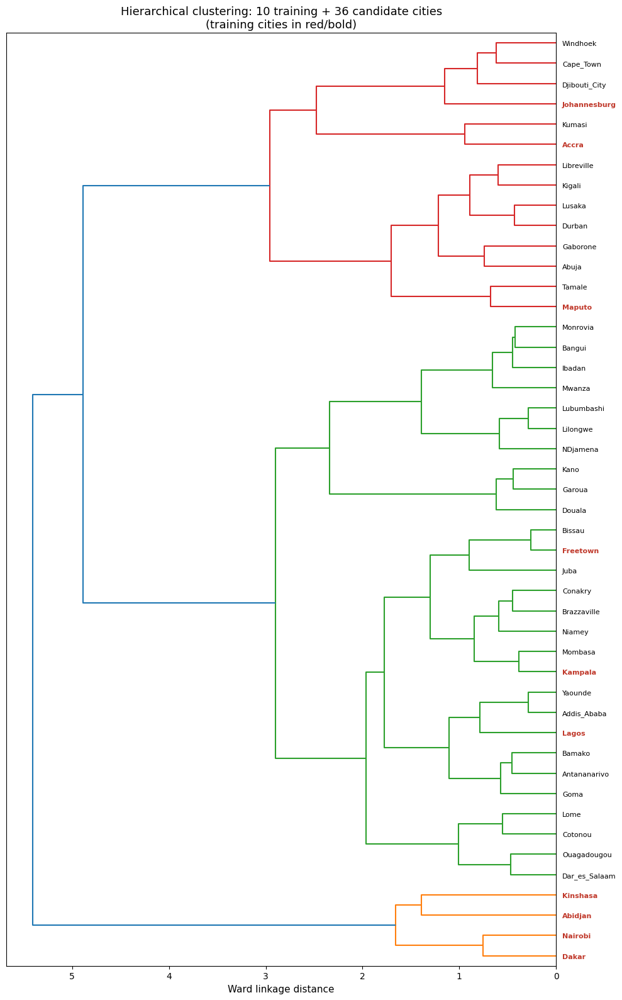

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]

discard = ["Luanda", "Mogadishu", "Harare", "Khartoum", "Benin_City"]

# reuse centroids_df (training + candidate city-level standardised means)
cluster_df = centroids_df[~centroids_df["city"].isin(discard)].copy()
cluster_df = cluster_df.set_index("city")

X = cluster_df[PREDICTORS].to_numpy()
labels = cluster_df.index.tolist()
is_training = cluster_df["group"].eq("training").to_numpy()

# ---- Hierarchical clustering (Ward's method, on standardised 5D city centroids) ----
Z = linkage(X, method="ward", metric="euclidean")

fig, ax = plt.subplots(figsize=(10, 16))
dend = dendrogram(Z, labels=labels, orientation="left", ax=ax, color_threshold=0.7*max(Z[:,2]))

# colour training-city labels red, candidates black, for visual distinction
ax_labels = ax.get_ymajorticklabels()
for lbl in ax_labels:
    city_name = lbl.get_text()
    if city_name in cluster_df.index and cluster_df.loc[city_name, "group"] == "training":
        lbl.set_color("#c0392b")
        lbl.set_fontweight("bold")

ax.set_xlabel("Ward linkage distance", fontsize=11)
ax.set_title("Hierarchical clustering: 10 training + 36 candidate cities\n"
             "(training cities in red/bold)", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.covariance import LedoitWolf

N_REPEATS = 10
rows = []

for held_out in training_data:

    reference_cities = [
        c for c in training_data if c != held_out
    ]

    for repeat in range(N_REPEATS):

        samples = {
            city: training_data[city].sample(
                balanced_n,
                random_state=42 + repeat * 100 + i
            )
            for i, city in enumerate(reference_cities)
        }

        reference = pd.concat(samples.values(), ignore_index=True)
        mu = reference[PREDICTORS].mean()
        sd = reference[PREDICTORS].std()

        reference_z = (reference[PREDICTORS] - mu) / sd

        model = LedoitWolf().fit(reference_z)

        reference_d = np.sqrt(
            model.mahalanobis(reference_z)
        )
        threshold = np.percentile(reference_d, 95)

        held_sample = training_data[held_out].sample(
            balanced_n,
            random_state=1000 + repeat
        )
        held_z = (held_sample[PREDICTORS] - mu) / sd

        held_d = np.sqrt(model.mahalanobis(held_z))

        rows.append({
            "city": held_out,
            "repeat": repeat + 1,
            "pct_beyond": 100 * np.mean(held_d > threshold)
        })

loco = pd.DataFrame(rows)

loco_summary = (
    loco.groupby("city")["pct_beyond"]
        .agg(["mean", "std", "min", "max"])
        .sort_values("mean", ascending=False)
)

print(loco_summary.round(2).to_string())

# Empirical candidate exclusion reference
loco_threshold = np.percentile(
    loco.groupby("city")["pct_beyond"].mean(),
    95
)

print(f"\nEmpirical 95th-percentile threshold: {loco_threshold:.2f}%")

candidate_check = summary_df[
    ["city", "mahalanobis_pct_mean"]
].copy()

candidate_check["above_LOCO_threshold"] = (
    candidate_check["mahalanobis_pct_mean"] > loco_threshold
)

print(
    candidate_check.sort_values(
        "mahalanobis_pct_mean", ascending=False
    ).to_string(index=False)
)

               mean   std    min    max
city                                   
Accra         17.98  0.24  17.62  18.39
Maputo        15.38  0.21  15.15  15.69
Kinshasa      14.47  0.12  14.32  14.66
Nairobi        8.69  0.11   8.48   8.82
Abidjan        7.00  0.14   6.80   7.20
Lagos          5.53  0.10   5.40   5.75
Dakar          1.90  0.05   1.81   1.95
Freetown       1.70  0.04   1.65   1.81
Kampala        1.49  0.05   1.40   1.58
Johannesburg   0.80  0.05   0.72   0.87

Empirical 95th-percentile threshold: 16.81%
         city  mahalanobis_pct_mean  above_LOCO_threshold
       Luanda             25.559700                  True
       Tamale             13.285400                 False
     Lilongwe             12.948350                 False
   Benin_City             12.754550                 False
       Harare             11.964750                 False
     Khartoum             11.353400                 False
       Durban             11.255650                 False
       Lusa

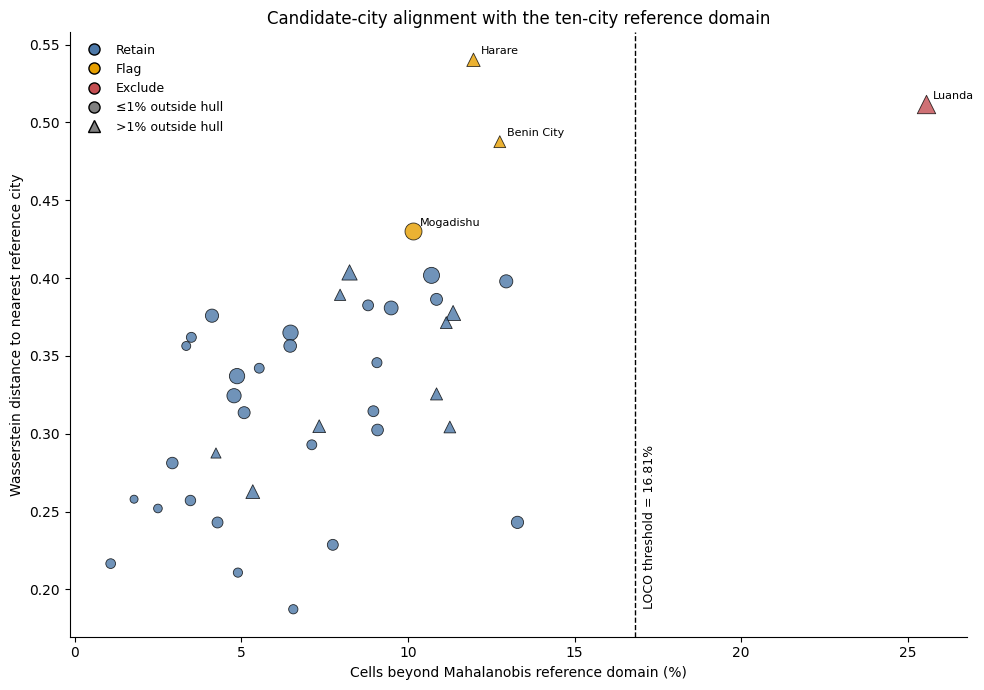

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
d=(summary_df[["city","mahalanobis_pct_mean"]].merge(nearest_wd[["city","mean_wasserstein"]],on="city").merge(composite[["city","pct_outside_hull","knn_pct_beyond_p99"]],on="city"))
flagged=["Harare","Benin_City","Mogadishu"]
d["status"]=np.select([d["mahalanobis_pct_mean"]>loco_threshold,d["city"].isin(flagged)],["Exclude","Flag"],default="Retain")
d["hull_flag"]=d["pct_outside_hull"]>1
colors={"Retain":"#4C78A8","Flag":"#E69F00","Exclude":"#C44E52"}
markers={False:"o",True:"^"}
sizes=25+4*d["knn_pct_beyond_p99"]
fig,ax=plt.subplots(figsize=(10,7))
for status in ["Retain","Flag","Exclude"]:
    for hull_flag in [False,True]:
        s=d[(d["status"]==status)&(d["hull_flag"]==hull_flag)]
        ax.scatter(s["mahalanobis_pct_mean"],s["mean_wasserstein"],s=sizes.loc[s.index],c=colors[status],marker=markers[hull_flag],edgecolor="black",linewidth=.6,alpha=.8,zorder=3)
ax.axvline(loco_threshold,color="black",ls="--",lw=1)
ax.text(loco_threshold+.25,d["mean_wasserstein"].min(),f"LOCO threshold = {loco_threshold:.2f}%",rotation=90,va="bottom",fontsize=9)
for _,r in d[d["status"]!="Retain"].iterrows():
    ax.annotate(r["city"].replace("_"," "),(r["mahalanobis_pct_mean"],r["mean_wasserstein"]),xytext=(5,4),textcoords="offset points",fontsize=8)
ax.set(xlabel="Cells beyond Mahalanobis reference domain (%)",ylabel="Wasserstein distance to nearest reference city",title="Candidate-city alignment with the ten-city reference domain")
ax.spines[["top","right"]].set_visible(False)
legend=[Line2D([0],[0],marker="o",color="none",markerfacecolor=c,markeredgecolor="black",label=k,markersize=8) for k,c in colors.items()]
legend += [Line2D([0],[0],marker="o",color="none",markerfacecolor="grey",label="≤1% outside hull",markersize=8),Line2D([0],[0],marker="^",color="none",markerfacecolor="grey",label=">1% outside hull",markersize=8)]
ax.legend(handles=legend,frameon=False,fontsize=9)
plt.tight_layout()
plt.show()

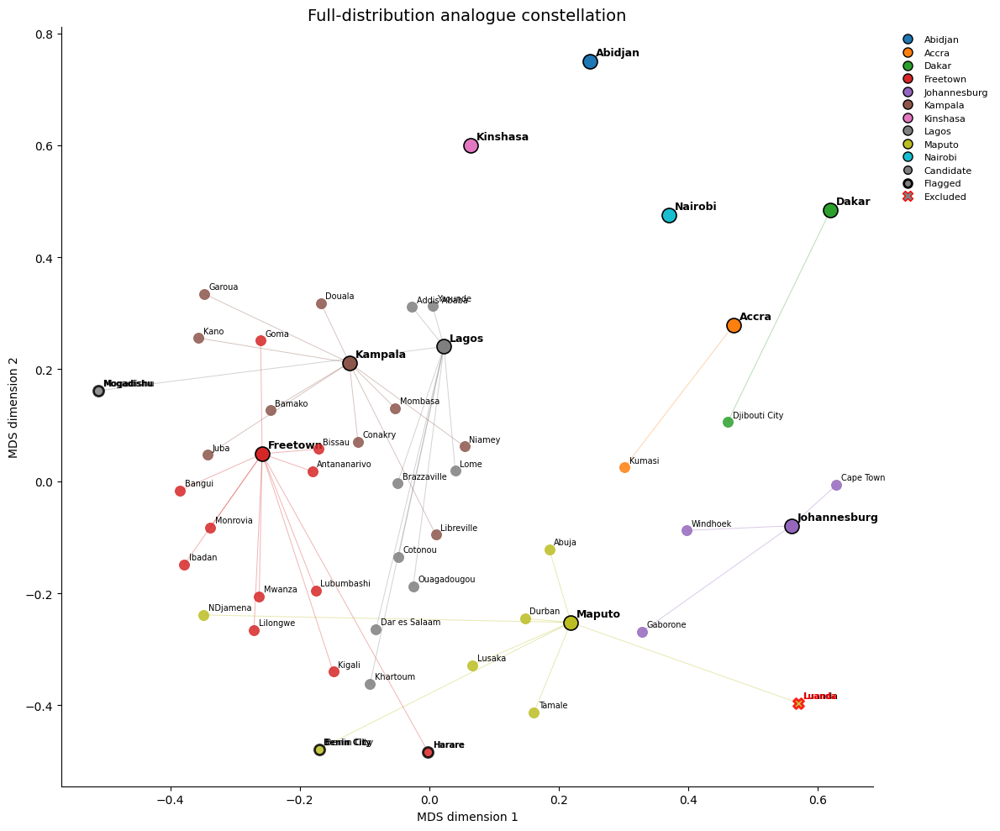

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances
from matplotlib.lines import Line2D
cities=list(train_z)+list(cand_z)
groups=["Reference"]*len(train_z)+["Candidate"]*len(cand_z)
all_z={**train_z,**cand_z}
q=np.linspace(0,1,301)
signatures=np.array([np.concatenate([np.quantile(all_z[c][p],q) for p in PREDICTORS]) for c in cities])
D=pairwise_distances(signatures,metric="manhattan")/signatures.shape[1]
coords=MDS(n_components=2,dissimilarity="precomputed",random_state=42,n_init=10,max_iter=1000).fit_transform(D)
n_ref=len(train_z)
ref_names=cities[:n_ref]
nearest_idx={i:np.argmin(D[i,:n_ref]) for i in range(n_ref,len(cities))}
nearest_ref={cities[i]:ref_names[nearest_idx[i]] for i in range(n_ref,len(cities))}
palette=plt.cm.tab10(np.linspace(0,1,n_ref))
ref_color=dict(zip(ref_names,palette))
flagged={"Harare","Benin_City","Mogadishu"}
excluded={"Luanda"}
fig,ax=plt.subplots(figsize=(12,10))
for i in range(n_ref,len(cities)):
    j=nearest_idx[i]
    ax.plot([coords[i,0],coords[j,0]],[coords[i,1],coords[j,1]],color=ref_color[ref_names[j]],lw=.7,alpha=.35,zorder=1)
for i,c in enumerate(ref_names):
    ax.scatter(*coords[i],s=150,c=[ref_color[c]],edgecolor="black",linewidth=1.2,zorder=4)
    ax.annotate(c.replace("_"," "),coords[i],xytext=(5,5),textcoords="offset points",fontsize=9,fontweight="bold")
for i in range(n_ref,len(cities)):
    c=cities[i]
    analogue=nearest_ref[c]
    marker="X" if c in excluded else "o"
    edge="red" if c in excluded else ("black" if c in flagged else ref_color[analogue])
    lw=2 if c in excluded|flagged else .6
    ax.scatter(*coords[i],s=75,c=[ref_color[analogue]],marker=marker,edgecolor=edge,linewidth=lw,alpha=.85,zorder=3)
    ax.annotate(c.replace("_"," "),coords[i],xytext=(4,4),textcoords="offset points",fontsize=7,color="red" if c in excluded else "black",fontweight="bold" if c in excluded|flagged else "normal",zorder=5)

    if c in excluded|flagged:
        ax.annotate(c.replace("_"," "),coords[i],xytext=(5,4),textcoords="offset points",fontsize=8)
ax.set_title("Full-distribution analogue constellation",fontsize=14)
ax.set_xlabel("MDS dimension 1")
ax.set_ylabel("MDS dimension 2")
ax.spines[["top","right"]].set_visible(False)
legend=[Line2D([0],[0],marker="o",color="none",markerfacecolor=ref_color[c],markeredgecolor="black",label=c,markersize=8) for c in ref_names]
legend += [Line2D([0],[0],marker="o",color="none",markerfacecolor="grey",label="Candidate",markersize=7),Line2D([0],[0],marker="o",color="none",markerfacecolor="grey",markeredgecolor="black",markeredgewidth=2,label="Flagged",markersize=7),Line2D([0],[0],marker="X",color="none",markerfacecolor="grey",markeredgecolor="red",label="Excluded",markersize=8)]
ax.legend(handles=legend,bbox_to_anchor=(1.02,1),loc="upper left",frameon=False,fontsize=8)
plt.tight_layout()
plt.show()

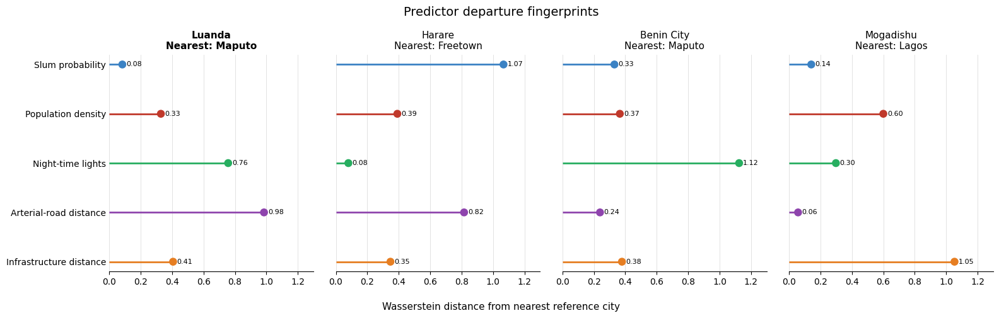

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
focus=["Luanda","Harare","Benin_City","Mogadishu"]
labels={"Slum_probability":"Slum probability","Population":"Population density","NTL_radiance":"Night-time lights","Arterial_road_dist_m":"Arterial-road distance","Infra_distance":"Infrastructure distance"}
colors={"Slum_probability":"#3b82c4","Population":"#c0392b","NTL_radiance":"#27ae60","Arterial_road_dist_m":"#8e44ad","Infra_distance":"#e67e22"}
sub=nearest_wd.set_index("city").loc[focus]
xmax=np.ceil(sub[PREDICTORS].to_numpy().max()*10)/10+0.1
fig,axes=plt.subplots(1,4,figsize=(16,5),sharex=True,sharey=True)
for ax,city in zip(axes,focus):
    vals=sub.loc[city,PREDICTORS].astype(float)
    order=np.arange(len(PREDICTORS))[::-1]
    ax.hlines(order,0,vals,color=[colors[p] for p in PREDICTORS],lw=2)
    ax.scatter(vals,order,c=[colors[p] for p in PREDICTORS],s=65,zorder=3)
    for x,y in zip(vals,order): ax.text(x+.025,y,f"{x:.2f}",va="center",fontsize=8)
    ax.set_title(f"{city.replace('_',' ')}\nNearest: {sub.loc[city,'reference'].replace('_',' ')}",fontsize=11,fontweight="bold" if city=="Luanda" else "normal")
    ax.set_xlim(0,xmax)
    ax.grid(axis="x",color="#dddddd",lw=.6)
    ax.spines[["top","right","left"]].set_visible(False)
    ax.tick_params(axis="y",length=0)
axes[0].set_yticks(np.arange(len(PREDICTORS))[::-1],labels=[labels[p] for p in PREDICTORS])
fig.supxlabel("Wasserstein distance from nearest reference city",fontsize=11)
fig.suptitle("Predictor departure fingerprints",fontsize=14)
plt.tight_layout()
plt.show()

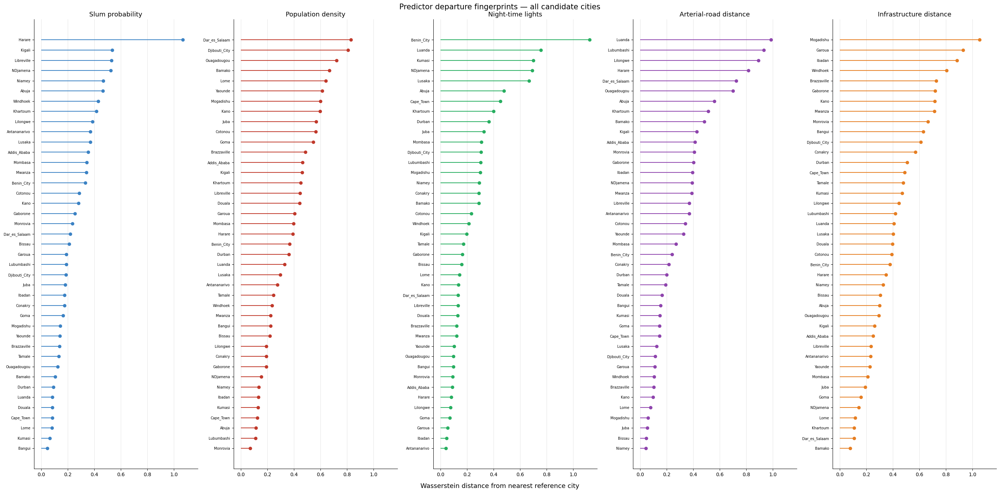

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# reuse nearest_wd (already computed: per-candidate nearest-reference Wasserstein distances)
PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]
labels = {"Slum_probability": "Slum probability", "Population": "Population density",
          "NTL_radiance": "Night-time lights", "Arterial_road_dist_m": "Arterial-road distance",
          "Infra_distance": "Infrastructure distance"}
colors = {"Slum_probability": "#3b82c4", "Population": "#c0392b", "NTL_radiance": "#27ae60",
          "Arterial_road_dist_m": "#8e44ad", "Infra_distance": "#e67e22"}

fig, axes = plt.subplots(1, len(PREDICTORS), figsize=(28, 14), sharex=True)

for ax, pred in zip(axes, PREDICTORS):
    sub = nearest_wd[["city", pred]].sort_values(pred)
    ax.hlines(sub["city"], 0, sub[pred], color=colors[pred], lw=1.5)
    ax.scatter(sub[pred], sub["city"], color=colors[pred], s=35, zorder=3)
    ax.set_title(labels[pred], fontsize=13)
    ax.tick_params(axis='y', labelsize=7)
    ax.tick_params(axis='x', labelsize=10)
    ax.grid(axis="x", color="#dddddd", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)

fig.supxlabel("Wasserstein distance from nearest reference city", fontsize=13)
fig.suptitle("Predictor departure fingerprints — all candidate cities", fontsize=15)
plt.tight_layout()
plt.show()

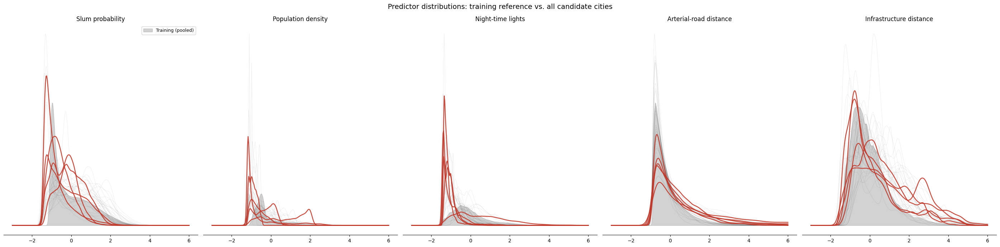

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]
labels = {"Slum_probability": "Slum probability", "Population": "Population density",
          "NTL_radiance": "Night-time lights", "Arterial_road_dist_m": "Arterial-road distance",
          "Infra_distance": "Infrastructure distance"}

highlight_cities = ["Luanda", "Mogadishu", "Harare", "Khartoum", "Benin_City"]

fig, axes = plt.subplots(1, len(PREDICTORS), figsize=(28, 7))

train_mean = pooled_train[PREDICTORS].mean()
train_std = pooled_train[PREDICTORS].std()
pooled_train_z = (pooled_train[PREDICTORS] - train_mean) / train_std


for ax, pred in zip(axes, PREDICTORS):
    # pooled training reference (shaded)
    train_vals = train_z_full[pred] if 'train_z_full' in dir() else None  # see note below
    xs = np.linspace(-3, 6, 300)  # z-score range; adjust if needed after first run

    train_kde = gaussian_kde(pooled_train_z[pred])  # pooled, unbalanced training z-scores
    ax.fill_between(xs, train_kde(xs), color="grey", alpha=0.35, label="Training (pooled)")

    for city, df in cand_z.items():
        kde = gaussian_kde(df[pred])
        is_highlight = city in highlight_cities
        ax.plot(xs, kde(xs),
                color="#c0392b" if is_highlight else "black",
                alpha=0.9 if is_highlight else 0.08,
                linewidth=1.8 if is_highlight else 0.6,
                zorder=5 if is_highlight else 2)

    ax.set_title(labels[pred], fontsize=12)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)

axes[0].legend(fontsize=9, loc="upper right")
fig.suptitle("Predictor distributions: training reference vs. all candidate cities", fontsize=14)
plt.tight_layout()
plt.show()

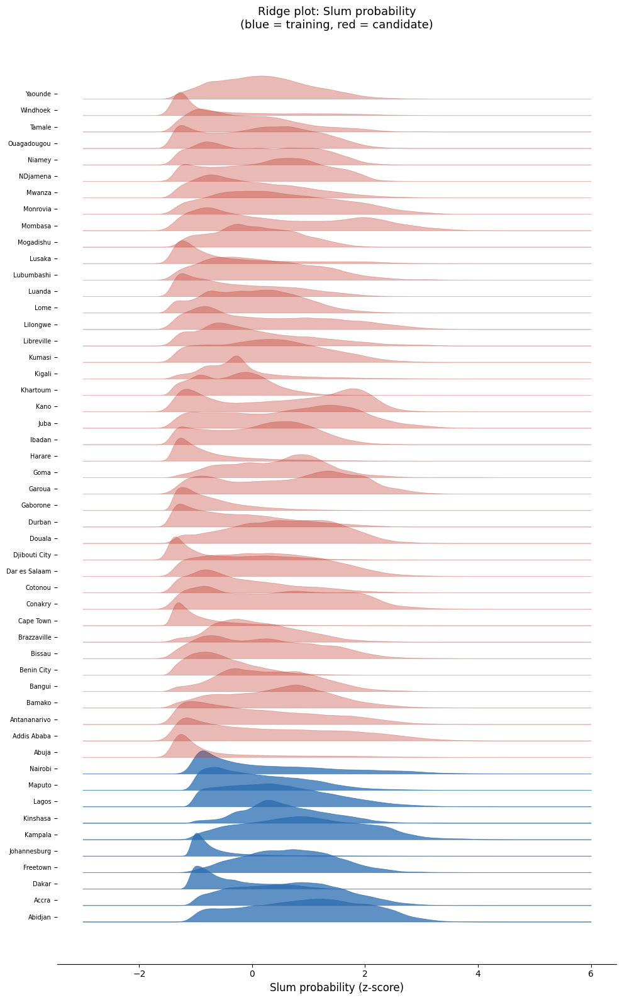

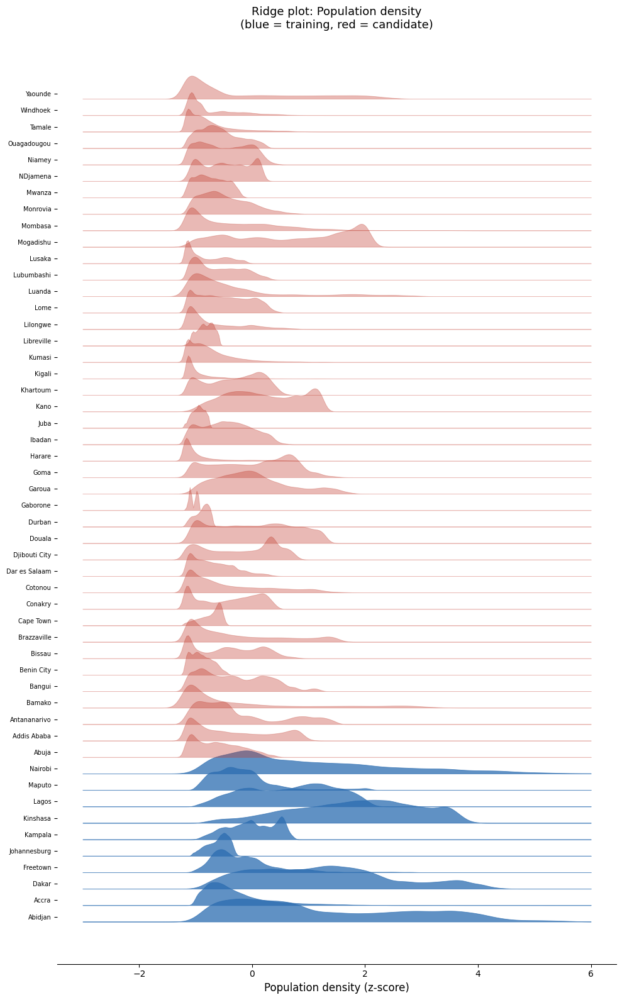

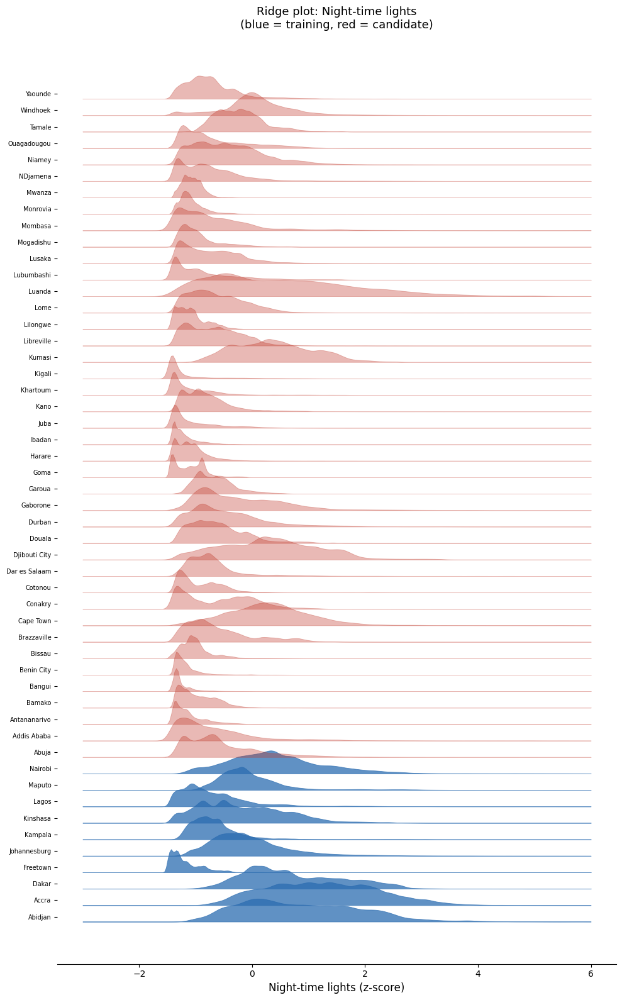

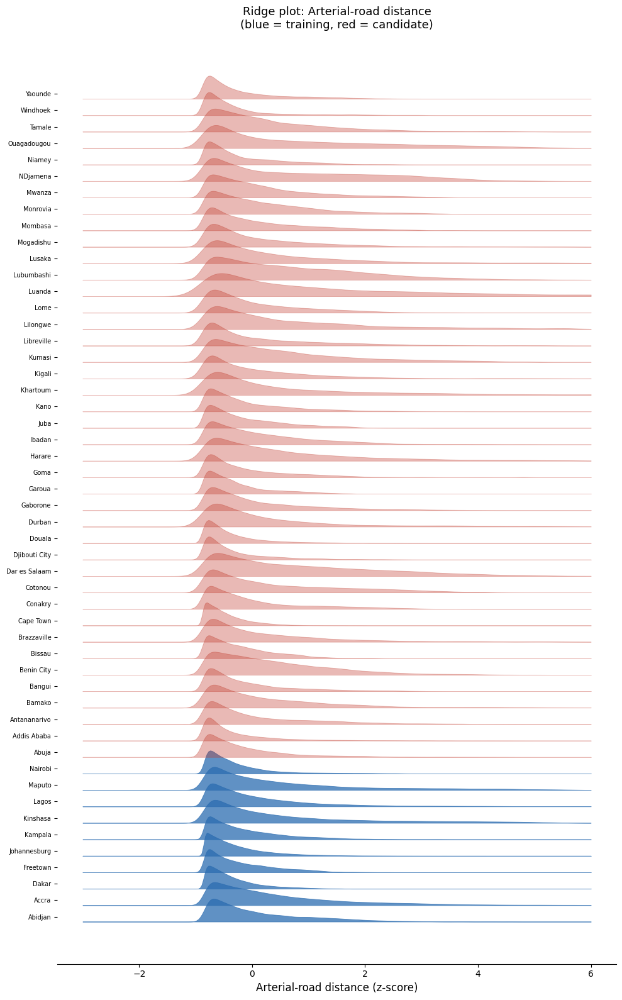

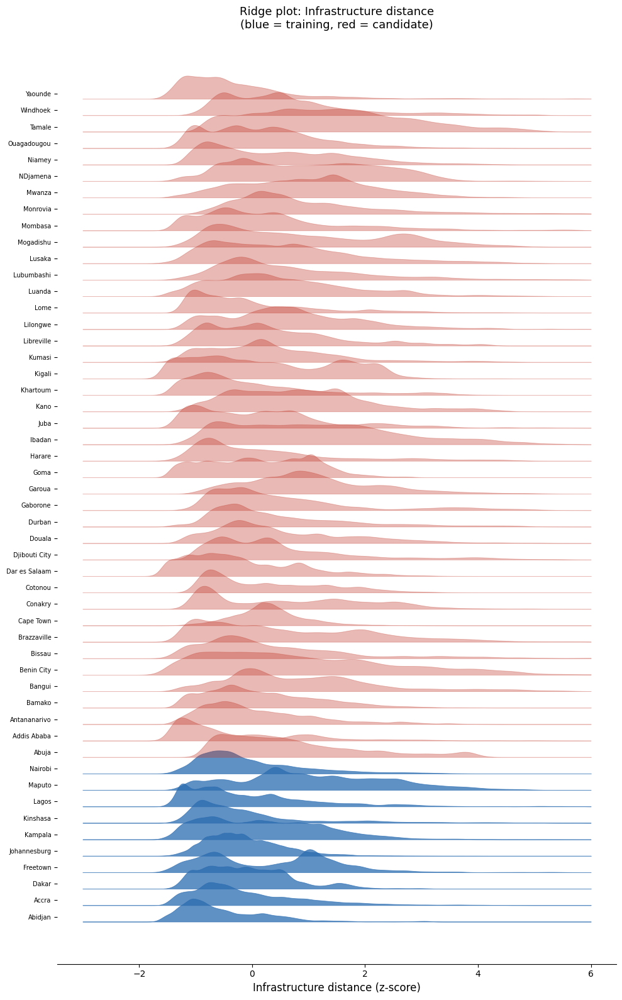

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]
labels = {"Slum_probability": "Slum probability", "Population": "Population density",
          "NTL_radiance": "Night-time lights", "Arterial_road_dist_m": "Arterial-road distance",
          "Infra_distance": "Infrastructure distance"}

# ---- Build standardised z-scores per training city (using pooled mean/std as reference) ----
train_city_z = {
    city: (df[PREDICTORS] - train_mean) / train_std
    for city, df in training_data.items()
}

all_city_z = {**train_city_z, **cand_z}  # cand_z already standardised, from earlier session work
city_order = list(train_city_z.keys()) + sorted(cand_z.keys())
is_training = {c: (c in train_city_z) for c in city_order}

# ---- One ridge plot per predictor ----
for pred in PREDICTORS:
    fig, ax = plt.subplots(figsize=(10, 16))

    xs = np.linspace(-3, 6, 300)
    y_step = 1.0
    overlap = 1.4  # controls how much each ridge overlaps the one below

    for i, city in enumerate(city_order):
        vals = all_city_z[city][pred].dropna()
        if len(vals) < 10:
            continue
        kde = gaussian_kde(vals)
        density = kde(xs)
        density = density / density.max() * overlap  # normalise height, allow overlap

        y_base = i * y_step
        color = "#2b6cb0" if is_training[city] else "#c0392b"
        alpha = 0.75 if is_training[city] else 0.35
        ax.fill_between(xs, y_base, y_base + density, color=color, alpha=alpha, linewidth=0.6,
                         edgecolor=color)

    ax.set_yticks([i * y_step + 0.3 for i in range(len(city_order))])
    ax.set_yticklabels([c.replace("_", " ") for c in city_order], fontsize=7)
    ax.set_xlabel(f"{labels[pred]} (z-score)", fontsize=12)
    ax.set_title(f"Ridge plot: {labels[pred]}\n(blue = training, red = candidate)", fontsize=13)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import pandas as pd

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]

# ---- Per-predictor spread of training-city MEANS (standardised z-scores) ----
train_city_means = centroids_df[centroids_df["group"] == "training"].set_index("city")[PREDICTORS]

heterogeneity_summary = pd.DataFrame({
    "min_city_mean": train_city_means.min(),
    "max_city_mean": train_city_means.max(),
    "range": train_city_means.max() - train_city_means.min(),
    "sd_across_cities": train_city_means.std(),
})
heterogeneity_summary = heterogeneity_summary.round(3)
print("Spread of training-city mean profiles, per predictor (z-score units):\n")
print(heterogeneity_summary.to_string())

# ---- Cross-reference with the centroid-distance benchmark already computed ----
train_dist = centroids_df[centroids_df["group"] == "training"]["distance_5pc"]
print(f"\nTraining-city centroid distance from reference centroid (5PC):")
print(f"  range: {train_dist.min():.3f} to {train_dist.max():.3f}")
print(f"  mean: {train_dist.mean():.3f}, median: {train_dist.median():.3f}, sd: {train_dist.std():.3f}")

Spread of training-city mean profiles, per predictor (z-score units):

                      min_city_mean  max_city_mean  range  sd_across_cities
Slum_probability             -0.631          0.949  1.580             0.536
Population                   -0.605          1.846  2.451             0.847
NTL_radiance                 -1.185          1.252  2.437             0.769
Arterial_road_dist_m         -0.358          0.555  0.914             0.364
Infra_distance               -0.509          1.110  1.619             0.428

Training-city centroid distance from reference centroid (5PC):
  range: 0.791 to 1.979
  mean: 1.441, median: 1.417, sd: 0.391


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull, cKDTree
from scipy.stats import chi2, wasserstein_distance

PREDICTORS = ["Slum_probability", "Population", "NTL_radiance",
              "Arterial_road_dist_m", "Infra_distance"]

train_base = "/content/drive/MyDrive/Paper_3/Data/Master/2024"
file_overrides = {"Johannesburg": "johannesburg_master_2024_v1.csv"}
training_cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
                    "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

candidate_folder = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
marginal_cities = ["Lusaka", "Ibadan", "Durban", "Tamale", "Lilongwe", "Dar_es_Salaam",
                    "Djibouti_City", "Juba", "NDjamena", "Garoua", "Kano", "Bamako", "Kigali"]

# ---- 1. Load training data, build reference distributions ----
training_data = {}
for city in training_cities:
    fname = file_overrides.get(city, f"{city.lower()}_master_2024.csv")
    path = os.path.join(train_base, city, fname)
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    training_data[city] = df
    print(f"{city}: {len(df):,} complete cells")

pooled_train = pd.concat(training_data.values(), ignore_index=True)
train_mean = pooled_train[PREDICTORS].mean()
train_std = pooled_train[PREDICTORS].std()
train_z = (pooled_train[PREDICTORS] - train_mean) / train_std

# Mahalanobis reference
mean_z = train_z.mean().to_numpy()
cov_z = np.cov(train_z.to_numpy(), rowvar=False)
inv_cov = np.linalg.inv(cov_z)

def mahalanobis_sq(X, mean, inv_cov):
    diff = X - mean
    return np.einsum("ij,jk,ik->i", diff, inv_cov, diff)

DF = len(PREDICTORS)
mahal_threshold = chi2.ppf(0.99, df=DF)

# PCA (full 5 components)
pca_full = PCA(n_components=5)
pca_full.fit(train_z)
train_scores_full = pca_full.transform(train_z)

def mahalanobis_sq_pcspace(scores, n_components):
    eigvals = pca_full.explained_variance_[:n_components]
    s = scores[:, :n_components]
    return np.sum((s ** 2) / eigvals, axis=1)

# Convex hull (2D PC space, 50k training subsample)
rng = np.random.default_rng(42)
hull_sample_idx = rng.choice(len(train_scores_full), size=50_000, replace=False)
hull = ConvexHull(train_scores_full[hull_sample_idx][:, :2])

def in_hull(points, hull):
    A = hull.equations[:, :-1]
    b = hull.equations[:, -1]
    return np.all(np.add(points @ A.T, b) <= 1e-9, axis=1)

# kNN tree (100k training subsample) + self-distance threshold
knn_sample_idx = rng.choice(len(train_z), size=100_000, replace=False)
knn_sample = train_z.iloc[knn_sample_idx][PREDICTORS].to_numpy()
tree = cKDTree(knn_sample)
self_dist, _ = tree.query(knn_sample, k=2)
p99_self = np.percentile(self_dist[:, 1], 99)

# Balanced training sample for Wasserstein (50k per city, matching earlier script)
balanced_n = min(50_000, min(len(df) for df in training_data.values()))
balanced_train = {c: df.sample(balanced_n, random_state=42) for c, df in training_data.items()}
train_mu, train_sd = pd.concat(balanced_train.values())[PREDICTORS].mean(), pd.concat(balanced_train.values())[PREDICTORS].std()
train_z_balanced = {c: (df[PREDICTORS] - train_mu) / train_sd for c, df in balanced_train.items()}

# training centroids (for PC-space centroid distance)
train_centroid_rows = []
for city, df in training_data.items():
    z = (df[PREDICTORS].mean() - train_mean) / train_std
    train_centroid_rows.append({"city": city, **z.to_dict()})
train_centroids_df = pd.DataFrame(train_centroid_rows)

print("\nReference distributions built.")

Abidjan: 116,845 complete cells
Accra: 585,395 complete cells
Dakar: 172,203 complete cells
Freetown: 126,537 complete cells
Johannesburg: 2,396,008 complete cells
Kampala: 364,939 complete cells
Kinshasa: 285,262 complete cells
Lagos: 911,782 complete cells
Maputo: 310,369 complete cells
Nairobi: 162,842 complete cells

Reference distributions built.


In [ ]:
import os
import pandas as pd
import numpy as np

results = []
for city in marginal_cities:
    path = os.path.join(candidate_folder, f"{city}_grid_30m.csv")
    df = pd.read_csv(path, usecols=PREDICTORS).dropna(subset=PREDICTORS)
    z = (df[PREDICTORS] - train_mean) / train_std

    # Mahalanobis (raw 5D)
    d2 = mahalanobis_sq(z.to_numpy(), mean_z, inv_cov)
    mahal_pct = 100 * np.mean(d2 > mahal_threshold)

    # Convex hull (2D PC space)
    scores_2d = pca_full.transform(z)[:, :2]
    inside = in_hull(scores_2d, hull)
    hull_pct = 100 * (1 - inside.mean())

    # kNN (p99 threshold)
    dist, _ = tree.query(z.to_numpy(), k=1)
    knn_pct = 100 * np.mean(dist > p99_self)

    # PC-space centroid distance (5-component)
    centroid_z = (df[PREDICTORS].mean() - train_mean) / train_std
    centroid_score = pca_full.transform([centroid_z])[0]
    eigvals = pca_full.explained_variance_
    centroid_dist_5pc = np.sqrt(np.sum((centroid_score ** 2) / eigvals))

    # Wasserstein (balanced, nearest training-city analogue)
    df_sample = df.sample(min(100_000, len(df)), random_state=42)
    cand_z_balanced = (df_sample[PREDICTORS] - train_mu) / train_sd
    best_mean_wd = np.inf
    for ref_city, ref_z in train_z_balanced.items():
        dists = [wasserstein_distance(cand_z_balanced[p], ref_z[p]) for p in PREDICTORS]
        mean_wd = np.mean(dists)
        if mean_wd < best_mean_wd:
            best_mean_wd = mean_wd

    results.append({
        "city": city,
        "mahalanobis_pct": mahal_pct,
        "hull_pct": hull_pct,
        "knn_pct_p99": knn_pct,
        "pc_centroid_dist_5pc": centroid_dist_5pc,
        "wasserstein_mean": best_mean_wd,
    })
    print(f"{city} done")

review_table = pd.DataFrame(results).set_index("city")

for col in review_table.columns:
    review_table[f"{col}_rank"] = review_table[col].rank(pct=True)

rank_cols = [c for c in review_table.columns if c.endswith("_rank")]
review_table["convergence_score"] = review_table[rank_cols].mean(axis=1)
review_table["n_metrics_top_quartile"] = (review_table[rank_cols] >= 0.75).sum(axis=1)

review_table = review_table.sort_values("convergence_score", ascending=False)
pd.set_option("display.width", 180)
print(review_table[["mahalanobis_pct", "hull_pct", "knn_pct_p99", "pc_centroid_dist_5pc",
                     "wasserstein_mean", "convergence_score", "n_metrics_top_quartile"]].round(3).to_string())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


Lusaka done


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


Ibadan done


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


...

Kano done


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


Bamako done


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


Kigali done
               mahalanobis_pct  hull_pct  knn_pct_p99  pc_centroid_dist_5pc  wasserstein_mean  convergence_score  n_metrics_top_quartile
city                                                                                                                                    
Dar_es_Salaam           11.060     0.410       26.961                 1.603             0.402              0.692                       2
Djibouti_City            8.888     1.643       22.013                 1.269             0.404              0.646                       3
Lilongwe                13.874     0.846       16.017                 1.421             0.398              0.631                       2
Juba                    10.921     1.332       21.293                 1.937             0.262              0.600                       1
Ibadan                  12.405     1.400       12.510                 1.617             0.324              0.585                       2
Tamale                  14.97

In [ ]:
import os
import glob

GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
MODEL_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction"

exclude = ["Luanda", "Mogadishu", "Harare", "Khartoum", "Benin_City"]

all_paths = sorted(glob.glob(os.path.join(GRID_DIR, "*.csv")))
all_cities = [os.path.basename(p).replace("_grid_30m.csv", "") for p in all_paths]
run_cities = [c for c in all_cities if c not in exclude]

print(f"Total grid files found: {len(all_cities)}")
print(f"Excluded: {exclude}")
print(f"Cities to run: {len(run_cities)}")
print(run_cities)

# quick check that each city folder has a population raster (for later use, sanity check only)
missing_pop_raster = []
for city in run_cities:
    city_folder = os.path.join("/content/drive/MyDrive/Paper_3/Data/Test_cities", city)
    if os.path.isdir(city_folder):
        tifs = glob.glob(os.path.join(city_folder, "*pop*.tif"))
        if not tifs:
            missing_pop_raster.append(city)
    else:
        missing_pop_raster.append(f"{city} (folder not found)")

print(f"\nCities missing an identifiable population raster: {missing_pop_raster}")

Total grid files found: 41
Excluded: ['Luanda', 'Mogadishu', 'Harare', 'Khartoum', 'Benin_City']
Cities to run: 36
['Abuja', 'Addis_Ababa', 'Antananarivo', 'Bamako', 'Bangui', 'Bissau', 'Brazzaville', 'Cape_Town', 'Conakry', 'Cotonou', 'Dar_es_Salaam', 'Djibouti_City', 'Douala', 'Durban', 'Gaborone', 'Garoua', 'Goma', 'Ibadan', 'Juba', 'Kano', 'Kigali', 'Kumasi', 'Libreville', 'Lilongwe', 'Lome', 'Lubumbashi', 'Lusaka', 'Mombasa', 'Monrovia', 'Mwanza', 'NDjamena', 'Niamey', 'Ouagadougou', 'Tamale', 'Windhoek', 'Yaounde']

Cities missing an identifiable population raster: ['Abuja', 'Antananarivo', 'Bamako', 'Bangui', 'Bissau', 'Brazzaville', 'Cape_Town (folder not found)', 'Conakry', 'Cotonou', 'Dar_es_Salaam', 'Djibouti_City (folder not found)', 'Durban', 'Gaborone', 'Garoua', 'Goma', 'Juba', 'Kano', 'Kigali', 'Kumasi', 'Libreville', 'Lilongwe', 'Lome', 'Lubumbashi', 'Mombasa', 'Monrovia', 'Mwanza', 'NDjamena', 'Niamey', 'Ouagadougou', 'Tamale', 'Windhoek', 'Yaounde']


In [ ]:
import os
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
MODEL_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction"

top5_predictors = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]
RENAME_MAP = {
    "Slum_probability": "Slum",
    "NTL_radiance": "NTL",
    "Arterial_road_dist_m": "Arterial_roads",
}

run_cities = ['Abuja', 'Addis_Ababa', 'Antananarivo', 'Bamako', 'Bangui', 'Bissau', 'Brazzaville',
              'Cape_Town', 'Conakry', 'Cotonou', 'Dar_es_Salaam', 'Djibouti_City', 'Douala', 'Durban',
              'Gaborone', 'Garoua', 'Goma', 'Ibadan', 'Juba', 'Kano', 'Kigali', 'Kumasi', 'Libreville',
              'Lilongwe', 'Lome', 'Lubumbashi', 'Lusaka', 'Mombasa', 'Monrovia', 'Mwanza', 'NDjamena',
              'Niamey', 'Ouagadougou', 'Tamale', 'Windhoek', 'Yaounde']

# ---- Load model once ----
final_model = xgb.XGBClassifier()
final_model.load_model(f"{MODEL_DIR}/full10city_top5_xgb_model.json")

prob_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Probability", ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"], N=256
)

# ---- Predict for each city, store in memory ----
predictions = {}
summary_rows = []

for city in run_cities:
    df = pd.read_csv(f"{GRID_DIR}/{city}_grid_30m.csv")
    df = df.rename(columns=RENAME_MAP)

    missing_cols = [p for p in top5_predictors if p not in df.columns]
    if missing_cols:
        print(f"SKIPPING {city}: missing columns {missing_cols}")
        continue

    df = df.dropna(subset=top5_predictors)  # XGBoost can handle NaN, but keep consistent w/ earlier steps
    X_new = df[top5_predictors]
    df["pred_proba"] = final_model.predict_proba(X_new)[:, 1]

    predictions[city] = df
    summary_rows.append({
        "city": city,
        "n_cells": len(df),
        "mean_pred_proba": df["pred_proba"].mean(),
        "pct_above_0.5": 100 * (df["pred_proba"] > 0.5).mean(),
        "pct_above_0.75": 100 * (df["pred_proba"] > 0.75).mean(),
    })
    print(f"{city}: done ({len(df):,} cells, mean p={df['pred_proba'].mean():.3f})")

summary_df = pd.DataFrame(summary_rows).sort_values("mean_pred_proba", ascending=False)
print("\n" + summary_df.to_string(index=False))

Abuja: done (529,788 cells, mean p=0.353)
Addis_Ababa: done (585,871 cells, mean p=0.467)
Antananarivo: done (246,923 cells, mean p=0.418)
Bamako: done (549,868 cells, mean p=0.380)
Bangui: done (111,470 cells, mean p=0.347)
Bissau: done (68,467 cells, mean p=0.434)
Brazzaville: done (242,670 cells, mean p=0.377)
Cape_Town: done (689,524 cells, mean p=0.317)
Conakry: done (327,095 cells, mean p=0.327)
Cotonou: done (389,593 cells, mean p=0.371)
Dar_es_Salaam: done (1,172,840 cells, mean p=0.369)
Djibouti_City: done (61,160 cells, mean p=0.347)
Douala: done (252,827 cells, mean p=0.470)
Durban: done (881,000 cells, mean p=0.284)
Gaborone: done (166,188 cells, mean p=0.336)
Garoua: done (47,602 cells, mean p=0.398)
Goma: done (70,243 cells, mean p=0.504)
Ibadan: done (657,101 cells, mean p=0.323)
Juba: done (132,238 cells, mean p=0.279)
Kano: done (314,301 cells, mean p=0.428)
Kigali: done (986,524 cells, mean p=0.186)
Kumasi: done (611,730 cells, mean p=0.294)
Libreville: done (242,609 

In [ ]:
# ---- Plot: 3-column grid of hexbin maps, view-only ----
n_cities = len(predictions)
n_cols = 3
n_rows = int(np.ceil(n_cities / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5.5 * n_rows))
axes = axes.flatten()

for ax, (city, df) in zip(axes, predictions.items()):
    hb = ax.hexbin(df["longitude"], df["latitude"], C=df["pred_proba"],
                    reduce_C_function=np.mean, gridsize=100, mincnt=1,
                    cmap=prob_cmap, vmin=0, vmax=1, linewidths=0)
    ax.set_title(city, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal")

# hide unused axes
for ax in axes[n_cities:]:
    ax.axis("off")

fig.suptitle("Predicted waste-presence probability — candidate cities", fontsize=15)
cbar = fig.colorbar(hb, ax=axes, fraction=0.015, pad=0.01, shrink=0.6)
cbar.set_label("Predicted probability", fontsize=11)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# ---- Discrete threshold colour scheme ----
# <0.5 = low risk (grey), 0.5-0.75 = yellow, 0.75-0.9 = orange, >=0.9 = red
bounds = [0, 0.5, 0.75, 0.9, 1.0]
colors = ["#d9d9d9", "#ffd166", "#f4a261", "#d62828"]
cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

n_cities = len(predictions)
n_cols = 3
n_rows = int(np.ceil(n_cities / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5.5 * n_rows))
axes = axes.flatten()

for ax, (city, df) in zip(axes, predictions.items()):
    hb = ax.hexbin(df["longitude"], df["latitude"], C=df["pred_proba"],
                    reduce_C_function=np.mean, gridsize=100, mincnt=1,
                    cmap=cmap, norm=norm, linewidths=0)
    ax.set_title(city, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal")

for ax in axes[n_cities:]:
    ax.axis("off")

fig.suptitle("Predicted waste-presence probability — candidate cities\n"
             "(grey <0.5, yellow 0.5–0.75, orange 0.75–0.9, red ≥0.9)", fontsize=14)

# ---- Custom legend instead of a continuous colourbar ----
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#d9d9d9", label="< 0.5"),
    Patch(facecolor="#ffd166", label="0.5 – 0.75"),
    Patch(facecolor="#f4a261", label="0.75 – 0.9"),
    Patch(facecolor="#d62828", label="≥ 0.9"),
]
fig.legend(handles=legend_elements, loc="upper right", fontsize=11, title="Predicted probability")

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import skew

rows = []
for city, df in predictions.items():
    p = df["pred_proba"].to_numpy()
    rows.append({
        "city": city,
        "std": p.std(),
        "iqr": np.percentile(p, 75) - np.percentile(p, 25),
        "pct_in_uncertain_band": 100 * np.mean((p > 0.4) & (p < 0.6)),  # "flat/undifferentiated" zone
        "skew": skew(p),
    })

pillar_c = pd.DataFrame(rows).set_index("city")

# flag cities in the bottom quartile of spread (std/IQR) AND top quartile of "stuck near 0.5" —
# i.e. distributions that look compressed/undifferentiated relative to the rest of the candidate set
pillar_c["std_rank"] = pillar_c["std"].rank(pct=True)
pillar_c["iqr_rank"] = pillar_c["iqr"].rank(pct=True)
pillar_c["uncertain_band_rank"] = pillar_c["pct_in_uncertain_band"].rank(pct=True)

pillar_c["flat_flag"] = (
    (pillar_c["std_rank"] < 0.25) &
    (pillar_c["iqr_rank"] < 0.25) &
    (pillar_c["uncertain_band_rank"] > 0.75)
)

pillar_c = pillar_c.sort_values("std")
pd.set_option("display.width", 160)
print(pillar_c[["std", "iqr", "pct_in_uncertain_band", "skew", "flat_flag"]].round(3).to_string())

print(f"\nCities flagged as having an unusually flat/undifferentiated prediction distribution: "
      f"{pillar_c[pillar_c['flat_flag']].index.tolist()}")

                 std    iqr  pct_in_uncertain_band   skew  flat_flag
city                                                                
Cape_Town      0.169  0.241                 24.475  0.401      False
Tamale         0.178  0.248                 17.317  0.777      False
Durban         0.192  0.314                 23.872  0.250      False
Libreville     0.200  0.341                 23.396  0.317      False
Kumasi         0.202  0.304                 21.982  0.598      False
Mwanza         0.213  0.341                 16.209  0.786      False
Gaborone       0.217  0.381                 32.507  0.044      False
Niamey         0.219  0.389                 32.423 -0.032      False
Ouagadougou    0.222  0.394                 31.045 -0.015      False
Windhoek       0.223  0.373                 27.604  0.196      False
Abuja          0.230  0.396                 29.879  0.015      False
Djibouti_City  0.231  0.410                 25.607  0.050      False
Lome           0.237  0.409       

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import skew

out_dir = "/content/drive/MyDrive/Paper_3/Miscellaneous"
cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

# ---- Load training cities' genuine out-of-sample (LOCO) prediction distributions ----
train_shape_rows = []
for city in cities:
    df = pd.read_csv(f"{out_dir}/{city.lower()}_loco_predictions.csv", usecols=["pred_proba"])
    p = df["pred_proba"].to_numpy()
    train_shape_rows.append({
        "city": city, "group": "training",
        "std": p.std(), "iqr": np.percentile(p, 75) - np.percentile(p, 25),
        "pct_in_uncertain_band": 100 * np.mean((p > 0.4) & (p < 0.6)),
        "skew": skew(p),
    })

train_shape_df = pd.DataFrame(train_shape_rows).set_index("city")
print("Training cities (genuine out-of-sample LOCO prediction distributions):")
print(train_shape_df[["std", "iqr", "pct_in_uncertain_band", "skew"]].round(3).to_string())

# ---- Candidate distribution shape stats (already computed, reuse `pillar_c` if still in session) ----
# if not in session, rebuild from `predictions` dict:
cand_rows = []
for city, df in predictions.items():
    p = df["pred_proba"].to_numpy()
    cand_rows.append({
        "city": city, "group": "candidate",
        "std": p.std(), "iqr": np.percentile(p, 75) - np.percentile(p, 25),
        "pct_in_uncertain_band": 100 * np.mean((p > 0.4) & (p < 0.6)),
        "skew": skew(p),
    })
cand_shape_df = pd.DataFrame(cand_rows).set_index("city")

# ---- Define "flat/undifferentiated" using the TRAINING set's own range as the benchmark ----
train_std_min, train_std_max = train_shape_df["std"].min(), train_shape_df["std"].max()
train_iqr_min, train_iqr_max = train_shape_df["iqr"].min(), train_shape_df["iqr"].max()
train_band_min, train_band_max = train_shape_df["pct_in_uncertain_band"].min(), train_shape_df["pct_in_uncertain_band"].max()

print(f"\nTraining-city benchmark range: std [{train_std_min:.3f}, {train_std_max:.3f}], "
      f"IQR [{train_iqr_min:.3f}, {train_iqr_max:.3f}], "
      f"uncertain-band% [{train_band_min:.1f}, {train_band_max:.1f}]")

cand_shape_df["flat_flag"] = (
    (cand_shape_df["std"] < train_std_min) &
    (cand_shape_df["iqr"] < train_iqr_min) &
    (cand_shape_df["pct_in_uncertain_band"] > train_band_max)
)

cand_shape_df = cand_shape_df.sort_values("std")
pd.set_option("display.width", 160)
print("\nCandidate cities vs. training-city benchmark range:")
print(cand_shape_df[["std", "iqr", "pct_in_uncertain_band", "skew", "flat_flag"]].round(3).to_string())

print(f"\nCandidates falling entirely outside the training cities' own distribution-shape range "
      f"(std, IQR, AND uncertain-band% all more extreme than any training city): "
      f"{cand_shape_df[cand_shape_df['flat_flag']].index.tolist()}")

Training cities (genuine out-of-sample LOCO prediction distributions):
                std    iqr  pct_in_uncertain_band   skew
city                                                    
Abidjan       0.293  0.497                 19.568 -0.085
Accra         0.268  0.467                 20.608 -0.040
Dakar         0.268  0.436                 21.640 -0.306
Freetown      0.337  0.684                 14.055  0.173
Johannesburg  0.186  0.276                 38.072 -0.170
Kampala       0.233  0.299                 25.063 -0.645
Kinshasa      0.274  0.400                 26.892 -0.336
Lagos         0.315  0.572                 16.614 -0.124
Maputo        0.247  0.405                 25.270  0.246
Nairobi       0.264  0.422                 24.527 -0.111

Training-city benchmark range: std [0.186, 0.337], IQR [0.276, 0.684], uncertain-band% [14.1, 38.1]

Candidate cities vs. training-city benchmark range:
                 std    iqr  pct_in_uncertain_band   skew  flat_flag
city                  

In [ ]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import shapes as rio_shapes
from rasterio.mask import mask as rio_mask
from shapely.geometry import shape as shapely_shape
from scipy.spatial import cKDTree

# ---- Cities to process: all 36 minus Cape_Town, Djibouti_City ----
pop_exposure_cities = [c for c in all_36 if c not in ("Cape_Town", "Djibouti_City")]

slum_tif_overrides = {
    "Lome": "/content/drive/MyDrive/Paper_3/Data/Test_cities/Lome/TGO_Lome_Aflao_TGO_2022.tif",
    "NDjamena": "/content/drive/MyDrive/Paper_3/Data/Test_cities/NDjamena/TCD_Ndjamena_Kousseri_TCD_2022.tif",
}

def resolve_slum_tif(city):
    return slum_tif_overrides.get(city, resolve_slum_tif_path(city))

RISK_BINS = [0.5, 0.75, 0.9, 1.01]  # upper-inclusive edges; 1.01 to capture proba == 1.0
RISK_LABELS = ["0.5-0.75", "0.75-0.9", ">0.9"]

def derive_boundary_from_slum_tif(slum_path):
    """Boundary = valid-data extent of the slum-probability raster (its own footprint)."""
    with rasterio.open(slum_path) as src:
        band = src.read(1)
        valid_mask = (band != src.nodata) if src.nodata is not None else ~np.isnan(band)
        shapes_gen = rio_shapes(valid_mask.astype(np.uint8), mask=valid_mask, transform=src.transform)
        polys = [shapely_shape(geom) for geom, val in shapes_gen if val == 1]
        boundary = gpd.GeoDataFrame(geometry=[gpd.GeoSeries(polys, crs=src.crs).unary_union], crs=src.crs)
    return boundary

def process_city_population(city):
    slum_path = resolve_slum_tif(city)
    pop_path = resolve_pop_raster_path(city)

    boundary = derive_boundary_from_slum_tif(slum_path)

    with rasterio.open(pop_path) as src:
        poly_reproj = boundary.to_crs(src.crs)
        clipped, transform = rio_mask(src, poly_reproj.geometry, crop=True, nodata=src.nodata)
        nodata = src.nodata
        raster_crs = src.crs

    band = clipped[0]
    rows, cols = np.where((band != nodata) & (~np.isnan(band)) & (band > 0))
    pop_values = band[rows, cols]
    xs, ys = rasterio.transform.xy(transform, rows, cols)

    pop_gdf = gpd.GeoDataFrame({"pop": pop_values},
                                geometry=gpd.points_from_xy(xs, ys), crs=raster_crs).to_crs("EPSG:4326")

    # prediction grid for this city (already in memory from earlier prediction step)
    pred_df = predictions[city]

    utm_crs = boundary.estimate_utm_crs()
    pop_utm = pop_gdf.to_crs(utm_crs)
    pred_gdf = gpd.GeoDataFrame(pred_df, geometry=gpd.points_from_xy(pred_df.longitude, pred_df.latitude),
                                 crs="EPSG:4326").to_crs(utm_crs)

    pop_coords = np.column_stack([pop_utm.geometry.x, pop_utm.geometry.y])
    pred_coords = np.column_stack([pred_gdf.geometry.x, pred_gdf.geometry.y])

    tree = cKDTree(pred_coords)
    _, nearest_idx = tree.query(pop_coords, k=1)
    nearest_proba = pred_gdf["pred_proba"].values[nearest_idx]

    total_population = pop_values.sum()
    risk_class = pd.cut(nearest_proba, bins=[0] + RISK_BINS, labels=["<0.5"] + RISK_LABELS, right=False)

    row = {"city": city, "total_population": float(total_population)}
    for label in RISK_LABELS:
        headcount = pop_values[risk_class == label].sum()
        row[f"headcount_{label}"] = float(headcount)
        row[f"pct_pop_{label}"] = float(headcount / total_population * 100) if total_population > 0 else np.nan

    return row

pop_results = []
for city in pop_exposure_cities:
    try:
        print(f"Processing {city}...")
        row = process_city_population(city)
        pop_results.append(row)
        print(f"  Total pop: {row['total_population']:,.0f} | "
              f"0.5-0.75: {row['pct_pop_0.5-0.75']:.2f}% | "
              f"0.75-0.9: {row['pct_pop_0.75-0.9']:.2f}% | "
              f">0.9: {row['pct_pop_>0.9']:.2f}%")
    except Exception as e:
        print(f"  FAILED: {city} — {e}")

pop_summary_df = pd.DataFrame(pop_results).set_index("city")
pd.set_option("display.width", 160)
print("\n" + pop_summary_df.round(2).to_string())

Processing Abuja...


/tmp/ipykernel_1238/50159726.py:32: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  boundary = gpd.GeoDataFrame(geometry=[gpd.GeoSeries(polys, crs=src.crs).unary_union], crs=src.crs)


  Total pop: 3,169,948 | 0.5-0.75: 33.55% | 0.75-0.9: 4.15% | >0.9: 0.21%
Processing Ibadan...


/tmp/ipykernel_1238/50159726.py:32: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  boundary = gpd.GeoDataFrame(geometry=[gpd.GeoSeries(polys, crs=src.crs).unary_union], crs=src.crs)


  Total pop: 4,950,415 | 0.5-0.75: 33.36% | 0.75-0.9: 15.70% | >0.9: 1.48%
Processing Kano...


...

  Total pop: 493,095 | 0.5-0.75: 25.15% | 0.75-0.9: 1.76% | >0.9: 0.02%
Processing Addis_Ababa...


/tmp/ipykernel_1238/50159726.py:32: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  boundary = gpd.GeoDataFrame(geometry=[gpd.GeoSeries(polys, crs=src.crs).unary_union], crs=src.crs)


  Total pop: 5,122,327 | 0.5-0.75: 45.73% | 0.75-0.9: 25.32% | >0.9: 5.43%
Processing Lusaka...


/tmp/ipykernel_1238/50159726.py:32: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  boundary = gpd.GeoDataFrame(geometry=[gpd.GeoSeries(polys, crs=src.crs).unary_union], crs=src.crs)


  Total pop: 2,647,417 | 0.5-0.75: 44.21% | 0.75-0.9: 2.56% | >0.9: 0.37%

               total_population  headcount_0.5-0.75  pct_pop_0.5-0.75  headcount_0.75-0.9  pct_pop_0.75-0.9  headcount_>0.9  pct_pop_>0.9
city                                                                                                                                     
Abuja                3169948.00          1063463.50             33.55           131631.53              4.15         6690.94          0.21
Ibadan               4950415.00          1651345.38             33.36           777094.44             15.70        73366.73          1.48
Kano                 4454406.00          1815974.50             40.77           490435.25             11.01        66682.15          1.50
Antananarivo         2427448.50           673898.62             27.76           670518.25             27.62       318422.19         13.12
Bamako               5724144.50          1688348.50             29.50          1377288.25        

In [ ]:
import pandas as pd
import numpy as np

top5_predictors = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]
RISK_BINS = [0, 0.5, 0.75, 0.9, 1.01]
RISK_LABELS = ["<0.5", "0.5-0.75", "0.75-0.9", ">0.9"]

profile_rows = []
for city, df in predictions.items():
    df = df.copy()
    df["risk_class"] = pd.cut(df["pred_proba"], bins=RISK_BINS, labels=RISK_LABELS, right=False)

    baseline = df[df["risk_class"] == "<0.5"]
    if len(baseline) < 30:  # skip cities with too few baseline cells for a stable mean/std
        continue

    baseline_mean = baseline[top5_predictors].mean()
    baseline_std = baseline[top5_predictors].std().replace(0, np.nan)

    for cls in ["0.5-0.75", "0.75-0.9", ">0.9"]:
        cls_cells = df[df["risk_class"] == cls]
        if len(cls_cells) < 10:
            continue
        cls_mean = cls_cells[top5_predictors].mean()
        std_diff = (cls_mean - baseline_mean) / baseline_std
        row = {"city": city, "risk_class": cls, "n_cells": len(cls_cells)}
        row.update(std_diff.to_dict())
        profile_rows.append(row)

profile_df = pd.DataFrame(profile_rows)

# aggregate across all 36 cities: mean standardised difference per predictor, per risk class
agg = profile_df.groupby("risk_class")[top5_predictors].mean().loc[["0.5-0.75", "0.75-0.9", ">0.9"]]
agg_sd = profile_df.groupby("risk_class")[top5_predictors].std().loc[["0.5-0.75", "0.75-0.9", ">0.9"]]

pd.set_option("display.width", 160)
print("Mean within-city standardised difference from baseline (<0.5), by risk class:\n")
print(agg.round(3).to_string())
print("\nCross-city standard deviation (consistency check):\n")
print(agg_sd.round(3).to_string())

Mean within-city standardised difference from baseline (<0.5), by risk class:

            Infra_distance    NTL  Population   Slum  Arterial_roads
risk_class                                                          
0.5-0.75            -1.141  0.851       1.213  0.258          -0.580
0.75-0.9            -1.142  0.783       1.439  0.431          -0.522
>0.9                -1.019  0.827       1.893  0.852          -0.249

Cross-city standard deviation (consistency check):

            Infra_distance    NTL  Population   Slum  Arterial_roads
risk_class                                                          
0.5-0.75             0.232  0.445       0.618  0.449           0.167
0.75-0.9             0.434  0.719       1.331  0.765           0.279
>0.9                 0.821  0.940       1.710  1.221           0.640


In [ ]:
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

# reshape: one row per city + risk class, columns = predictors (already close to this in profile_df)
city_profile_table = profile_df.set_index(["city", "risk_class"])[top5_predictors].round(3)

print("Within-city standardised difference from baseline (<0.5), by city and risk class:\n")
print(city_profile_table.to_string())

Within-city standardised difference from baseline (<0.5), by city and risk class:

                          Infra_distance    NTL  Population   Slum  Arterial_roads
city          risk_class                                                          
Abuja         0.5-0.75            -0.875  0.545       0.504 -0.201          -0.421
              0.75-0.9            -0.436 -0.141       0.889  0.585          -0.212
              >0.9                -0.172 -0.580       1.566  2.294           0.513
Addis_Ababa   0.5-0.75            -1.078  0.377       1.349  0.144          -0.591
              0.75-0.9            -1.123  0.178       1.953  0.454          -0.625
              >0.9                -1.236  0.118       2.524  0.567          -0.710
Antananarivo  0.5-0.75            -1.166  1.921       1.771  0.450          -0.656
              0.75-0.9            -1.553  3.143       3.366  0.370          -0.857
              >0.9                -1.702  3.364       4.433  0.206          -0.950
Bama

In [ ]:
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 250)

baseline_rows = []
for city, df in predictions.items():
    df = df.copy()
    df["risk_class"] = pd.cut(df["pred_proba"], bins=RISK_BINS, labels=RISK_LABELS, right=False)
    baseline = df[df["risk_class"] == "<0.5"]
    if len(baseline) < 30:
        continue
    row = {"city": city, "risk_class": "<0.5 (baseline)", "n_cells": len(baseline)}
    row.update(baseline[top5_predictors].mean().to_dict())
    baseline_rows.append(row)

baseline_df = pd.DataFrame(baseline_rows).set_index(["city", "risk_class"])[top5_predictors].round(3)

print("Baseline (<0.5) raw predictor means, by city:\n")
print(baseline_df.to_string())

print("\n\nStandardised difference from baseline, by city and risk class:\n")
print(city_profile_table.to_string())

# ---- Averages across all cities ----
baseline_avg = baseline_df.groupby("risk_class").mean()  # single row, since all share the same label
diff_avg = profile_df.groupby("risk_class")[top5_predictors].mean().loc[["0.5-0.75", "0.75-0.9", ">0.9"]]

print("\n\nAverage baseline predictor values across all cities:\n")
print(baseline_avg.round(3).to_string())

print("\nAverage standardised difference from baseline across all cities, by risk class:\n")
print(diff_avg.round(3).to_string())

Baseline (<0.5) raw predictor means, by city:

                               Infra_distance     NTL  Population   Slum  Arterial_roads
city          risk_class                                                                
Abuja         <0.5 (baseline)           0.332  12.517      50.166  0.181         803.369
Addis_Ababa   <0.5 (baseline)           0.273   9.536      41.862  0.287         846.153
Antananarivo  <0.5 (baseline)           0.287   2.557      47.025  0.259        1249.604
Bamako        <0.5 (baseline)           0.287   4.917      42.784  0.324        1425.055
Bangui        <0.5 (baseline)           0.382   2.045      68.575  0.308         896.823
Bissau        <0.5 (baseline)           0.356   4.441      36.081  0.256         728.125
Brazzaville   <0.5 (baseline)           0.371   9.105      44.384  0.278        1339.699
Cape_Town     <0.5 (baseline)           0.253  27.451      44.733  0.134         393.623
Conakry       <0.5 (baseline)           0.366  10.306      52.5

In [ ]:
import numpy as np
import pandas as pd

RISK_BINS = [0, 0.5, 0.75, 0.9, 1.01]
RISK_LABELS = ["<0.5", "0.5-0.75", "0.75-0.9", ">0.9"]
# ordered from HIGHEST to LOWEST risk, for building the concentration curve
ORDERED_CLASSES = [">0.9", "0.75-0.9", "0.5-0.75", "<0.5"]

def compute_area_and_pop_shares(city):
    pred_df = predictions[city]
    p = pred_df["pred_proba"].to_numpy()
    risk_class = pd.cut(p, bins=RISK_BINS, labels=RISK_LABELS, right=False)

    # area share = cell count share (coarse proxy for land area, since grid is regular 30m)
    area_counts = pd.Series(risk_class).value_counts()
    total_cells = area_counts.sum()
    area_pct = {cls: 100 * area_counts.get(cls, 0) / total_cells for cls in RISK_LABELS}

    if city not in pop_summary_df.index:
        return None  # Cape_Town, Djibouti_City — no population data

    total_pop = pop_summary_df.loc[city, "total_population"]
    pop_pct = {
        ">0.9": pop_summary_df.loc[city, "pct_pop_>0.9"],
        "0.75-0.9": pop_summary_df.loc[city, "pct_pop_0.75-0.9"],
        "0.5-0.75": pop_summary_df.loc[city, "pct_pop_0.5-0.75"],
    }
    pop_pct["<0.5"] = 100 - sum(pop_pct.values())  # remainder

    return area_pct, pop_pct

def concentration_index(area_pct, pop_pct):
    """Coarse Gini-like index from 4 ordered points (highest risk class first)."""
    cum_area, cum_pop = 0.0, 0.0
    points_area, points_pop = [0.0], [0.0]
    for cls in ORDERED_CLASSES:
        cum_area += area_pct[cls]
        cum_pop += pop_pct[cls]
        points_area.append(cum_area)
        points_pop.append(cum_pop)
    # trapezoidal area under the Lorenz-style curve (pop share vs area share)
    area_under_curve = np.trapz(points_pop, points_area) / 100 / 100  # normalise to [0,1] x [0,1]
    # Gini-like index: 2 * (0.5 - area_under_curve), 0 = proportional, closer to 1 = concentrated
    gini_like = 2 * (0.5 - area_under_curve)
    return gini_like, points_area, points_pop

results = []
for city in pop_exposure_cities:
    out = compute_area_and_pop_shares(city)
    if out is None:
        continue
    area_pct, pop_pct = out
    gini_like, pts_area, pts_pop = concentration_index(area_pct, pop_pct)
    results.append({
        "city": city,
        "area_pct_above_0.9": area_pct[">0.9"],
        "pop_pct_above_0.9": pop_pct[">0.9"],
        "area_pct_above_0.75": area_pct[">0.9"] + area_pct["0.75-0.9"],
        "pop_pct_above_0.75": pop_pct[">0.9"] + pop_pct["0.75-0.9"],
        "concentration_index": gini_like,
    })

concentration_df = pd.DataFrame(results).set_index("city").sort_values("concentration_index", ascending=False)
pd.set_option("display.width", 160)
print(concentration_df.round(3).to_string())

/tmp/ipykernel_1238/330803959.py:42: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_under_curve = np.trapz(points_pop, points_area) / 100 / 100  # normalise to [0,1] x [0,1]
/tmp/ipykernel_1238/330803959.py:42: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_under_curve = np.trapz(points_pop, points_area) / 100 / 100  # normalise to [0,1] x [0,1]
/tmp/ipykernel_1238/330803959.py:42: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_under_curve = np.trapz(points_pop, points_area) / 100 / 100  # normalise to [0,1] x [0,1]
/tmp/ipykernel_1238/330803959.py:42: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_under_curv

               area_pct_above_0.9  pop_pct_above_0.9  area_pct_above_0.75  pop_pct_above_0.75  concentration_index
city                                                                                                              
Windhoek                    0.059              0.018                2.767               1.775                0.010
Durban                      0.016              0.006                0.564               0.273               -0.004
Kumasi                      0.355              0.643                2.459               2.151               -0.005
Gaborone                    0.000              0.000                1.568               1.230               -0.033
Libreville                  0.000              0.000                0.333               0.334               -0.053
Kano                        1.010              1.497                9.958              12.507               -0.075
Abuja                       0.105              0.211                2.901       

/tmp/ipykernel_1238/330803959.py:42: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_under_curve = np.trapz(points_pop, points_area) / 100 / 100  # normalise to [0,1] x [0,1]
/tmp/ipykernel_1238/330803959.py:42: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_under_curve = np.trapz(points_pop, points_area) / 100 / 100  # normalise to [0,1] x [0,1]
/tmp/ipykernel_1238/330803959.py:42: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_under_curve = np.trapz(points_pop, points_area) / 100 / 100  # normalise to [0,1] x [0,1]
/tmp/ipykernel_1238/330803959.py:42: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_under_curv

In [ ]:
import pandas as pd

# ---- Population-weighted leaderboard, reframing the existing summary table ----
leaderboard = pop_summary_df.copy()
leaderboard["pop_millions"] = leaderboard["total_population"] / 1e6
leaderboard["headcount_above_0.75_millions"] = (
    leaderboard["headcount_0.75-0.9"] + leaderboard["headcount_>0.9"]
) / 1e6
leaderboard["pct_pop_above_0.75"] = leaderboard["pct_pop_0.75-0.9"] + leaderboard["pct_pop_>0.9"]

leaderboard = leaderboard.sort_values("headcount_above_0.75_millions", ascending=False)

pd.set_option("display.width", 160)
print("Leaderboard — ranked by absolute population in high-risk zones (>0.75):\n")
print(leaderboard[["pop_millions", "headcount_above_0.75_millions", "pct_pop_above_0.75"]].round(3).to_string())

# ---- Comparative statements: top vs bottom ----
top_city = leaderboard.index[0]
bottom_city = leaderboard[leaderboard["headcount_above_0.75_millions"] > 0].index[-1]

top_val = leaderboard.loc[top_city, "headcount_above_0.75_millions"]
bottom_val = leaderboard.loc[bottom_city, "headcount_above_0.75_millions"]

print(f"\n{top_city} has an estimated {top_val:.2f}M people in high-risk (>0.75) zones — "
      f"{top_val/bottom_val:.0f}x more than {bottom_city} ({bottom_val:.3f}M).")

# ---- Same leaderboard, ranked by SHARE rather than absolute count ----
leaderboard_pct = leaderboard.sort_values("pct_pop_above_0.75", ascending=False)
print("\n\nLeaderboard — ranked by % of city population in high-risk zones (>0.75):\n")
print(leaderboard_pct[["pop_millions", "pct_pop_above_0.75"]].round(2).to_string())

top_pct_city = leaderboard_pct.index[0]
median_pct = leaderboard_pct["pct_pop_above_0.75"].median()
print(f"\n{top_pct_city}'s high-risk population share ({leaderboard_pct.iloc[0]['pct_pop_above_0.75']:.1f}%) "
      f"is {leaderboard_pct.iloc[0]['pct_pop_above_0.75']/median_pct:.1f}x the cross-city median ({median_pct:.1f}%).")

Leaderboard — ranked by absolute population in high-risk zones (>0.75):

               pop_millions  headcount_above_0.75_millions  pct_pop_above_0.75
city                                                                          
Bamako                5.724                          2.406              42.027
Yaounde               3.794                          1.888              49.770
Addis_Ababa           5.122                          1.576              30.758
Dar_es_Salaam         6.023                          1.018              16.908
Antananarivo          2.427                          0.989              40.740
Cotonou               3.060                          0.932              30.464
Ibadan                4.950                          0.850              17.180
Brazzaville           2.219                          0.746              33.629
Douala                3.055                          0.590              19.317
Kano                  4.454                          0.557

In [ ]:
import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import from_bounds
from scipy.interpolate import griddata
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

PRED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction"
os.makedirs(PRED_DIR, exist_ok=True)

RES = 1000
prob_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Probability", ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"], N=256
)

def make_geotiff_from_memory(city, df, res=RES):
    c = city.lower()
    lon_min, lon_max = df.longitude.min(), df.longitude.max()
    lat_min, lat_max = df.latitude.min(), df.latitude.max()

    grid_lon, grid_lat = np.meshgrid(
        np.linspace(lon_min, lon_max, res),
        np.linspace(lat_min, lat_max, res)
    )
    grid_prob = griddata((df.longitude, df.latitude), df.pred_proba,
                          (grid_lon, grid_lat), method="linear")
    grid_prob = np.flipud(grid_prob)

    nodata_val = -9999.0
    grid_prob = np.where(np.isnan(grid_prob), nodata_val, grid_prob)
    transform = from_bounds(lon_min, lat_min, lon_max, lat_max, res, res)

    out_path = f"{PRED_DIR}/{c}_pred_proba.tif"
    with rasterio.open(out_path, "w", driver="GTiff", height=res, width=res, count=1,
                        dtype="float32", crs="EPSG:4326", transform=transform,
                        nodata=nodata_val, compress="lzw") as dst:
        dst.write(grid_prob.astype("float32"), 1)
    return out_path

def tif_to_kml_overlay(city, tif_path):
    c = city.lower()
    with rasterio.open(tif_path) as src:
        data = src.read(1)
        bounds = src.bounds
        nodata = src.nodata

    masked = np.ma.masked_equal(data, nodata) if nodata is not None else data

    png_path = f"{PRED_DIR}/{c}_overlay.png"
    fig, ax = plt.subplots(figsize=(data.shape[1] / 100, data.shape[0] / 100), dpi=100)
    ax.imshow(masked, cmap=prob_cmap, vmin=0, vmax=1)
    ax.axis("off")
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.savefig(png_path, dpi=100, transparent=True)
    plt.close()

    kml_path = f"{PRED_DIR}/{c}_overlay.kml"
    kml_content = f"""<?xml version="1.0" encoding="UTF-8"?>
<kml xmlns="http://www.opengis.net/kml/2.2">
  <GroundOverlay>
    <name>{city} - predicted waste probability</name>
    <Icon><href>{c}_overlay.png</href></Icon>
    <LatLonBox>
      <north>{bounds.top}</north><south>{bounds.bottom}</south>
      <east>{bounds.right}</east><west>{bounds.left}</west>
    </LatLonBox>
  </GroundOverlay>
</kml>"""
    with open(kml_path, "w") as f:
        f.write(kml_content)
    print(f"{city}: saved {png_path} and {kml_path}")

for city, df in predictions.items():
    tif_path = make_geotiff_from_memory(city, df)
    tif_to_kml_overlay(city, tif_path)
    print(f"{city}: saved {tif_path}")

Abuja: saved /content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction/abuja_overlay.png and /content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction/abuja_overlay.kml
Abuja: saved /content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction/abuja_pred_proba.tif
Addis_Ababa: saved /content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction/addis_ababa_overlay.png and /content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction/addis_ababa_overlay.kml
Addis_Ababa: saved /content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction/addis_ababa_pred_proba.tif
Antananarivo: saved /content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction/antananarivo_overlay.png and /content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction/antananarivo_overlay.kml
Antananarivo: saved /content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction/antananarivo_pred_proba.tif
Bamako: saved /co

In [ ]:
import os
import pandas as pd
import xgboost as xgb

GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Grids"
MODEL_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction"
PRED_OUT_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions"
os.makedirs(PRED_OUT_DIR, exist_ok=True)

top5_predictors = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]
RENAME_MAP = {
    "Slum_probability": "Slum",
    "NTL_radiance": "NTL",
    "Arterial_road_dist_m": "Arterial_roads",
}

exclude = ["Luanda", "Mogadishu", "Harare", "Khartoum", "Benin_City"]
all_paths = sorted(__import__("glob").glob(os.path.join(GRID_DIR, "*.csv")))
all_cities = [os.path.basename(p).replace("_grid_30m.csv", "") for p in all_paths]
run_cities = [c for c in all_cities if c not in exclude]

final_model = xgb.XGBClassifier()
final_model.load_model(f"{MODEL_DIR}/full10city_top5_xgb_model.json")

predictions = {}
for city in run_cities:
    out_path = f"{PRED_OUT_DIR}/{city}_predictions.csv"
    df = pd.read_csv(f"{GRID_DIR}/{city}_grid_30m.csv")
    df = df.rename(columns=RENAME_MAP)
    df = df.dropna(subset=top5_predictors)
    X_new = df[top5_predictors]
    df["pred_proba"] = final_model.predict_proba(X_new)[:, 1]

    out_cols = ["grid_point", "longitude", "latitude"] + top5_predictors + ["pred_proba"]
    df[out_cols].to_csv(out_path, index=False)

    predictions[city] = df
    print(f"{city}: {len(df):,} cells, mean pred_proba: {df['pred_proba'].mean():.3f} -> saved {out_path}")

print(f"\nDone. {len(predictions)} cities saved to {PRED_OUT_DIR}")

Abuja: 529,788 cells, mean pred_proba: 0.353 -> saved /content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions/Abuja_predictions.csv
Addis_Ababa: 585,871 cells, mean pred_proba: 0.467 -> saved /content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions/Addis_Ababa_predictions.csv
Antananarivo: 246,923 cells, mean pred_proba: 0.418 -> saved /content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions/Antananarivo_predictions.csv
Bamako: 549,868 cells, mean pred_proba: 0.380 -> saved /content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions/Bamako_predictions.csv
Bangui: 111,470 cells, mean pred_proba: 0.347 -> saved /content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions/Bangui_predictions.csv
Bissau: 68,467 cells, mean pred_proba: 0.434 -> saved /content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions/Bissau_predictions.csv
Brazzaville: 242,670 cells, mean pred_proba: 0.377 -> saved /content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions/Brazzaville_predictions.csv
Cape_

  Dar_es_Salaam:
    grid: 1855 x 2064 = 3,828,720 cells (dlat_deg=0.0002695, dlon_deg=0.0002714)
  Brazzaville:
    grid: 1098 x 895 = 982,710 cells (dlat_deg=0.0002695, dlon_deg=0.0002702)
  Bamako:
    grid: 1293 x 1406 = 1,817,958 cells (dlat_deg=0.0002695, dlon_deg=0.0002762)
  Douala:
    grid: 753 x 1089 = 820,017 cells (dlat_deg=0.0002695, dlon_deg=0.0002702)


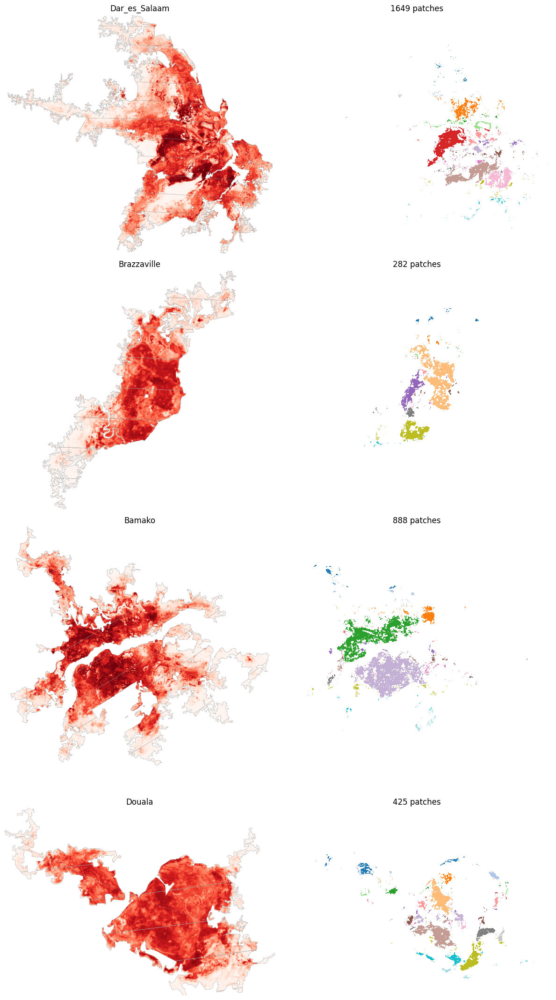

               n_patches  total_high_risk_area_km2  mean_patch_km2  median_patch_km2  largest_patch_km2  largest_patch_pct_share
city                                                                                                                            
Dar_es_Salaam       1649                   109.587           0.066             0.002             25.161                   22.960
Brazzaville          282                    30.350           0.108             0.002             15.985                   52.669
Bamako               888                    81.652           0.092             0.002             37.937                   46.462
Douala               425                    27.334           0.064             0.003              5.768                   21.102


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import label, sum as ndi_sum

CELL_SIZE_M = 30
CELL_AREA_KM2 = (CELL_SIZE_M / 1000) ** 2
THRESHOLD = 0.75
check_cities = ["Dar_es_Salaam", "Brazzaville", "Bamako", "Douala"]

def patch_analysis(city, threshold=THRESHOLD):
    print(f"  {city}:")
    df = predictions[city]
    grid = rasterize_native_grid(df)

    binary = np.where(np.isnan(grid), 0, grid > threshold).astype(int)
    labeled, n_patches = label(binary, structure=np.ones((3, 3)))
    if n_patches == 0:
        return None, grid, labeled

    patch_sizes_km2 = ndi_sum(binary, labeled, index=np.arange(1, n_patches + 1)) * CELL_AREA_KM2
    total_area = patch_sizes_km2.sum()
    stats = {
        "city": city, "n_patches": n_patches, "total_high_risk_area_km2": total_area,
        "mean_patch_km2": patch_sizes_km2.mean(), "median_patch_km2": np.median(patch_sizes_km2),
        "largest_patch_km2": patch_sizes_km2.max(),
        "largest_patch_pct_share": patch_sizes_km2.max() / total_area * 100,
    }
    return stats, grid, labeled

results = []
fig, axes = plt.subplots(len(check_cities), 2, figsize=(12, 5.5 * len(check_cities)))
for i, city in enumerate(check_cities):
    stats, grid, labeled = patch_analysis(city)
    if stats is None:
        print(f"{city}: no cells above threshold")
        continue
    results.append(stats)
    axes[i, 0].imshow(grid, cmap="Reds", vmin=0, vmax=1); axes[i, 0].set_title(city); axes[i, 0].axis("off")
    axes[i, 1].imshow(np.ma.masked_equal(labeled, 0), cmap="tab20", interpolation="none")
    axes[i, 1].set_title(f"{stats['n_patches']} patches"); axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

stats_df = pd.DataFrame(results).set_index("city")
print(stats_df.round(3).to_string())

In [ ]:
import os
PRED_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions"
predictions = {}
for f in os.listdir(PRED_DIR):
    city = f.replace("_predictions.csv", "")
    predictions[city] = pd.read_csv(os.path.join(PRED_DIR, f))
    print(f"{city}: {len(predictions[city]):,} cells loaded")

Abuja: 529,788 cells loaded
Addis_Ababa: 585,871 cells loaded
Antananarivo: 246,923 cells loaded
Bamako: 549,868 cells loaded
Bangui: 111,470 cells loaded
Bissau: 68,467 cells loaded
Brazzaville: 242,670 cells loaded
Cape_Town: 689,524 cells loaded
Conakry: 327,095 cells loaded
Cotonou: 389,593 cells loaded
Dar_es_Salaam: 1,172,840 cells loaded
Djibouti_City: 61,160 cells loaded
Douala: 252,827 cells loaded
Durban: 881,000 cells loaded
Gaborone: 166,188 cells loaded
Garoua: 47,602 cells loaded
Goma: 70,243 cells loaded
Ibadan: 657,101 cells loaded
Juba: 132,238 cells loaded
Kano: 314,301 cells loaded
Kigali: 986,524 cells loaded
Kumasi: 611,730 cells loaded
Libreville: 242,609 cells loaded
Lilongwe: 236,073 cells loaded
Lome: 382,538 cells loaded
Lubumbashi: 334,295 cells loaded
Lusaka: 682,609 cells loaded
Mombasa: 175,250 cells loaded
Monrovia: 250,144 cells loaded
Mwanza: 241,408 cells loaded
NDjamena: 224,067 cells loaded
Niamey: 192,967 cells loaded
Ouagadougou: 444,330 cells load

Processing Abuja...
Processing Addis_Ababa...
Processing Antananarivo...
Processing Bamako...
Processing Bangui...
Processing Bissau...
Processing Brazzaville...
Processing Cape_Town...
Processing Conakry...
Processing Cotonou...
Processing Dar_es_Salaam...
Processing Djibouti_City...
Processing Douala...
Processing Durban...
Processing Gaborone...
Processing Garoua...
Processing Goma...
Processing Ibadan...
Processing Juba...
Processing Kano...
Processing Kigali...
Processing Kumasi...
Processing Libreville...
Processing Lilongwe...
Processing Lome...
Processing Lubumbashi...
Processing Lusaka...
Processing Mombasa...
Processing Monrovia...
Processing Mwanza...
Processing NDjamena...
Processing Niamey...
Processing Ouagadougou...
Processing Tamale...
Processing Windhoek...
Processing Yaounde...

               moran_i_lag1  decay_range_m  converged
city                                                 
Garoua             0.959079          630.0       True
Cape_Town          0.955194   

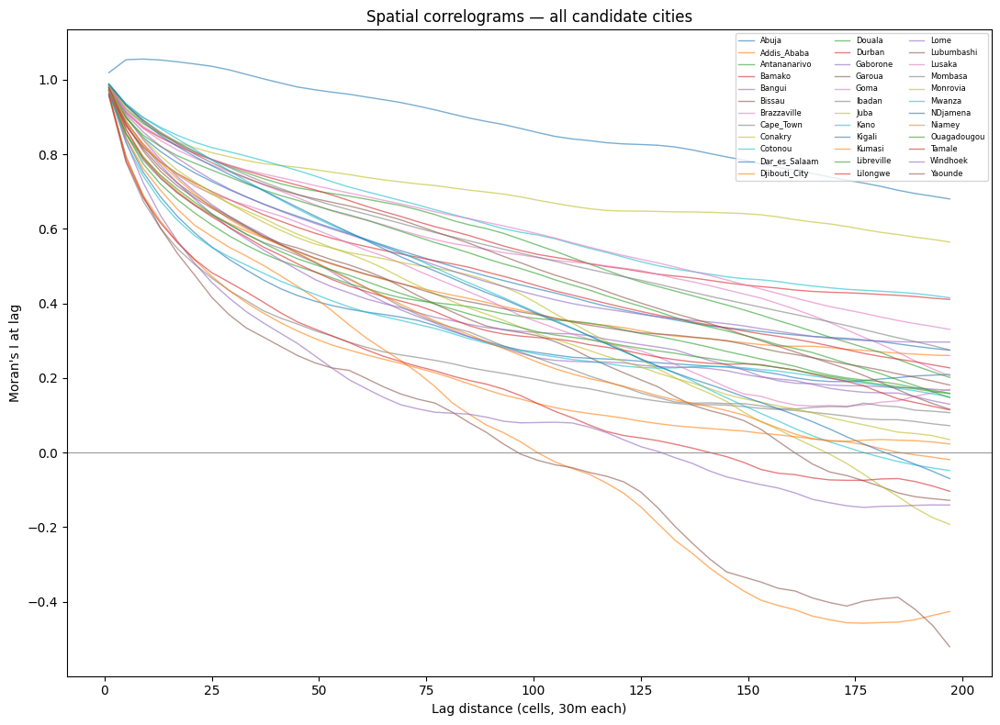

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MAX_LAG = 200
LAG_STEP = 4

def compute_decay_range(city, df, max_lag=MAX_LAG, lag_step=LAG_STEP):
    grid = rasterize_native_grid(df)
    lags = list(range(1, max_lag + 1, lag_step))
    moran_vals = np.array([morans_i_at_lag(grid, lag) for lag in lags])

    half_peak = moran_vals[0] / 2
    below_half = np.where(moran_vals < half_peak)[0]
    decay_lag = lags[below_half[0]] if len(below_half) > 0 else None
    decay_range_m = decay_lag * 30 if decay_lag else None

    return lags, moran_vals, decay_range_m

results = []
curves = {}

for city, df in predictions.items():
    try:
        print(f"Processing {city}...")
        lags, moran_vals, decay_range_m = compute_decay_range(city, df)
        curves[city] = (lags, moran_vals)
        results.append({
            "city": city,
            "moran_i_lag1": moran_vals[0],
            "decay_range_m": decay_range_m,
            "converged": decay_range_m is not None,
        })
    except Exception as e:
        print(f"  FAILED: {city} — {e}")

decay_df = pd.DataFrame(results).set_index("city").sort_values("decay_range_m")
pd.set_option("display.width", 160)
print("\n" + decay_df.to_string())

# ---- Plot all 36 correlograms together ----
fig, ax = plt.subplots(figsize=(11, 8))
for city, (lags, moran_vals) in curves.items():
    ax.plot(lags, moran_vals, linewidth=1, alpha=0.6, label=city)
ax.set_xlabel("Lag distance (cells, 30m each)")
ax.set_ylabel("Moran's I at lag")
ax.axhline(0, color="grey", linewidth=0.6)
ax.set_title("Spatial correlograms — all candidate cities")
ax.legend(fontsize=6, ncol=3, loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd

CELL_AREA_KM2 = (30 / 1000) ** 2

# ---- 1. Reload all 36 cities' predictions (in case session was restarted) ----
PRED_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions"
predictions = {}
for f in os.listdir(PRED_DIR):
    city = f.replace("_predictions.csv", "")
    predictions[city] = pd.read_csv(os.path.join(PRED_DIR, f))
print(f"Loaded {len(predictions)} cities.\n")

# ---- 2. Core functions (validated earlier in session) ----
def rasterize_native_grid(df, value_col="pred_proba", cell_size_m=30):
    lat = df["latitude"].to_numpy()
    lon = df["longitude"].to_numpy()
    lat_center = lat.mean()
    dlat_deg = cell_size_m / 111_320
    dlon_deg = cell_size_m / (111_320 * np.cos(np.radians(lat_center)))
    row_idx = np.floor((lat - lat.min()) / dlat_deg).astype(np.int64)
    col_idx = np.floor((lon - lon.min()) / dlon_deg).astype(np.int64)
    n_rows, n_cols = row_idx.max() + 1, col_idx.max() + 1
    if n_rows * n_cols > 50_000_000:
        raise MemoryError(f"Grid too large: {n_rows} x {n_cols}")
    grid = np.full((n_rows, n_cols), np.nan, dtype=np.float32)
    grid[row_idx, col_idx] = df[value_col].to_numpy()
    return np.flipud(grid)

def gini_coefficient(values):
    v = np.sort(values[~np.isnan(values)])
    n = len(v)
    if n == 0:
        return np.nan
    cum = np.cumsum(v)
    return (2 * np.sum((np.arange(1, n + 1)) * v) - (n + 1) * cum[-1]) / (n * cum[-1])

def getis_ord_general_g(grid):
    valid = ~np.isnan(grid)
    filled = np.where(valid, grid, 0.0)
    neighbor_sum = np.zeros_like(filled)
    shifts = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    for dr, dc in shifts:
        shifted_val = np.roll(np.roll(filled, dr, axis=0), dc, axis=1)
        shifted_valid = np.roll(np.roll(valid, dr, axis=0), dc, axis=1)
        if dr == -1: shifted_valid[-1, :] = False
        if dr == 1:  shifted_valid[0, :] = False
        if dc == -1: shifted_valid[:, -1] = False
        if dc == 1:  shifted_valid[:, 0] = False
        neighbor_sum += np.where(shifted_valid, shifted_val, 0.0)
    numerator = np.nansum(filled[valid] * neighbor_sum[valid])
    x = grid[valid]
    denominator = x.sum() ** 2 - (x ** 2).sum()
    return numerator / denominator if denominator != 0 else np.nan

def general_g_with_expectation(grid):
    valid = ~np.isnan(grid)
    n = valid.sum()
    g_stat = getis_ord_general_g(grid)
    expected_g = 1 / (n - 1)
    ratio = g_stat / expected_g if expected_g != 0 else np.nan
    return g_stat, expected_g, ratio

def effective_area_concentration(grid, cell_area_km2=CELL_AREA_KM2):
    valid = ~np.isnan(grid)
    p = grid[valid]
    total_area_km2 = valid.sum() * cell_area_km2
    sum_p, sum_p2 = p.sum(), (p ** 2).sum()
    if sum_p2 == 0:
        return np.nan, np.nan, total_area_km2
    a_eff_km2 = (sum_p ** 2) / sum_p2 * cell_area_km2
    C = 1 - (a_eff_km2 / total_area_km2)
    return a_eff_km2, C, total_area_km2

# ---- 3. Run across all 36 ----
results = []
for city, df in predictions.items():
    try:
        print(f"Processing {city}...")
        grid = rasterize_native_grid(df)
        gini = gini_coefficient(grid[~np.isnan(grid)])
        g_stat, expected_g, g_ratio = general_g_with_expectation(grid)
        a_eff, C, total_area = effective_area_concentration(grid)
        results.append({
            "city": city, "gini": gini, "general_g_ratio": g_ratio,
            "concentration_C": C, "total_area_km2": total_area,
            "effective_area_km2": a_eff,
        })
    except Exception as e:
        print(f"  FAILED: {city} — {e}")

final_df = pd.DataFrame(results).set_index("city").sort_values("concentration_C", ascending=False)
pd.set_option("display.width", 160)
print("\n" + final_df.round(4).to_string())

Loaded 36 cities.

Processing Abuja...
Processing Addis_Ababa...
Processing Antananarivo...
Processing Bamako...
Processing Bangui...
Processing Bissau...
Processing Brazzaville...
Processing Cape_Town...
Processing Conakry...
Processing Cotonou...
Processing Dar_es_Salaam...
Processing Djibouti_City...
Processing Douala...
Processing Durban...
Processing Gaborone...
Processing Garoua...
Processing Goma...
Processing Ibadan...
Processing Juba...
Processing Kano...
Processing Kigali...
Processing Kumasi...
Processing Libreville...
Processing Lilongwe...
Processing Lome...
Processing Lubumbashi...
Processing Lusaka...
Processing Mombasa...
Processing Monrovia...
Processing Mwanza...
Processing NDjamena...
Processing Niamey...
Processing Ouagadougou...
Processing Tamale...
Processing Windhoek...
Processing Yaounde...

                 gini  general_g_ratio  concentration_C  total_area_km2  effective_area_km2
city                                                                             

In [ ]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.features import shapes as rio_shapes
from shapely.geometry import shape as shapely_shape
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

PRED_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions"
GRID_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities"
CELL_AREA_KM2 = (30 / 1000) ** 2

# =====================================================================
# 1. Load all 36 predictions from disk
# =====================================================================
predictions = {}
for f in os.listdir(PRED_DIR):
    city = f.replace("_predictions.csv", "")
    predictions[city] = pd.read_csv(os.path.join(PRED_DIR, f))
print(f"Loaded {len(predictions)} cities.")

# =====================================================================
# 2. Concentration metrics (Gini, General G ratio, effective-area C)
# =====================================================================
def rasterize_native_grid(df, value_col="pred_proba", cell_size_m=30):
    lat = df["latitude"].to_numpy()
    lon = df["longitude"].to_numpy()
    lat_center = lat.mean()
    dlat_deg = cell_size_m / 111_320
    dlon_deg = cell_size_m / (111_320 * np.cos(np.radians(lat_center)))
    row_idx = np.floor((lat - lat.min()) / dlat_deg).astype(np.int64)
    col_idx = np.floor((lon - lon.min()) / dlon_deg).astype(np.int64)
    n_rows, n_cols = row_idx.max() + 1, col_idx.max() + 1
    if n_rows * n_cols > 50_000_000:
        raise MemoryError(f"Grid too large: {n_rows} x {n_cols}")
    grid = np.full((n_rows, n_cols), np.nan, dtype=np.float32)
    grid[row_idx, col_idx] = df[value_col].to_numpy()
    return np.flipud(grid)

def gini_coefficient(values):
    v = np.sort(values[~np.isnan(values)])
    n = len(v)
    if n == 0: return np.nan
    cum = np.cumsum(v)
    return (2 * np.sum(np.arange(1, n + 1) * v) - (n + 1) * cum[-1]) / (n * cum[-1])

def getis_ord_general_g(grid):
    valid = ~np.isnan(grid)
    filled = np.where(valid, grid, 0.0)
    neighbor_sum = np.zeros_like(filled)
    shifts = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]
    for dr, dc in shifts:
        sv = np.roll(np.roll(filled, dr, axis=0), dc, axis=1)
        svalid = np.roll(np.roll(valid, dr, axis=0), dc, axis=1)
        if dr == -1: svalid[-1, :] = False
        if dr == 1:  svalid[0, :] = False
        if dc == -1: svalid[:, -1] = False
        if dc == 1:  svalid[:, 0] = False
        neighbor_sum += np.where(svalid, sv, 0.0)
    numerator = np.nansum(filled[valid] * neighbor_sum[valid])
    x = grid[valid]
    denom = x.sum() ** 2 - (x ** 2).sum()
    return numerator / denom if denom != 0 else np.nan

def general_g_ratio(grid):
    valid = ~np.isnan(grid)
    n = valid.sum()
    g = getis_ord_general_g(grid)
    expected = 1 / (n - 1)
    return g / expected if expected != 0 else np.nan

def effective_area_concentration(grid, cell_area_km2=CELL_AREA_KM2):
    valid = ~np.isnan(grid)
    p = grid[valid]
    total_area = valid.sum() * cell_area_km2
    sum_p, sum_p2 = p.sum(), (p ** 2).sum()
    if sum_p2 == 0: return np.nan, np.nan
    a_eff = (sum_p ** 2) / sum_p2 * cell_area_km2
    C = 1 - (a_eff / total_area)
    return a_eff, C

concentration_rows = []
for city, df in predictions.items():
    try:
        grid = rasterize_native_grid(df)
        gini = gini_coefficient(grid[~np.isnan(grid)])
        g_ratio = general_g_ratio(grid)
        a_eff, C = effective_area_concentration(grid)
        p = df["pred_proba"].to_numpy()
        concentration_rows.append({
            "city": city, "gini": gini, "general_g_ratio": g_ratio, "concentration_C": C,
            "mean_pred_proba": p.mean(), "pct_area_above_0.75": 100 * np.mean(p > 0.75),
        })
        print(f"{city}: done")
    except Exception as e:
        print(f"{city}: FAILED — {e}")

concentration_df = pd.DataFrame(concentration_rows).set_index("city")
print(f"\nConcentration metrics computed for {len(concentration_df)} cities.")

Loaded 36 cities.
Abuja: done
Addis_Ababa: done
Antananarivo: done
Bamako: done
Bangui: done
Bissau: done
Brazzaville: done
Cape_Town: done
Conakry: done
Cotonou: done
Dar_es_Salaam: done
Djibouti_City: done
Douala: done
Durban: done
Gaborone: done
Garoua: done
Goma: done
Ibadan: done
Juba: done
Kano: done
Kigali: done
Kumasi: done
Libreville: done
Lilongwe: done
Lome: done
Lubumbashi: done
Lusaka: done
Mombasa: done
Monrovia: done
Mwanza: done
NDjamena: done
Niamey: done
Ouagadougou: done
Tamale: done
Windhoek: done
Yaounde: done

Concentration metrics computed for 36 cities.


In [ ]:
# =====================================================================
# 3. Population exposure (34 of 36 cities — Cape Town, Djibouti City excluded,
#    per the earlier finding that their source boundary tif is unavailable)
# =====================================================================

city_country_map = {
    "Abuja": "Nigeria", "Ibadan": "Nigeria", "Kano": "Nigeria",
    "Antananarivo": "Madagascar", "Bamako": "Mali",
    "Bangui": "Central_African_Republic", "Bissau": "Guinea_Bissau",
    "Brazzaville": "Rep_of_Congo", "Durban": "South_Africa",
    "Conakry": "Guinea", "Cotonou": "Benin",
    "Dar_es_Salaam": "Tanzania", "Mwanza": "Tanzania",
    "Douala": "Cameroon", "Garoua": "Cameroon", "Yaounde": "Cameroon",
    "Gaborone": "Botswana", "Goma": "Democratic_Rep_Congo", "Lubumbashi": "Democratic_Rep_Congo",
    "Juba": "South_Sudan", "Kigali": "Rwanda", "Kumasi": "Ghana", "Tamale": "Ghana",
    "Libreville": "Gabon", "Lilongwe": "Malawi", "Lome": "Togo", "Mombasa": "Kenya",
    "Monrovia": "Liberia", "NDjamena": "Chad", "Niamey": "Niger", "Ouagadougou": "Burkina_Faso",
    "Windhoek": "Namibia",
}
city_level_raster_overrides = {
    "Addis_Ababa": f"{GRID_DIR}/Addis_Ababa/eth_pop_2024_CN_100m_R2025A_v1.tif",
    "Lusaka": f"{GRID_DIR}/Lusaka/zmb_pop_2024_CN_100m_R2025A_v1.tif",
}
slum_tif_overrides = {
    "Lome": f"{GRID_DIR}/Lome/TGO_Lome_Aflao_TGO_2022.tif",
    "NDjamena": f"{GRID_DIR}/NDjamena/TCD_Ndjamena_Kousseri_TCD_2022.tif",
}
iso3_map = {
    "Nigeria": "NGA", "Madagascar": "MDG", "Mali": "MLI",
    "Central_African_Republic": "CAF", "Guinea_Bissau": "GNB", "Rep_of_Congo": "COG",
    "South_Africa": "ZAF", "Guinea": "GIN", "Benin": "BEN", "Tanzania": "TZA",
    "Cameroon": "CMR", "Botswana": "BWA", "Democratic_Rep_Congo": "COD",
    "South_Sudan": "SSD", "Rwanda": "RWA", "Ghana": "GHA", "Gabon": "GAB",
    "Malawi": "MWI", "Togo": "TGO", "Kenya": "KEN", "Liberia": "LBR", "Chad": "TCD",
    "Niger": "NER", "Burkina_Faso": "BFA", "Namibia": "NAM",
    "Ethiopia": "ETH", "Zambia": "ZMB",
}

def resolve_pop_raster_path(city):
    if city in city_level_raster_overrides:
        return city_level_raster_overrides[city]
    country = city_country_map[city]
    exceptions = {"Burkina_Faso": "burkinafaso", "Rep_of_Congo": "rep_of_cog"}
    stem = exceptions.get(country, country.lower())
    return f"{GRID_DIR}/Countries/{country}/{stem}_pop_2024_CN_100m_R2025A_v1.tif"

def resolve_slum_tif_path(city):
    if city in slum_tif_overrides:
        return slum_tif_overrides[city]
    country = city_country_map.get(city) or {"Addis_Ababa": "Ethiopia", "Lusaka": "Zambia"}[city]
    iso3 = iso3_map[country]
    return f"{GRID_DIR}/{city}/{iso3}_{city}_2022.tif"

def derive_boundary(slum_path):
    with rasterio.open(slum_path) as src:
        band = src.read(1)
        valid_mask = (band != src.nodata) if src.nodata is not None else ~np.isnan(band)
        shapes_gen = rio_shapes(valid_mask.astype(np.uint8), mask=valid_mask, transform=src.transform)
        polys = [shapely_shape(geom) for geom, val in shapes_gen if val == 1]
        boundary = gpd.GeoDataFrame(geometry=[gpd.GeoSeries(polys, crs=src.crs).union_all()], crs=src.crs)
    return boundary

def process_city_population(city, pred_df):
    boundary = derive_boundary(resolve_slum_tif_path(city))
    pop_path = resolve_pop_raster_path(city)
    with rasterio.open(pop_path) as src:
        poly = boundary.to_crs(src.crs)
        clipped, transform = rio_mask(src, poly.geometry, crop=True, nodata=src.nodata)
        nodata, raster_crs = src.nodata, src.crs

    band = clipped[0]
    rows, cols = np.where((band != nodata) & (~np.isnan(band)) & (band > 0))
    pop_values = band[rows, cols]
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    pop_gdf = gpd.GeoDataFrame({"pop": pop_values}, geometry=gpd.points_from_xy(xs, ys),
                                crs=raster_crs).to_crs("EPSG:4326")

    utm_crs = boundary.estimate_utm_crs()
    pop_utm = pop_gdf.to_crs(utm_crs)
    pred_gdf = gpd.GeoDataFrame(pred_df, geometry=gpd.points_from_xy(pred_df.longitude, pred_df.latitude),
                                 crs="EPSG:4326").to_crs(utm_crs)

    tree = cKDTree(np.column_stack([pred_gdf.geometry.x, pred_gdf.geometry.y]))
    _, idx = tree.query(np.column_stack([pop_utm.geometry.x, pop_utm.geometry.y]), k=1)
    nearest_proba = pred_gdf["pred_proba"].values[idx]

    total_pop = pop_values.sum()
    pct_above_75 = 100 * pop_values[nearest_proba > 0.75].sum() / total_pop if total_pop > 0 else np.nan
    return {"city": city, "total_population": total_pop, "pct_pop_above_0.75": pct_above_75}

pop_exposure_cities = [c for c in predictions if c not in ("Cape_Town", "Djibouti_City")]
pop_rows = []
for city in pop_exposure_cities:
    try:
        pop_rows.append(process_city_population(city, predictions[city]))
        print(f"{city}: done")
    except Exception as e:
        print(f"{city}: FAILED — {e}")

pop_df = pd.DataFrame(pop_rows).set_index("city")

Abuja: done
Addis_Ababa: done
Antananarivo: done
Bamako: done
Bangui: done
Bissau: done
Brazzaville: done
Conakry: done
Cotonou: done
Dar_es_Salaam: done
Douala: done
Durban: done
Gaborone: done
Garoua: done
Goma: done
Ibadan: done
Juba: done
Kano: done
Kigali: done
Kumasi: done
Libreville: done
Lilongwe: done
Lome: done
Lubumbashi: done
Lusaka: done
Mombasa: done
Monrovia: done
Mwanza: done
NDjamena: done
Niamey: done
Ouagadougou: done
Tamale: done
Windhoek: done
Yaounde: done


Cities in typology table: 34

Feature correlation matrix:

                          mean_risk  high_risk_area_pct  concentration  high_risk_population_pct
mean_risk                     1.000               0.778         -0.684                     0.702
high_risk_area_pct            0.778               1.000         -0.170                     0.952
concentration                -0.684              -0.170          1.000                    -0.099
high_risk_population_pct      0.702               0.952         -0.099                     1.000

Silhouette scores and cluster sizes:
k=2: silhouette=0.460, sizes=[24, 10]
k=3: silhouette=0.455, sizes=[23, 10, 1]
k=4: silhouette=0.305, sizes=[16, 10, 1, 7]
k=5: silhouette=0.329, sizes=[10, 10, 1, 7, 6]
k=6: silhouette=0.338, sizes=[8, 10, 2, 7, 6, 1]

Selected k = 2 (features: ['mean_risk', 'high_risk_area_pct', 'concentration', 'high_risk_population_pct'])
Ward vs. average linkage agreement at k=2: 67.6%

Cluster profiles:

        mean_risk    

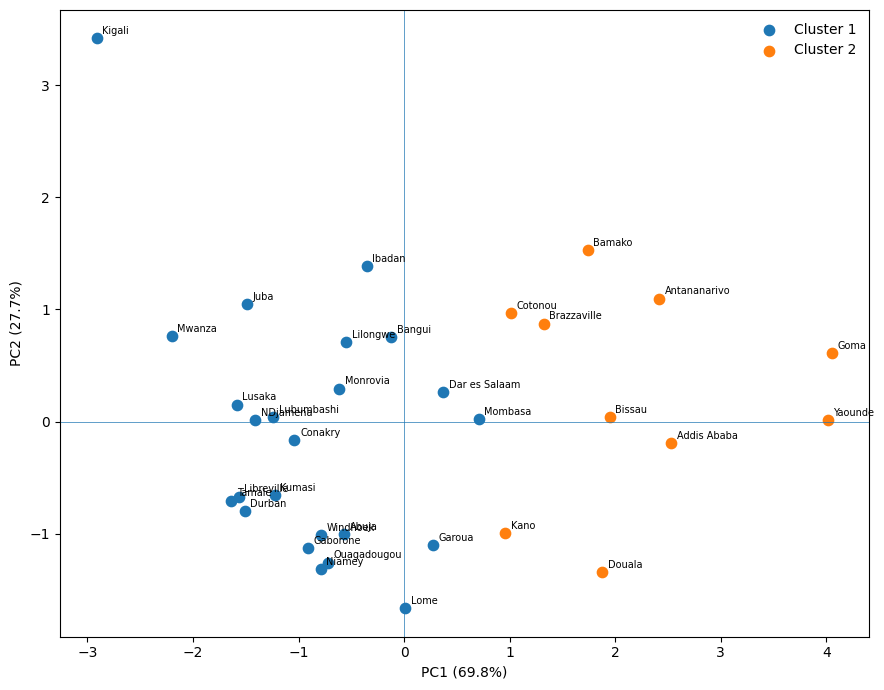

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# ---- Build city-level feature table ----
typology = concentration_df[["concentration_C", "mean_pred_proba", "pct_area_above_0.75"]].join(
    pop_df[["pct_pop_above_0.75"]], how="inner"
)
typology.columns = ["concentration", "mean_risk", "high_risk_area_pct", "high_risk_population_pct"]
typology = typology.dropna()
print(f"Cities in typology table: {len(typology)}")

# ---- Check redundancy before clustering ----
features = ["mean_risk", "high_risk_area_pct", "concentration", "high_risk_population_pct"]
print("\nFeature correlation matrix:\n")
print(typology[features].corr().round(3).to_string())

corr_conc_area = typology["high_risk_area_pct"].corr(typology["concentration"])
if corr_conc_area > 0.95:
    print(f"\nDropping 'high_risk_area_pct' (r={corr_conc_area:.3f} with concentration — near-redundant)")
    features = ["mean_risk", "concentration", "high_risk_population_pct"]

X = StandardScaler().fit_transform(typology[features])

# ---- Determine supported k, with cluster-size sanity check ----
scores, cluster_sizes = {}, {}
for k in range(2, 7):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    scores[k] = silhouette_score(X, labels)
    cluster_sizes[k] = pd.Series(labels).value_counts().sort_index().tolist()

print("\nSilhouette scores and cluster sizes:")
for k, v in scores.items():
    print(f"k={k}: silhouette={v:.3f}, sizes={cluster_sizes[k]}")

valid_k = {k: v for k, v in scores.items() if min(cluster_sizes[k]) >= 3}
if not valid_k:
    print("\nNo k gives all clusters >=3 — likely isolating outliers. Using best overall k, flagged as fragile.")
    best_k = max(scores, key=scores.get)
else:
    best_k = max(valid_k, key=valid_k.get)
print(f"\nSelected k = {best_k} (features: {features})")

model = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
typology["cluster"] = model.fit_predict(X) + 1

alt_labels = AgglomerativeClustering(n_clusters=best_k, linkage="average").fit_predict(X) + 1
agreement = (typology["cluster"].to_numpy() == alt_labels).mean()
print(f"Ward vs. average linkage agreement at k={best_k}: {agreement*100:.1f}%")

cluster_profiles = typology.groupby("cluster")[features].agg(["mean", "median", "count"])
print("\nCluster profiles:\n")
print(cluster_profiles.round(3).to_string())
print("\nCities:\n")
print(typology.sort_values(["cluster", "mean_risk"], ascending=[True, False]).round(3).to_string())

# ---- PCA for visualisation only ----
pca = PCA(n_components=2)
coords = pca.fit_transform(X)
typology["PC1"], typology["PC2"] = coords[:, 0], coords[:, 1]
print(f"\nPCA variance explained: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, "
      f"PC2={pca.explained_variance_ratio_[1]*100:.1f}%")

fig, ax = plt.subplots(figsize=(9, 7))
for c in sorted(typology.cluster.unique()):
    d = typology[typology.cluster == c]
    ax.scatter(d.PC1, d.PC2, s=55, label=f"Cluster {c}")
for city, r in typology.iterrows():
    ax.annotate(city.replace("_", " "), (r.PC1, r.PC2), xytext=(4, 3), textcoords="offset points", fontsize=7)
ax.axhline(0, lw=.5); ax.axvline(0, lw=.5)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Processing Abuja...
Processing Addis_Ababa...
Processing Antananarivo...
Processing Bamako...
Processing Bangui...
Processing Bissau...
Processing Brazzaville...
Processing Cape_Town...
Processing Conakry...
Processing Cotonou...
Processing Dar_es_Salaam...
Processing Djibouti_City...
Processing Douala...
Processing Durban...
Processing Gaborone...
Processing Garoua...
Processing Goma...
Processing Ibadan...
Processing Juba...
Processing Kano...
Processing Kigali...
Processing Kumasi...
Processing Libreville...
Processing Lilongwe...
Processing Lome...
Processing Lubumbashi...
Processing Lusaka...
Processing Mombasa...
Processing Monrovia...
Processing Mwanza...
Processing NDjamena...
Processing Niamey...
Processing Ouagadougou...
Processing Tamale...
Processing Windhoek...
Processing Yaounde...

Cross-city summary:

         spatial_persistence               high_risk_enrichment              
                        mean median    std                 mean median    std
radius_m       

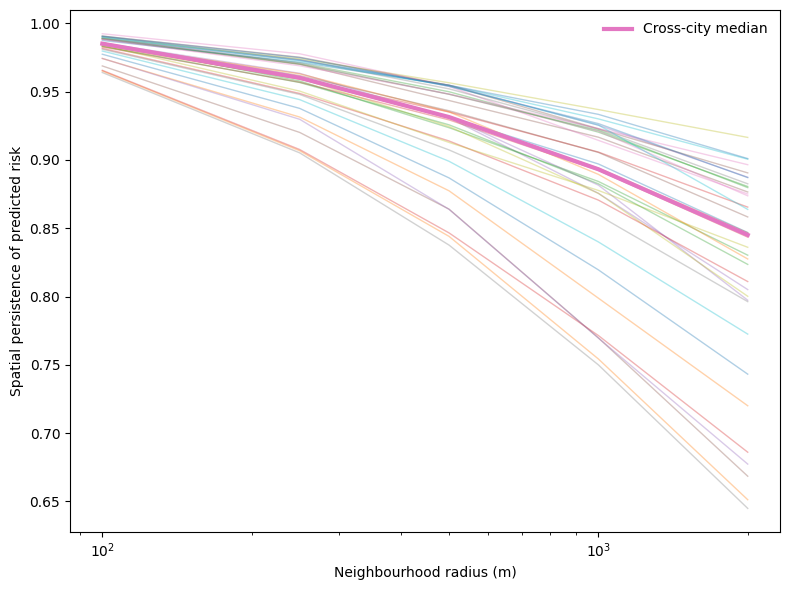

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

RADII = [100, 250, 500, 1000, 2000]
N_SAMPLE = 20000
RANDOM_STATE = 42

def multiscale_spatial_persistence(df, radii=RADII, n_sample=N_SAMPLE):
    gdf = gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")
    gdf = gdf.to_crs(gdf.estimate_utm_crs())
    xy = np.column_stack([gdf.geometry.x, gdf.geometry.y])
    p = gdf["pred_proba"].to_numpy()
    tree = cKDTree(xy)

    rng = np.random.default_rng(RANDOM_STATE)
    idx = rng.choice(len(df), min(n_sample, len(df)), replace=False)

    rows = []
    for radius in radii:
        neighbourhoods = tree.query_ball_point(xy[idx], r=radius, workers=-1)
        # exclude self (the sampled point itself) from its own neighbourhood mean
        local_mean = np.array([
            (p[n].sum() - p[idx[i]]) / (len(n) - 1) if len(n) > 1 else np.nan
            for i, n in enumerate(neighbourhoods)
        ])

        valid = np.isfinite(local_mean)
        corr = np.corrcoef(p[idx][valid], local_mean[valid])[0, 1]
        high = p[idx] >= 0.75
        high_local_mean = np.nanmean(local_mean[high])
        all_local_mean = np.nanmean(local_mean)
        rows.append({
            "radius_m": radius, "spatial_persistence": corr,
            "high_risk_neighbourhood_mean": high_local_mean,
            "overall_neighbourhood_mean": all_local_mean,
            "high_risk_enrichment": high_local_mean / all_local_mean,
        })
    return pd.DataFrame(rows)

multi = []
for city, df in predictions.items():
    print(f"Processing {city}...")
    try:
        out = multiscale_spatial_persistence(df)
        out["city"] = city
        multi.append(out)
    except Exception as e:
        print(f"FAILED {city}: {e}")

multiscale_df = pd.concat(multi, ignore_index=True)
print("\nCross-city summary:\n")
print(multiscale_df.groupby("radius_m")[["spatial_persistence", "high_risk_enrichment"]]
      .agg(["mean", "median", "std"]).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
for city, d in multiscale_df.groupby("city"):
    ax.plot(d.radius_m, d.spatial_persistence, alpha=.35, lw=1)
median_curve = multiscale_df.groupby("radius_m").spatial_persistence.median()
ax.plot(median_curve.index, median_curve.values, lw=3, label="Cross-city median")
ax.set_xscale("log")
ax.set_xlabel("Neighbourhood radius (m)")
ax.set_ylabel("Spatial persistence of predicted risk")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# ---- Build directly from concentration_df and pop_df (no stale variable names) ----
exposure = concentration_df[["concentration_C", "mean_pred_proba", "pct_area_above_0.75"]].join(
    pop_df[["pct_pop_above_0.75", "total_population"]], how="inner"
).dropna()
exposure.columns = ["concentration", "mean_risk", "high_risk_area_pct", "high_risk_population_pct", "total_population"]

# ---- Check collinearity BEFORE fitting ----
print("Correlations among candidate predictors:\n")
print(exposure[["mean_risk", "high_risk_area_pct", "concentration"]].corr().round(3).to_string())

corr_area_conc = exposure["high_risk_area_pct"].corr(exposure["concentration"])
if abs(corr_area_conc) > 0.9:
    print(f"\nr={corr_area_conc:.3f} between high_risk_area_pct and concentration — dropping "
          f"'high_risk_area_pct' to avoid multicollinearity.")
    predictors = ["mean_risk", "concentration"]
else:
    predictors = ["mean_risk", "high_risk_area_pct", "concentration"]

print(f"\nn = {len(exposure)} cities, predictors used: {predictors}")

# ---- Standardised regression ----
X = pd.DataFrame(StandardScaler().fit_transform(exposure[predictors]), columns=predictors, index=exposure.index)
y = (exposure["high_risk_population_pct"] - exposure["high_risk_population_pct"].mean()) / exposure["high_risk_population_pct"].std()

model = sm.OLS(y, sm.add_constant(X)).fit(cov_type="HC3")
print(model.summary())

# ---- Bootstrap coefficients ----
rng = np.random.default_rng(42)
B = 5000
coefs = {p: [] for p in predictors}
for b in range(B):
    idx = rng.choice(len(exposure), len(exposure), replace=True)
    xb = X.iloc[idx].reset_index(drop=True)
    yb = y.iloc[idx].reset_index(drop=True)
    try:
        m = sm.OLS(yb, sm.add_constant(xb)).fit()
        for p in predictors:
            coefs[p].append(m.params[p])
    except Exception:
        pass

print(f"\nBootstrap standardised effects (n={len(exposure)} cities, {B} resamples):")
for p, v in coefs.items():
    v = np.asarray(v)
    print(f"{p:20s} beta={np.mean(v):+.3f}, 95% CI [{np.percentile(v,2.5):+.3f}, {np.percentile(v,97.5):+.3f}]")

Correlations among candidate predictors:

                    mean_risk  high_risk_area_pct  concentration
mean_risk               1.000               0.778         -0.684
high_risk_area_pct      0.778               1.000         -0.170
concentration          -0.684              -0.170          1.000

n = 34 cities, predictors used: ['mean_risk', 'high_risk_area_pct', 'concentration']
                               OLS Regression Results                               
Dep. Variable:     high_risk_population_pct   R-squared:                       0.910
Model:                                  OLS   Adj. R-squared:                  0.902
Method:                       Least Squares   F-statistic:                     103.4
Date:                      Wed, 16 Sep 2026   Prob (F-statistic):           6.48e-16
Time:                              12:06:22   Log-Likelihood:                -6.7111
No. Observations:                        34   AIC:                             21.42
Df Residuals:    

  Dar_es_Salaam:
  Brazzaville:
  Bamako:
  Douala:


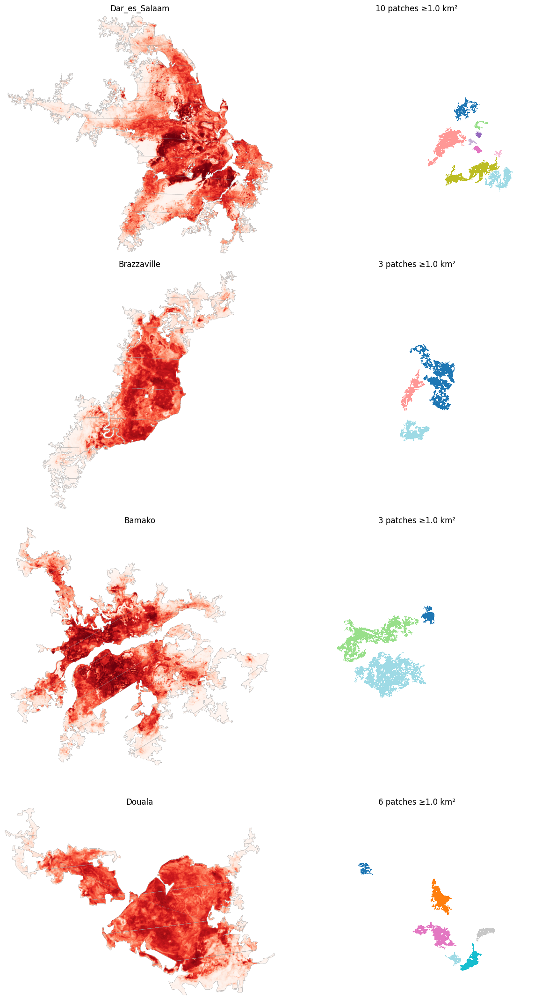

               n_raw_patches  n_meaningful_patches  total_high_risk_area_km2  meaningful_area_km2  pct_area_in_meaningful_patches  median_meaningful_patch_km2  largest_patch_km2
city                                                                                                                                                                             
Dar_es_Salaam           1649                    10                   109.587               82.330                          75.128                        2.168             25.161
Brazzaville              282                     3                    30.350               26.070                          85.899                        5.420             15.985
Bamako                   888                     3                    81.652               69.080                          84.603                       27.784             37.937
Douala                   425                     6                    27.334               16.747             

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import label, sum as ndi_sum

CELL_SIZE_M = 30
CELL_AREA_KM2 = (CELL_SIZE_M / 1000) ** 2
THRESHOLD = 0.75
MIN_PATCH_KM2 = 1.0  # meaningful-size cutoff
check_cities = ["Dar_es_Salaam", "Brazzaville", "Bamako", "Douala"]

def patch_analysis(city, threshold=THRESHOLD, min_patch_km2=MIN_PATCH_KM2):
    print(f"  {city}:")
    df = predictions[city]
    grid = rasterize_native_grid(df)

    binary = np.where(np.isnan(grid), 0, grid > threshold).astype(int)
    labeled, n_raw = label(binary, structure=np.ones((3, 3)))
    if n_raw == 0:
        return None, grid, labeled

    patch_sizes_km2 = ndi_sum(binary, labeled, index=np.arange(1, n_raw + 1)) * CELL_AREA_KM2

    # identify meaningful patches (>= min_patch_km2) and build a display raster keeping only those
    meaningful_ids = np.where(patch_sizes_km2 >= min_patch_km2)[0] + 1  # patch labels are 1-indexed
    meaningful_mask = np.isin(labeled, meaningful_ids)
    labeled_meaningful = np.where(meaningful_mask, labeled, 0)

    meaningful_sizes_km2 = patch_sizes_km2[patch_sizes_km2 >= min_patch_km2]
    total_area_all = patch_sizes_km2.sum()
    total_area_meaningful = meaningful_sizes_km2.sum()

    stats = {
        "city": city,
        "n_raw_patches": n_raw,
        "n_meaningful_patches": len(meaningful_sizes_km2),
        "total_high_risk_area_km2": total_area_all,
        "meaningful_area_km2": total_area_meaningful,
        "pct_area_in_meaningful_patches": 100 * total_area_meaningful / total_area_all if total_area_all > 0 else np.nan,
        "median_meaningful_patch_km2": np.median(meaningful_sizes_km2) if len(meaningful_sizes_km2) else np.nan,
        "largest_patch_km2": patch_sizes_km2.max(),
    }
    return stats, grid, labeled_meaningful

results = []
fig, axes = plt.subplots(len(check_cities), 2, figsize=(12, 5.5 * len(check_cities)))
for i, city in enumerate(check_cities):
    stats, grid, labeled_meaningful = patch_analysis(city)
    if stats is None:
        print(f"{city}: no cells above threshold")
        continue
    results.append(stats)
    axes[i, 0].imshow(grid, cmap="Reds", vmin=0, vmax=1); axes[i, 0].set_title(city); axes[i, 0].axis("off")
    axes[i, 1].imshow(np.ma.masked_equal(labeled_meaningful, 0), cmap="tab20", interpolation="none")
    axes[i, 1].set_title(f"{stats['n_meaningful_patches']} patches ≥{MIN_PATCH_KM2} km²"); axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

stats_df = pd.DataFrame(results).set_index("city")
print(stats_df.round(3).to_string())

In [ ]:
import os
import json
import numpy as np
import pandas as pd
import xgboost as xgb
import time

N_BOOT = 100
SEED = 42
ROWS_PER_CITY_CAP = 75_000  # stratified cap per drawn city instance
N_ESTIMATORS_BOOT = 100     # reduced from tuned value, applied consistently across all iterations

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]
top5_predictors = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]

MODEL_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction"
JOHANNESBURG_V1_PATH = "/content/drive/MyDrive/Paper_3/Miscellaneous/johannesburg_grid30m_combined_v1_covariates.csv"
PRED_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions"

# ---- 1. Load candidate predictions ----
predictions = {}
for f in os.listdir(PRED_DIR):
    city = f.replace("_predictions.csv", "")
    predictions[city] = pd.read_csv(os.path.join(PRED_DIR, f))
print(f"Loaded {len(predictions)} candidate cities.")

# ---- 2. Rebuild the 10-city training data ----
def build_city_stacked(city):
    c = city.lower()
    if city == "Johannesburg":
        df = pd.read_csv(JOHANNESBURG_V1_PATH)
        dv16, dv24 = "DV_2016", "DV_2024"
    else:
        combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
        df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")
        dv16, dv24 = "DV_2016_revised", "DV_2024_revised"

    def year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in top5_predictors}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["DV"] = df[dv_col]
        sub["city"] = city
        return sub

    stacked = pd.concat([year_slice(df, 2016, dv16), year_slice(df, 2024, dv24)], ignore_index=True)
    stacked["target"] = (stacked["DV"] > 0).astype(int)
    return stacked

print("Building per-city stacked training datasets...")
city_data = {city: build_city_stacked(city) for city in cities}
for city, d in city_data.items():
    print(f"  {city}: {len(d):,} rows")

# ---- 3. Load tuned hyperparameters, override n_estimators for speed ----
with open(f"{MODEL_DIR}/full10city_top5_params.json") as f:
    final_params = json.load(f)
final_params["n_estimators"] = N_ESTIMATORS_BOOT
print(f"\nParams for bootstrap (n_estimators overridden to {N_ESTIMATORS_BOOT}): {final_params}")

# ---- 4. Bootstrap loop with stratified per-city row cap ----
rng = np.random.default_rng(SEED)
uncertainty = {city: [] for city in predictions}

start_time = time.time()
for b in range(N_BOOT):
    iter_start = time.time()
    sampled_cities = rng.choice(cities, len(cities), replace=True)

    parts = []
    for j, city in enumerate(sampled_cities):
        d = city_data[city]
        if len(d) > ROWS_PER_CITY_CAP:
            d = d.sample(ROWS_PER_CITY_CAP, random_state=int(rng.integers(0, 1_000_000)))
        d = d.copy()
        d["_bootstrap_city"] = f"{city}_{j}"
        parts.append(d)
    boot = pd.concat(parts, ignore_index=True)

    spw = (boot["target"] == 0).sum() / (boot["target"] == 1).sum()
    params_b = final_params.copy()
    params_b.update({"scale_pos_weight": spw, "random_state": 42, "eval_metric": "logloss",
                      "tree_method": "hist", "n_jobs": -1})

    model_b = xgb.XGBClassifier(**params_b)
    model_b.fit(boot[top5_predictors], boot["target"])

    for city, df in predictions.items():
        p = model_b.predict_proba(df[top5_predictors])[:, 1]
        uncertainty[city].append({
            "mean_probability": p.mean(),
            "pct_above_0.5": 100 * np.mean(p > 0.5),
            "pct_above_0.75": 100 * np.mean(p > 0.75),
            "pct_above_0.9": 100 * np.mean(p > 0.9),
        })

    iter_time = time.time() - iter_start
    elapsed = time.time() - start_time
    print(f"Bootstrap {b+1}/{N_BOOT} done in {iter_time:.1f}s (n_train={len(boot):,}, "
          f"unique cities={len(set(sampled_cities))}) — elapsed {elapsed/60:.1f} min")

print(f"\nTotal time: {(time.time()-start_time)/60:.1f} minutes")

# ---- 5. Summarise ----
rows = []
for city, runs in uncertainty.items():
    d = pd.DataFrame(runs)
    row = {"city": city}
    for metric in d.columns:
        row[f"{metric}_median"] = d[metric].median()
        row[f"{metric}_lo"] = d[metric].quantile(.025)
        row[f"{metric}_hi"] = d[metric].quantile(.975)
    rows.append(row)

uncertainty_df = pd.DataFrame(rows).set_index("city")
pd.set_option("display.width", 200)
print(uncertainty_df.round(3).to_string())

Loaded 36 candidate cities.
Building per-city stacked training datasets...
  Abidjan: 288,052 rows
  Accra: 1,228,316 rows
  Dakar: 415,696 rows
  Freetown: 268,174 rows
  Johannesburg: 8,570,726 rows
  Kampala: 751,748 rows
  Kinshasa: 587,742 rows
  Lagos: 2,487,444 rows
  Maputo: 638,096 rows
  Nairobi: 392,290 rows

Params for bootstrap (n_estimators overridden to 100): {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.2807676414162096, 'subsample': 0.5057173020727357, 'colsample_bytree': 0.7037839931895831, 'min_child_weight': 4, 'scale_pos_weight': 4.818175151494905, 'random_state': 42, 'eval_metric': 'logloss', 'tree_method': 'hist', 'n_jobs': -1}
Bootstrap 1/100 done in 7.9s (n_train=750,000, unique cities=6) — elapsed 0.1 min
Bootstrap 2/100 done in 6.6s (n_train=750,000, unique cities=8) — elapsed 0.2 min
Bootstrap 3/100 done in 8.3s (n_train=750,000, unique cities=8) — elapsed 0.4 min
Bootstrap 4/100 done in 7.1s (n_train=750,000, unique cities=5) — elapsed 0.5 min
Bo

In [ ]:
import os
import json
import numpy as np
import pandas as pd
import xgboost as xgb

N_BOOT = 100
SEED = 42

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]
top5_predictors = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]

MODEL_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction"
JOHANNESBURG_V1_PATH = "/content/drive/MyDrive/Paper_3/Miscellaneous/johannesburg_grid30m_combined_v1_covariates.csv"
PRED_DIR = "/content/drive/MyDrive/Paper_3/Data/Test_cities/Predictions"

# ---- 1. Load candidate predictions (only need lon/lat + predictors, not the old pred_proba) ----
predictions = {}
for f in os.listdir(PRED_DIR):
    city = f.replace("_predictions.csv", "")
    predictions[city] = pd.read_csv(os.path.join(PRED_DIR, f))
print(f"Loaded {len(predictions)} candidate cities.")

# ---- 2. Rebuild the 10-city training data (same structure as the original training/LOCO script) ----
def build_city_stacked(city):
    c = city.lower()
    if city == "Johannesburg":
        df = pd.read_csv(JOHANNESBURG_V1_PATH)
    else:
        combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
        df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")

    def year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in top5_predictors}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["DV"] = df[dv_col]
        sub["city"] = city
        return sub

    stacked = pd.concat([year_slice(df, 2016, "DV_2016_revised" if city != "Johannesburg" else "DV_2016"),
                          year_slice(df, 2024, "DV_2024_revised" if city != "Johannesburg" else "DV_2024")],
                         ignore_index=True)
    stacked["target"] = (stacked["DV"] > 0).astype(int)
    return stacked

print("Building per-city stacked training datasets...")
city_data = {city: build_city_stacked(city) for city in cities}
print(f"Done. Total pooled rows if used once each: {sum(len(d) for d in city_data.values()):,}")

# ---- 3. Load the already-tuned hyperparameters (no re-tuning inside the bootstrap) ----
with open(f"{MODEL_DIR}/full10city_top5_params.json") as f:
    final_params = json.load(f)
print(f"Loaded tuned params: {final_params}")

# ---- 4. Bootstrap loop ----
rng = np.random.default_rng(SEED)
uncertainty = {city: [] for city in predictions}

for b in range(N_BOOT):
    sampled_cities = rng.choice(cities, len(cities), replace=True)
    parts = []
    for j, city in enumerate(sampled_cities):
        d = city_data[city].copy()
        d["_bootstrap_city"] = f"{city}_{j}"
        parts.append(d)
    boot = pd.concat(parts, ignore_index=True)

    spw = (boot["target"] == 0).sum() / (boot["target"] == 1).sum()
    params_b = final_params.copy()
    params_b.update({"scale_pos_weight": spw, "random_state": 42, "eval_metric": "logloss",
                      "tree_method": "hist", "n_jobs": -1})

    model_b = xgb.XGBClassifier(**params_b)
    model_b.fit(boot[top5_predictors], boot["target"])
    print(f"Bootstrap {b+1}/{N_BOOT} done (n_train={len(boot):,}, unique cities in draw={len(set(sampled_cities))})")

    for city, df in predictions.items():
        p = model_b.predict_proba(df[top5_predictors])[:, 1]
        uncertainty[city].append({
            "mean_probability": p.mean(),
            "pct_above_0.5": 100 * np.mean(p > 0.5),
            "pct_above_0.75": 100 * np.mean(p > 0.75),
            "pct_above_0.9": 100 * np.mean(p > 0.9),
        })

# ---- 5. Summarise ----
rows = []
for city, runs in uncertainty.items():
    d = pd.DataFrame(runs)
    row = {"city": city}
    for metric in d.columns:
        row[f"{metric}_median"] = d[metric].median()
        row[f"{metric}_lo"] = d[metric].quantile(.025)
        row[f"{metric}_hi"] = d[metric].quantile(.975)
    rows.append(row)

uncertainty_df = pd.DataFrame(rows).set_index("city")
pd.set_option("display.width", 200)
print(uncertainty_df.round(3).to_string())

Loaded 36 candidate cities.
Building per-city stacked training datasets...
Done. Total pooled rows if used once each: 15,628,284
Loaded tuned params: {'n_estimators': 299, 'max_depth': 5, 'learning_rate': 0.2807676414162096, 'subsample': 0.5057173020727357, 'colsample_bytree': 0.7037839931895831, 'min_child_weight': 4, 'scale_pos_weight': 4.818175151494905, 'random_state': 42, 'eval_metric': 'logloss', 'tree_method': 'hist', 'n_jobs': -1}
Bootstrap 1/100 done (n_train=22,722,328, unique cities in draw=6)
Bootstrap 2/100 done (n_train=22,282,700, unique cities in draw=6)
Bootstrap 3/100 done (n_train=24,247,010, unique cities in draw=8)
Bootstrap 4/100 done (n_train=13,232,000, unique cities in draw=6)
Bootstrap 5/100 done (n_train=19,435,728, unique cities in draw=8)
Bootstrap 6/100 done (n_train=26,468,688, unique cities in draw=7)
Bootstrap 7/100 done (n_train=21,898,340, unique cities in draw=5)
Bootstrap 8/100 done (n_train=24,696,630, unique cities in draw=7)
Bootstrap 9/100 done 

In [2]:
import glob
hits = glob.glob("/content/drive/MyDrive/Paper_3/**/*.tif", recursive=True)
hits = [h for h in hits if "Test_cities" not in h.split("/")[-2:-1] or "pred" in h.lower()]
for h in sorted(hits): print(h)

/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Abidjan/abidjan_buildings_2016_5m.tif
/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Abidjan/abidjan_edge_distance_2016.tif
/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Abidjan/abidjan_mask_bldgbounds_raw_2016.tif
/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Abidjan/abidjan_mask_cityextent_raw_2016.tif
/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Accra/accra_buildings_2016_5m.tif
/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Accra/accra_edge_distance_2016.tif
/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Accra/accra_mask_bldgbounds_raw_2016.tif
/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Accra/accra_mask_cityextent_raw_2016.tif
/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Dakar/dakar_buildings_2016_5m.tif
/content/drive/MyDrive/Paper_3/Data/Building_footprints/2016/Dakar/dakar_edge_distance_2016.tif
/co

In [3]:
import zipfile
from pathlib import Path
from google.colab import files

SRC = Path("/content/drive/MyDrive/Paper_3/Processing/DV/Revised/External_Prediction")
ZIP_PATH = Path("/content/transfer_city_predictions.zip")

CITIES = ["addis_ababa", "douala", "lusaka", "ibadan", "yaounde", "kumasi", "brazzaville", "lome",
          "kano", "cape_town", "bamako", "ouagadougou", "durban", "kigali", "lilongwe", "cotonou",
          "ndjamena", "abuja", "conakry", "niamey", "libreville", "mombasa", "tamale", "bissau",
          "windhoek", "gaborone", "djibouti_city", "lubumbashi", "mwanza", "monrovia", "garoua",
          "dar_es_salaam", "juba", "antananarivo", "bangui", "goma"]
SUFFIXES = ["_pred_proba.tif", "_overlay.png", "_overlay.kml"]

missing, n_added = [], 0
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for c in CITIES:
        for suf in SUFFIXES:
            f = SRC / f"{c}{suf}"
            if f.exists():
                zf.write(f, arcname=f"{c}/{f.name}")    # one folder per city inside the zip
                n_added += 1
            else:
                missing.append(f.name)

print(f"Added {n_added} files for {len(CITIES)} cities -> {ZIP_PATH} "
      f"({ZIP_PATH.stat().st_size / 1e6:.1f} MB)")
if missing:
    print("Missing:", missing)

files.download(str(ZIP_PATH))

Added 108 files for 36 cities -> /content/transfer_city_predictions.zip (125.3 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>